# Aim 2 extension: OP3 and more Tahoe plates (analysis)

The final model from `aim2_model_real_data.ipynb` (full well signature from internal controls, responders called by the low-rank model, wells with too few internal controls flagged) is run on two new settings.

**Part A, OP3 (runs now).** OP3 (NeurIPS 2023, PBMCs from 3 donors, 6 plates) has something Parse and Tahoe lack: **control wells in every row**, and each row is one sequencing library. So the technical effect of a row can be measured from its control wells, **independently of the internal controls**. This gives a direct test and a head-to-head with standard practice (row controls):

| Test | Question | Good outcome |
|---|---|---|
| A1 | Does a well's internal-control signature agree with the DMSO wells of the **same row** (vs other rows)? | same row > other rows |
| A2 | Held-out prediction of a non-responding cell type's well effect: internal controls vs the row's DMSO wells vs both | internal controls add to, or beat, row controls |
| A3 | DMSO vs DMSO: do two cell types of the same DMSO well pair share their pseudo-response? | drops toward zero after correction |
| A4 | Strong responses: agreement between donors | kept |

**Part B, Tahoe (runs on the plates that are fully downloaded).** The variant-based genotype test is repeated on every available plate: KRAS G12C, BRAF V600, MAPK-active (MEK inhibitors) and PIK3CA. Each plate is corrected on its own (no replicate plate is needed), so all plates are treated the same way. Plates still downloading are skipped; rerun the notebook when they are done.

All random steps use `SEED`. Each step prints its run time. Outputs: `results/cache/aim2_extend_analysis/`.

In [30]:
# Run this first, before numpy is imported: limit BLAS/OpenMP threads (avoids OpenBLAS deadlocks on many-core nodes)
import os
for v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[v] = "8"


In [31]:
# Back up the 9-plate results once, before the 14-plate run overwrites them (skipped if the backup exists)
import shutil, os
SRC = "results/cache/aim2_extend_analysis"
DST = "results/cache/aim2_extend_analysis_9plates"
if os.path.exists(DST):
    print("Backup already exists:", DST)
elif os.path.exists(os.path.join(SRC, "state_after_B10d.pkl")):
    shutil.copytree(SRC, DST, ignore=shutil.ignore_patterns("op3_pseudobulk.h5ad"))
    print("Copied the 9-plate results to", DST)
else:
    print("Nothing to back up yet")


Backup already exists: results/cache/aim2_extend_analysis_9plates


In [32]:
import os, re, json, time, warnings
import numpy as np
import pandas as pd
import anndata as ad
import scipy.sparse as sp
from scipy.stats import spearmanr, mannwhitneyu, wilcoxon
import matplotlib.pyplot as plt

SEED = 0
OUT_DIR = "results/cache/aim2_extend_analysis"
OP3_H5AD = "data/op3/sc_counts_reannotated_with_counts.h5ad"   # copied from ../Proposal2
#OP3_H5AD = "../Proposal2/data/op3/sc_counts_reannotated_with_counts.h5ad"
TAHOE_H5AD_DIR = "data/tahoe100m_h5ad"
TAHOE_PB_DIR = "results/cache/aim2_tahoe_shared_well_effect"      # pseudobulk caches (plates 6, 13, 14 are already here)
TAHOE_MAP_BARCODE = os.path.join(TAHOE_PB_DIR, "tahoe_sample_wells_barcode.csv")   # plates 6, 13, 14
TAHOE_MAP_INFERRED = "results/cache/aim2_download/tahoe_sample_wells_inferred.csv"  # all 14 plates
TAHOE_META = "data/tahoe100m_metadata/metadata"
BUCKET_LIST = ("https://storage.googleapis.com/storage/v1/b/arc-institute-virtual-cell-atlas/o"
               "?prefix=tahoe100M/2025-02-25/h5ad/&maxResults=1000")

N_GENES = 2000
MIN_CELLS = {"op3": 20, "tahoe": 30}       # cells per (well, cell type) pseudobulk
MIN_CONTROLS = {"op3": 2, "tahoe": 5}      # other non-responders needed to correct an entry (else flagged)
RANK = 5
N_PAIRS = 2000
TOP_FRAC = 0.10
CHUNK = 20_000

warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="All-NaN slice")
warnings.filterwarnings("ignore", message="Degrees of freedom")
warnings.filterwarnings("ignore", message="invalid value encountered")
os.makedirs(OUT_DIR, exist_ok=True)
T_START = time.time()


def stamp(t0, what):
    print(f"[{what}] {time.time() - t0:.1f}s | total {(time.time() - T_START) / 60:.1f} min")


def to_cpm(X):
    X = sp.csr_matrix(X, dtype=np.float32)
    lib = np.asarray(X.sum(1)).ravel()
    return sp.diags((1e6 / np.maximum(lib, 1)).astype(np.float32)) @ X


def strong_pairs(size):
    """Pairs in the top TOP_FRAC of the mean percentile rank over all methods (no method is favoured)."""
    pr = [pd.DataFrame(v).stack().rank(pct=True) for v in size.values()]
    mean_pr = pd.concat(pr, axis=1).mean(axis=1)
    top = np.zeros_like(next(iter(size.values())), bool)
    for i, j in mean_pr[mean_pr >= mean_pr.quantile(1 - TOP_FRAC)].index:
        top[i, j] = True
    return top


def auroc(pos, neg):
    pos, neg = np.asarray(pos, float), np.asarray(neg, float)
    pos, neg = pos[~np.isnan(pos)], neg[~np.isnan(neg)]
    if len(pos) < 2 or len(neg) < 2:
        return np.nan
    return mannwhitneyu(pos, neg, alternative="two-sided").statistic / (len(pos) * len(neg))

def parent(name):
    """Parent compound: drop a trailing salt/solvate parenthetical (amendment 1)."""
    return re.sub(r"\s*\([^()]*\)\s*$", "", str(name)).strip()

## 1. Model and baselines
Same functions as `aim2_model_real_data.ipynb`, written for several units (plates or donors) whose layouts may differ: `Y` has shape `[D, K, C, G]` (units, wells, cell types or lines, genes), log2(CPM+1), NaN where a (well, cell type) has too few cells. `ref` `[D, K]` marks the DMSO wells of each unit, and `row`, `col` `[D, K]` give the plate position (-1 if unknown).

* **naive**: well minus the DMSO wells of its unit.
* **row/col**: row means, then column means, removed per unit (B-score-like).
* **RUVg**: per cell type, factors from the least variable genes removed.
* **low-rank**: rank-5 shared well state from the internal controls (used to call responders).
* **signature (final)**: full well signature from the other non-responders of the same well, per-gene slopes; entries with fewer than `MIN_CONTROLS` other non-responders are flagged (NaN).

In [33]:
def fit_shared(Y0, ok, R, n_iter=30, ridge=1e-3):
    U, Cn, G = Y0.shape
    full = ok.all(1)
    base = Y0[full] if full.sum() > 3 * R else Y0
    _, _, Vt = np.linalg.svd(base.reshape(len(base), Cn * G), full_matrices=False)
    L = Vt[:R].reshape(R, Cn, G).transpose(1, 0, 2).copy()
    w = ok.astype(float)
    for _ in range(n_iter):
        Gm = np.einsum("crg,csg->crs", L, L)
        b = np.einsum("crg,ucg->ucr", L, Y0)
        A = np.einsum("uc,crs->urs", w, Gm) + ridge * np.eye(R)
        z = np.linalg.solve(A, np.einsum("uc,ucr->ur", w, b)[..., None])[..., 0]
        for c in range(Cn):
            m = ok[:, c]
            if m.sum() > R:
                L[c] = np.linalg.lstsq(z[m], Y0[m, c], rcond=None)[0]
    return z, L


def centre(Y, ok):
    """Remove each (unit, cell type) mean over its non-responding wells."""
    D, K, Cn, G = Y.shape
    Y0 = np.empty_like(Y)
    for d in range(D):
        for c in range(Cn):
            m = ok[d, :, c]
            Y0[d, :, c] = Y[d, :, c] - (Y[d, m, c].mean(0) if m.any() else np.nanmean(Y[d, :, c], 0))
    return Y0


def m_shared(Y, nr, R=RANK):
    D, K, Cn, G = Y.shape
    obs = ~np.isnan(Y[..., 0])
    ok = nr & obs
    Y0f = np.nan_to_num(centre(Y, ok)).reshape(D * K, Cn, G)
    z, L = fit_shared(Y0f, ok.reshape(D * K, Cn), R)
    Y1 = (Y0f - np.einsum("ur,crg->ucg", z, L)).reshape(D, K, Cn, G)
    Y1[~obs] = np.nan
    return Y1


def m_signature(Y, nr, ridge=1e-2):
    D, K, Cn, G = Y.shape
    obs = ~np.isnan(Y[..., 0])
    ok = nr & obs
    Y0z = np.nan_to_num(centre(Y, ok))
    okf = ok.astype(np.float32)
    S = np.einsum("dkc,dkcg->dkg", okf, Y0z)
    n_other = okf.sum(-1)[..., None] - okf
    P = (S[:, :, None, :] - okf[..., None] * Y0z) / np.maximum(n_other, 1)[..., None]
    P[n_other == 0] = 0
    w = okf[..., None]
    B = (w * P * Y0z).sum((0, 1)) / ((w * P * P).sum((0, 1)) + ridge)
    Y1 = Y0z - B[None, None] * P
    Y1[~obs] = np.nan
    return Y1, dict(Y0=Y0z, ok=ok, B=B, P=P, n_other=n_other)


def flag(Y1, info, min_ctrl):
    fl = info["n_other"] < min_ctrl
    Y1f = Y1.copy(); Y1f[fl] = np.nan
    return Y1f, fl


def sig_pair(info, d, k, a, b):
    """Corrected a and b in well (d,k), each with a signature that excludes both a and b."""
    m = info["ok"][d, k].copy(); m[a] = m[b] = False
    if not m.any():
        return None
    s = info["Y0"][d, k, m].mean(0)
    return info["Y0"][d, k, a] - info["B"][a] * s, info["Y0"][d, k, b] - info["B"][b] * s


def m_rowcol(Y, row, col):
    Y1 = Y.copy()
    for d in range(Y.shape[0]):
        for r in np.unique(row[d][row[d] >= 0]):
            m = row[d] == r
            Y1[d, m] -= np.nanmean(Y[d, m], 0, keepdims=True)
        Y2 = Y1[d].copy()
        for c in np.unique(col[d][col[d] >= 0]):
            m = col[d] == c
            Y2[m] -= np.nanmean(Y1[d, m], 0, keepdims=True)
        Y1[d] = Y2
    return Y1


def m_ruvg(Y, R=RANK, ctrl_frac=0.1):
    D, K, Cn, G = Y.shape
    Y1 = np.full_like(Y, np.nan)
    for c in range(Cn):
        X = (Y[:, :, c] - np.nanmean(Y[:, :, c], 1, keepdims=True)).reshape(D * K, G)
        m = ~np.isnan(X[:, 0])
        X0 = X[m]
        ctrl = np.argsort(X0.var(0))[: int(ctrl_frac * G)]
        U = np.linalg.svd(X0[:, ctrl], full_matrices=False)[0][:, :R]
        out = np.full_like(X, np.nan)
        out[m] = X0 - U @ (U.T @ X0)
        Y1[:, :, c] = out.reshape(D, K, G)
    return Y1


def m_rowref(Y, ref, row):
    """Standard practice when every row has controls: subtract the row's DMSO effect
    (row DMSO mean minus unit DMSO mean); DMSO wells use the other DMSO wells of their row, if any."""
    Y1 = np.full_like(Y, np.nan)
    for d in range(Y.shape[0]):
        unit = np.nanmean(Y[d, ref[d]], 0)
        for k in range(Y.shape[1]):
            m = ref[d] & (row[d] == row[d, k]); m[k] = False
            if row[d, k] >= 0 and m.any():
                Y1[d, k] = Y[d, k] - (np.nanmean(Y[d, m], 0) - unit)
            elif ref[d, k]:
                Y1[d, k] = Y[d, k]          # DMSO well alone in its row: left as is (it is only used as reference)
    return Y1


def contrast(Y1, ref):
    out = np.empty_like(Y1)
    for d in range(Y1.shape[0]):
        out[d] = Y1[d] - np.nanmean(Y1[d, ref[d]], 0)
    return out


def unit_score(Y1u, ref_u):
    """One unit [K,C,G]: mean squared robust-scaled response per (well, cell type)."""
    r = Y1u - np.nanmean(Y1u[ref_u], 0)
    med = np.nanmedian(r, 0)
    sd = 1.4826 * np.nanmedian(np.abs(r - med), 0) + 1e-3
    return np.nanmean((r / sd) ** 2, -1)


def nr_rule(sc, ref_u, k=3.0):
    med = np.nanmedian(sc, 0)
    mad = 1.4826 * np.nanmedian(np.abs(sc - med), 0)
    nr = sc <= med + k * mad
    nr[ref_u] = True
    return nr


def discover(Y, ref, rounds=2):
    """Responders per unit (own unit only), refined with the low-rank model."""
    nr = np.stack([nr_rule(unit_score(Y[d], ref[d]), ref[d]) for d in range(len(Y))])
    for _ in range(rounds):
        Y1 = m_shared(Y, nr)
        nr = np.stack([nr_rule(unit_score(Y1[d], ref[d]), ref[d]) for d in range(len(Y))])
    return nr


def run_all(Y, ref, row, col, min_ctrl, with_rowref=False):
    t0 = time.time()
    nr = discover(Y, ref)
    out = {"naive": Y, "row/col": m_rowcol(Y, row, col), "RUVg": m_ruvg(Y)}
    if with_rowref:
        out["row DMSO"] = m_rowref(Y, ref, row)
    out["low-rank"] = m_shared(Y, nr)
    Y1, info = m_signature(Y, nr)
    out["signature"], fl = flag(Y1, info, min_ctrl)
    stamp(t0, "all methods")
    return out, nr, info, fl

# Part A. OP3
## A0. Read OP3 and build pseudobulks
`X` holds log-normalised values (not counts), so the pseudobulk is the sum of `expm1(X)` over the cells of a (plate, donor, well, cell type), re-scaled to CPM. If the file has `.raw` with integer counts, those are used instead. The six original cell types (`cell_type_orig`) are used, not the four merged ones, so that each well has more internal controls; a cell type is kept if it has at least `MIN_CELLS` cells in at least half of the wells. Cached after the first run.

In [34]:
t0 = time.time()
PB_OP3 = os.path.join(OUT_DIR, "op3_pseudobulk.h5ad")
CT_COL = "cell_type_orig"
if os.path.exists(PB_OP3):
    pb3 = ad.read_h5ad(PB_OP3); print("loaded cache", pb3.shape)
else:
    a = ad.read_h5ad(OP3_H5AD, backed="r")
    use_raw = False
    if a.raw is not None:
        x = a.raw.X[:500]; x = x.toarray() if sp.issparse(x) else np.asarray(x)
        use_raw = bool(np.allclose(x, np.round(x)))
    print("Using", ".raw counts" if use_raw else "expm1(X) (log-normalised X)")
    o = a.obs
    o_unit = o["plate_name"].astype(str) + "|" + o["donor_id"].astype(str)
    key = o_unit + "|" + o["well"].astype(str) + "|" + o[CT_COL].astype(str)
    codes, groups = pd.factorize(key)
    n_genes = a.raw.shape[1] if use_raw else a.n_vars
    acc = np.zeros((len(groups), n_genes), np.float64)
    for s in range(0, a.n_obs, CHUNK):
        e = min(s + CHUNK, a.n_obs)
        X = a.raw.X[s:e] if use_raw else a.X[s:e]
        X = sp.csr_matrix(X)
        if not use_raw:
            X.data = np.expm1(X.data)
        c = codes[s:e]
        ug, local = np.unique(c, return_inverse=True)
        Gm = sp.csr_matrix((np.ones(len(local)), (local, np.arange(len(local)))), shape=(len(ug), len(local)))
        acc[ug] += np.asarray((Gm @ X).todense())
        el = time.time() - t0
        print(f"  {e:,} / {a.n_obs:,} cells | elapsed {el / 60:.1f} min | remaining ~{el / e * (a.n_obs - e) / 60:.1f} min", flush=True)
    meta = pd.DataFrame([g.split("|") for g in groups], columns=["plate", "donor", "well", "ct"])
    meta["n_cells"] = np.bincount(codes, minlength=len(groups))
    first = o.groupby(key.values, observed=True).first()
    for c in ["sm_name", "control", "dose_uM", "row", "col"]:
        meta[c] = first.loc[groups, c].values
    meta.index = [f"op3_{i}" for i in range(len(groups))]
    var_names = (a.raw.var_names if use_raw else a.var_names).astype(str)
    pb3 = ad.AnnData(X=sp.csr_matrix(acc.astype(np.float32)), obs=meta, var=pd.DataFrame(index=var_names))
    a.file.close()
    pb3.write_h5ad(PB_OP3)
o3 = pb3.obs.copy()
for c in ["plate", "donor", "well", "ct", "sm_name"]:
    o3[c] = o3[c].astype(str)
o3["control"] = o3["control"].astype(str).isin(["True", "true", "1"])
print(pd.crosstab(o3.plate, o3.donor))
stamp(t0, "OP3 pseudobulk")

loaded cache (3287, 21265)
donor            Donor 1  Donor 2  Donor 3
plate                                     
NeurIPS2023-010      539        0        0
NeurIPS2023-011      555        0        0
NeurIPS2023-012        0      539        0
NeurIPS2023-013        0      552        0
NeurIPS2023-014        0        0      551
NeurIPS2023-015        0        0      551
[OP3 pseudobulk] 0.5s | total 0.0 min


## A1. Layout: where are the controls?
Prints, for one plate, the compound of each well (controls only) and the number of DMSO wells per row of every unit. The tests below need at least one DMSO well per row.

In [35]:
t0 = time.time()
o3["unit"] = o3.plate + "|" + o3.donor
wells_df = o3.drop_duplicates(["unit", "well"])[["unit", "plate", "donor", "well", "sm_name", "control", "dose_uM", "row", "col"]].copy()
wells_df["row_i"] = wells_df.well.str[0].map({r: i for i, r in enumerate("ABCDEFGH")})
wells_df["col_i"] = wells_df.well.str[1:].astype(int) - 1
DMSO = "Dimethyl Sulfoxide"
UNITS = sorted(wells_df.unit.unique())
p0 = UNITS[0]
lay = wells_df[wells_df.unit == p0].assign(label=lambda d: np.where(d.control, d.sm_name.str[:12], "."))
print(f"Controls on {p0}:")
print(lay.pivot(index="row_i", columns="col_i", values="label").fillna("").to_string())
print("\nControl compounds:", wells_df[wells_df.control].sm_name.value_counts().to_dict())
print("\nDMSO wells per row (rows A..H), per unit:")
print(wells_df[wells_df.sm_name == DMSO].groupby(["unit", "row_i"]).size().unstack(fill_value=0).to_string())
stamp(t0, "layout")

Controls on NeurIPS2023-010|Donor 1:
col_i          0           1             2  3  4  5  6  7  8  9  10 11
row_i                                                                 
0      Belinostat  Dabrafenib  Dimethyl Sul  .  .  .  .  .  .  .  .  .
1      Belinostat  Dabrafenib  Dimethyl Sul  .  .  .  .  .  .  .  .  .
2      Belinostat  Dabrafenib  Dimethyl Sul  .  .  .  .  .  .  .  .  .
3      Belinostat  Dabrafenib  Dimethyl Sul  .  .  .  .  .  .  .  .  .
4      Belinostat  Dabrafenib  Dimethyl Sul  .  .  .  .  .  .  .  .  .
5      Belinostat  Dabrafenib  Dimethyl Sul  .  .  .  .  .  .  .  .  .
6      Belinostat  Dabrafenib  Dimethyl Sul  .  .  .  .  .  .  .  .  .
7      Belinostat  Dabrafenib  Dimethyl Sul     .  .  .  .  .  .  .  .

Control compounds: {'Belinostat': 48, 'Dabrafenib': 48, 'Dimethyl Sulfoxide': 48}

DMSO wells per row (rows A..H), per unit:
row_i                    0  1  2  3  4  5  6  7
unit                                           
NeurIPS2023-010|Donor 1  1  1  

## A2. OP3 tensor
Genes: the `N_GENES` genes with the highest minimum mean CPM across the kept cell types (DMSO wells). Units are (plate, donor).

In [36]:
t0 = time.time()
cpm3 = to_cpm(pb3.X)
okc = o3.n_cells.values >= MIN_CELLS["op3"]
n_w = o3[okc].drop_duplicates(["unit", "well"]).shape[0]
cov = o3[okc].groupby("ct").apply(lambda g: g.drop_duplicates(["unit", "well"]).shape[0] / max(n_w, 1))
CT3 = sorted(cov.index[cov >= 0.5])
print("Cell types (share of wells with enough cells):", cov.round(2).to_dict(), "| kept:", CT3)
dm = (o3.sm_name.values == DMSO) & okc
mean_ct = np.vstack([np.asarray(cpm3[np.where(dm & (o3.ct.values == c))[0]].mean(0)).ravel() for c in CT3])
g3 = np.argsort(-mean_ct.min(0))[:N_GENES]
X3 = cpm3[:, g3].toarray()
W3 = [r + str(c) for r in "ABCDEFGH" for c in range(1, 13)]
wi3, ui3, ci3 = {w: i for i, w in enumerate(W3)}, {u: i for i, u in enumerate(UNITS)}, {c: i for i, c in enumerate(CT3)}
Y3 = np.full((len(UNITS), 96, len(CT3), len(g3)), np.nan, np.float32)
for i, (u, w, c, n) in enumerate(zip(o3.unit, o3.well, o3.ct, o3.n_cells)):
    if n >= MIN_CELLS["op3"] and c in ci3 and w in wi3:
        Y3[ui3[u], wi3[w], ci3[c]] = np.log2(X3[i] + 1)
info3 = wells_df.set_index(["unit", "well"])
get = lambda col, fill: np.array([[info3[col].get((u, w), fill) for w in W3] for u in UNITS])
CMP3 = get("sm_name", "")
CTRL3 = get("control", False).astype(bool)
REF3 = CMP3 == DMSO
ROW3 = np.array([[ "ABCDEFGH".index(w[0]) for w in W3]] * len(UNITS))
COL3 = np.array([[int(w[1:]) - 1 for w in W3]] * len(UNITS))
present = np.array([[(u, w) in info3.index for w in W3] for u in UNITS])
ROW3[~present] = -1; COL3[~present] = -1
DOSE3 = get("dose_uM", np.nan)
KEY3 = np.char.add(np.char.add(CMP3.astype(str), "@"), DOSE3.astype(str))
print(f"Y: {Y3.shape} | observed {np.mean(~np.isnan(Y3[..., 0])):.1%} | DMSO wells per unit: {REF3.sum(1).tolist()}")
stamp(t0, "OP3 tensor")

Cell types (share of wells with enough cells): {'B cells': 0.97, 'Myeloid cells': 0.94, 'NK cells': 0.98, 'T cells CD4+': 0.99, 'T cells CD8+': 0.58, 'T regulatory cells': 0.18} | kept: ['B cells', 'Myeloid cells', 'NK cells', 'T cells CD4+', 'T cells CD8+']
Y: (6, 96, 5, 2000) | observed 86.9% | DMSO wells per unit: [8, 8, 8, 8, 8, 8]
[OP3 tensor] 0.3s | total 0.0 min


In [37]:
OP3, NR3, INFO3, FL3 = run_all(Y3, REF3, ROW3, COL3, MIN_CONTROLS["op3"], with_rowref=True)
treated = ~CTRL3 & present
obs3 = ~np.isnan(Y3[..., 0])
print(f"Treated entries called responsive: {(~NR3[treated][obs3[treated]]).mean():.1%} | "
      f"flagged: {FL3[treated][obs3[treated]].mean():.1%}")
pc = CTRL3 & ~REF3
for nm in sorted(set(CMP3[pc])):
    m = (CMP3 == nm)
    print(f"  positive control {nm}: responders {(~NR3[m][obs3[m]]).mean():.0%}, flagged {FL3[m][obs3[m]].mean():.0%}")

[all methods] 5.1s | total 0.1 min
Treated entries called responsive: 13.6% | flagged: 10.2%
  positive control Belinostat: responders 25%, flagged 20%
  positive control Dabrafenib: responders 3%, flagged 0%


## A3. Test A1: internal-control signature vs the row's DMSO wells
For each treated well, the internal-control signature is the mean centred profile of its non-responding cell types. The row effect is the mean centred profile of the DMSO wells of the same row (all cell types). Both are computed from different wells, so agreement means the internal controls see a real technical effect. Null: DMSO wells of another row of the same unit. Also: the share of a signature explained by its row effect (R², least squares over genes); the rest is well-specific and invisible to row controls.

In [38]:
t0 = time.time()
Y0, ok3 = INFO3["Y0"], INFO3["ok"]
rows = []
rng = np.random.default_rng(SEED)
for d in range(len(UNITS)):
    rowfx = {}
    for r in range(8):
        m = REF3[d] & (ROW3[d] == r)
        cells = ok3[d][m]
        if cells.any():
            rowfx[r] = (Y0[d][m] * cells[..., None]).sum((0, 1)) / cells.sum()
    for k in np.where(treated[d])[0]:
        m = ok3[d, k]
        r = ROW3[d, k]
        if m.sum() < MIN_CONTROLS["op3"] or r not in rowfx or len(rowfx) < 2:
            continue
        s = Y0[d, k, m].mean(0)
        e = rowfx[r]
        other = rng.choice([x for x in rowfx if x != r])
        b = (s @ e) / (e @ e)
        rows.append(dict(unit=UNITS[d], well=W3[k], same_row=spearmanr(s, e)[0],
                         other_row=spearmanr(s, rowfx[other])[0],
                         r2_row=1 - ((s - b * e) ** 2).sum() / (s ** 2).sum(), n_ctrl=int(m.sum())))
A1 = pd.DataFrame(rows)
A1.to_csv(os.path.join(OUT_DIR, "op3_A1_signature_vs_row_dmso.csv"), index=False)
print(f"Wells: {len(A1)} | Spearman with row DMSO: same row {A1.same_row.median():.3f}, other row {A1.other_row.median():.3f} | "
      f"AUROC {auroc(A1.same_row, A1.other_row):.3f}")
print(f"Share of the signature explained by its row effect (median R²): {A1.r2_row.median():.3f}")
stamp(t0, "A1")

Wells: 374 | Spearman with row DMSO: same row 0.119, other row -0.007 | AUROC 0.718
Share of the signature explained by its row effect (median R²): 0.048
[A1] 0.2s | total 0.1 min


## A4. Test A2: who predicts a well's technical effect better?
Target: the centred profile of one non-responding cell type `c` in a treated well. Predictors, each with its own per-gene slope per cell type:

* **internal**: mean of the other non-responding cell types of the same well (needs at least `MIN_CONTROLS` of them);
* **row DMSO**: the same cell type `c` in the DMSO wells of the same row (standard practice);
* **both**: two slopes per gene;
* **null**: internal predictor taken from a random other treated well of the same unit.

Slopes are fitted on one half of the wells and scored on the other half (2-fold, fixed seed). Score: held-out R² over all scored entries.

In [39]:
t0 = time.time()
E = []
for d in range(len(UNITS)):
    tw = [k for k in np.where(treated[d])[0]]
    for k in tw:
        for c in range(len(CT3)):
            if not ok3[d, k, c] or INFO3["n_other"][d, k, c] < MIN_CONTROLS["op3"]:
                continue
            m = REF3[d] & (ROW3[d] == ROW3[d, k]) & ok3[d, :, c]
            if not m.any():
                continue
            E.append((d, k, c, Y0[d][m, c].mean(0)))
print("Scored entries:", len(E))
rng = np.random.default_rng(SEED)
fold = {(d, k): rng.integers(2) for d in range(len(UNITS)) for k in range(96)}
null_k = {}
for d in range(len(UNITS)):
    tw = np.where(treated[d])[0]
    for k in tw:
        null_k[(d, k)] = rng.choice(tw[tw != k]) if len(tw) > 1 else k
Pi = INFO3["P"]


def fit_eval(pred_fn, two=False, ridge=1e-2):
    sse = sst = 0.0
    for f in (0, 1):
        tr = [e for e in E if fold[(e[0], e[1])] != f]
        te = [e for e in E if fold[(e[0], e[1])] == f]
        for c in range(len(CT3)):
            trc, tec = [e for e in tr if e[2] == c], [e for e in te if e[2] == c]
            if len(trc) < 5 or not tec:
                continue
            Xtr = np.stack([pred_fn(e) for e in trc]); ytr = np.stack([Y0[e[0], e[1], c] for e in trc])
            Xte = np.stack([pred_fn(e) for e in tec]); yte = np.stack([Y0[e[0], e[1], c] for e in tec])
            if not two:
                b = (Xtr * ytr).sum(0) / ((Xtr ** 2).sum(0) + ridge)
                yh = Xte * b
            else:
                a11 = (Xtr[:, 0] ** 2).sum(0) + ridge; a22 = (Xtr[:, 1] ** 2).sum(0) + ridge
                a12 = (Xtr[:, 0] * Xtr[:, 1]).sum(0)
                b1 = (Xtr[:, 0] * ytr).sum(0); b2 = (Xtr[:, 1] * ytr).sum(0)
                det = a11 * a22 - a12 ** 2
                yh = Xte[:, 0] * ((a22 * b1 - a12 * b2) / det) + Xte[:, 1] * ((a11 * b2 - a12 * b1) / det)
            sse += ((yte - yh) ** 2).sum(); sst += (yte ** 2).sum()
    return 1 - sse / sst


def null_pred(e):
    d, k, c, _ = e
    k2 = null_k[(d, k)]
    m = ok3[d, k2].copy(); m[c] = False
    return Y0[d, k2, m].mean(0) if m.any() else np.zeros(len(g3))


A2 = pd.Series({
    "internal": fit_eval(lambda e: Pi[e[0], e[1], e[2]]),
    "row DMSO": fit_eval(lambda e: e[3]),
    "both": fit_eval(lambda e: np.stack([Pi[e[0], e[1], e[2]], e[3]]), two=True),
    "null (other well)": fit_eval(null_pred),
}, name="heldout_R2")
A2.to_csv(os.path.join(OUT_DIR, "op3_A2_heldout_R2.csv"))
print(A2.round(3).to_string())
stamp(t0, "A2")

Scored entries: 1501
internal             0.181
row DMSO             0.000
both                 0.177
null (other well)   -0.007
[A2] 0.1s | total 0.1 min


In [40]:
# ===================== Cell 1 (aim2_extend_analysis.ipynb, after A4) =====================
# A4b. OP3 prediction test on the inert positive control dabrafenib (one well in every row).
# In A4 the internal controls of a treated well received the same compound, so part of R² = 0.18 could be a shared
# drug response. Dabrafenib (BRAF inhibitor) hardly acts on PBMCs (3% responders, 0% flagged), so here the internal
# controls see the technical effect of the well with almost no drug response.
# Fixed before running: if "internal" reaches at least half of its value on treated wells (>= 0.09) and stays above
# "row DMSO" and the null, the A4 result is not mainly a shared drug response.
t0 = time.time()
DAB = (CMP3 == "Dabrafenib") & present
E_treated, null_treated = E, null_k
E_dab = []
for d in range(len(UNITS)):
    for k in np.where(DAB[d])[0]:
        for c in range(len(CT3)):
            if not ok3[d, k, c] or INFO3["n_other"][d, k, c] < MIN_CONTROLS["op3"]:
                continue
            m = REF3[d] & (ROW3[d] == ROW3[d, k]) & ok3[d, :, c]
            if m.any():
                E_dab.append((d, k, c, Y0[d][m, c].mean(0)))
rng = np.random.default_rng(SEED + 31)
null_k = {}
for d in range(len(UNITS)):
    dw = np.where(DAB[d])[0]
    for k in dw:
        null_k[(d, k)] = rng.choice(dw[dw != k]) if len(dw) > 1 else k
E = E_dab
try:
    A2_dab = pd.Series({
        "internal": fit_eval(lambda e: Pi[e[0], e[1], e[2]]),
        "row DMSO": fit_eval(lambda e: e[3]),
        "both": fit_eval(lambda e: np.stack([Pi[e[0], e[1], e[2]], e[3]]), two=True),
        "null (other dabrafenib well)": fit_eval(null_pred),
    }, name="heldout_R2_dabrafenib")
finally:
    E, null_k = E_treated, null_treated          # restore A4's objects
print(f"Dabrafenib wells: {int(DAB.sum())} | scored entries: {len(E_dab)}")
OUT_A4b = pd.concat([A2.rename("treated wells (A4)"), A2_dab.rename("dabrafenib wells")], axis=1)
OUT_A4b.to_csv(os.path.join(OUT_DIR, "op3_A2_dabrafenib.csv"))
print(OUT_A4b.round(3).to_string())
ok_ = (A2_dab["internal"] >= 0.09) and (A2_dab["internal"] > A2_dab["row DMSO"]) and (A2_dab["internal"] > A2_dab.iloc[3])
print(f"Fixed rule (internal >= 0.09 and above row DMSO and null on dabrafenib wells): {ok_}")
stamp(t0, "A4b dabrafenib")

# ===================== Cell 2 (any notebook, last cell) =====================
# Software versions for the Key Resources Table and STAR Methods.
import sys, importlib, platform
pk = ["numpy", "scipy", "pandas", "anndata", "scanpy", "harmonypy", "scikit-learn", "matplotlib", "statsmodels",
      "torch", "scvi-tools", "nbformat"]
print("Python", sys.version.split()[0], "|", platform.platform())
for name in pk:
    mod = {"scikit-learn": "sklearn", "scvi-tools": "scvi"}.get(name, name)
    try:
        m = importlib.import_module(mod)
        print(f"{name:14s} {getattr(m, '__version__', '?')}")
    except Exception as e:
        print(f"{name:14s} not available ({type(e).__name__})")

Dabrafenib wells: 48 | scored entries: 211
                              treated wells (A4)  dabrafenib wells
internal                                   0.181             0.212
row DMSO                                   0.000            -0.041
both                                       0.177             0.155
null (other well)                         -0.007               NaN
null (other dabrafenib well)                 NaN             0.014
Fixed rule (internal >= 0.09 and above row DMSO and null on dabrafenib wells): True
[A4b dabrafenib] 0.0s | total 0.1 min
Python 3.12.11 | Linux-4.18.0-372.9.1.el8.x86_64-x86_64-with-glibc2.28
numpy          2.3.5
scipy          1.17.1
pandas         3.0.2
anndata        0.13.3.post0
scanpy         1.11.5
harmonypy      0.0.10
scikit-learn   1.7.2
matplotlib     3.11.2
statsmodels    0.15.0
torch          2.5.1+cu121
scvi-tools     not available (ModuleNotFoundError)
nbformat       5.10.4


/tmp/ipykernel_528573/512392218.py:54: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print(f"{name:14s} {getattr(m, '__version__', '?')}")
/tmp/ipykernel_528573/512392218.py:54: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print(f"{name:14s} {getattr(m, '__version__', '?')}")
/home/w202gxg/miniconda/envs/renv/lib/python3.12/site-packages/scvi/data/__init__.py:1: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  from anndata import read_csv, read_h5ad, read_loom, read_text
/home/w202gxg/miniconda/envs/renv/lib/python3.12/site-packages/scvi/data/__init__.py:1: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  from anndata import read_csv, read_h5ad, read_loom, read_text
/home/w202gxg/miniconda/envs/renv/lib/python3.12/site-packages/scvi/data/__init__.py:1: FutureWarning: Importing

## A5. Test A3 (DMSO vs DMSO) and A4 (donor agreement)
* **A3**: for two DMSO wells of the same unit, pseudo-response = well 1 minus well 2. Spearman between two cell types of the same well pair, vs the second cell type taken from a pair of another unit. For the signature model, both cell types are corrected with a signature that excludes both. The row-DMSO method is left out here: it uses the DMSO wells themselves.
* **A4**: strong responses (compound and cell type in the top `TOP_FRAC` of the mean size rank over all methods) should agree between donors. Agreement: mean Pearson between the responses of two units.

In [41]:
t0 = time.time()
METHODS3 = list(OP3)
rng = np.random.default_rng(SEED)
pairs = []
for d in range(len(UNITS)):
    dw = np.where(REF3[d])[0]
    for i in range(len(dw)):
        for j in range(i + 1, len(dw)):
            pairs.append((d, dw[i], dw[j]))
rows = []
for m in [x for x in METHODS3 if x != "row DMSO"]:
    Y1 = OP3[m]
    vals_same, vals_diff, tries = [], [], 0
    while len(vals_same) < min(N_PAIRS, 20 * len(pairs)) and tries < 50 * N_PAIRS:
        tries += 1
        d, i, j = pairs[rng.integers(len(pairs))]
        a, b = rng.choice(len(CT3), 2, replace=False)
        d2, i2, j2 = pairs[rng.integers(len(pairs))]
        if d2 == d:
            continue
        if m == "signature":
            pi_, pj_ = sig_pair(INFO3, d, i, a, b), sig_pair(INFO3, d, j, a, b)
            if pi_ is None or pj_ is None or np.isnan(Y3[d, i, a, 0] + Y3[d, j, a, 0] + Y3[d, i, b, 0] + Y3[d, j, b, 0]):
                continue
            da, db = pi_[0] - pj_[0], pi_[1] - pj_[1]
        else:
            da, db = Y1[d, i, a] - Y1[d, j, a], Y1[d, i, b] - Y1[d, j, b]
        db2 = Y1[d2, i2, b] - Y1[d2, j2, b]
        if np.isnan(da[0] + db[0] + db2[0]):
            continue
        vals_same.append(spearmanr(da, db)[0]); vals_diff.append(spearmanr(da, db2)[0])
    rows.append(dict(method=m, same_pair=np.median(vals_same), other_unit=np.median(vals_diff), n=len(vals_same),
                     dist=np.array(vals_same)))
A3 = pd.DataFrame(rows)
A3.drop(columns="dist").to_csv(os.path.join(OUT_DIR, "op3_A3_dmso_pairs.csv"), index=False)
print(A3.drop(columns="dist").round(3).to_string(index=False))

# A4: donor agreement of strong responses
R3 = {m: contrast(OP3[m], REF3) for m in METHODS3}
keys = sorted(set(KEY3[treated]))
size = {}
for m in METHODS3:
    S = np.full((len(keys), len(CT3)), np.nan)
    for i, kk in enumerate(keys):
        dd, ww = np.where((KEY3 == kk) & treated)
        S[i] = np.nanmean(np.linalg.norm(R3[m][dd, ww], axis=-1), 0)
    size[m] = S
top = strong_pairs(size)
TOP3 = list(zip(*np.where(top)))
rows = []
for m in METHODS3:
    ag = []
    for i, c in TOP3:
        dd, ww = np.where((KEY3 == keys[i]) & treated)
        prof = [R3[m][d, w, c] for d, w in zip(dd, ww) if not np.isnan(R3[m][d, w, c, 0])]
        if len(prof) >= 2:
            ag.append(np.mean([np.corrcoef(prof[x], prof[y])[0, 1] for x in range(len(prof)) for y in range(x + 1, len(prof))]))
    rows.append(dict(method=m, agreement=np.median(ag) if ag else np.nan, n_pairs=len(ag), dist=np.array(ag)))
A4 = pd.DataFrame(rows)
A4.drop(columns="dist").to_csv(os.path.join(OUT_DIR, "op3_A4_donor_agreement.csv"), index=False)
print("\nStrong (compound, cell type) pairs:", len(TOP3))
print(A4.drop(columns="dist").round(3).to_string(index=False))
stamp(t0, "A3 and A4")

   method  same_pair  other_unit    n
    naive      0.176       0.002 2000
  row/col      0.118       0.000 2000
     RUVg      0.104       0.005 2000
 low-rank      0.083       0.002 2000
signature      0.134       0.000 2000

Strong (compound, cell type) pairs: 68
   method  agreement  n_pairs
    naive      0.068       47
  row/col      0.050       47
     RUVg      0.025       47
 row DMSO      0.070       39
 low-rank      0.049       47
signature      0.005       31
[A3 and A4] 6.4s | total 0.2 min


## A6. OP3 figure

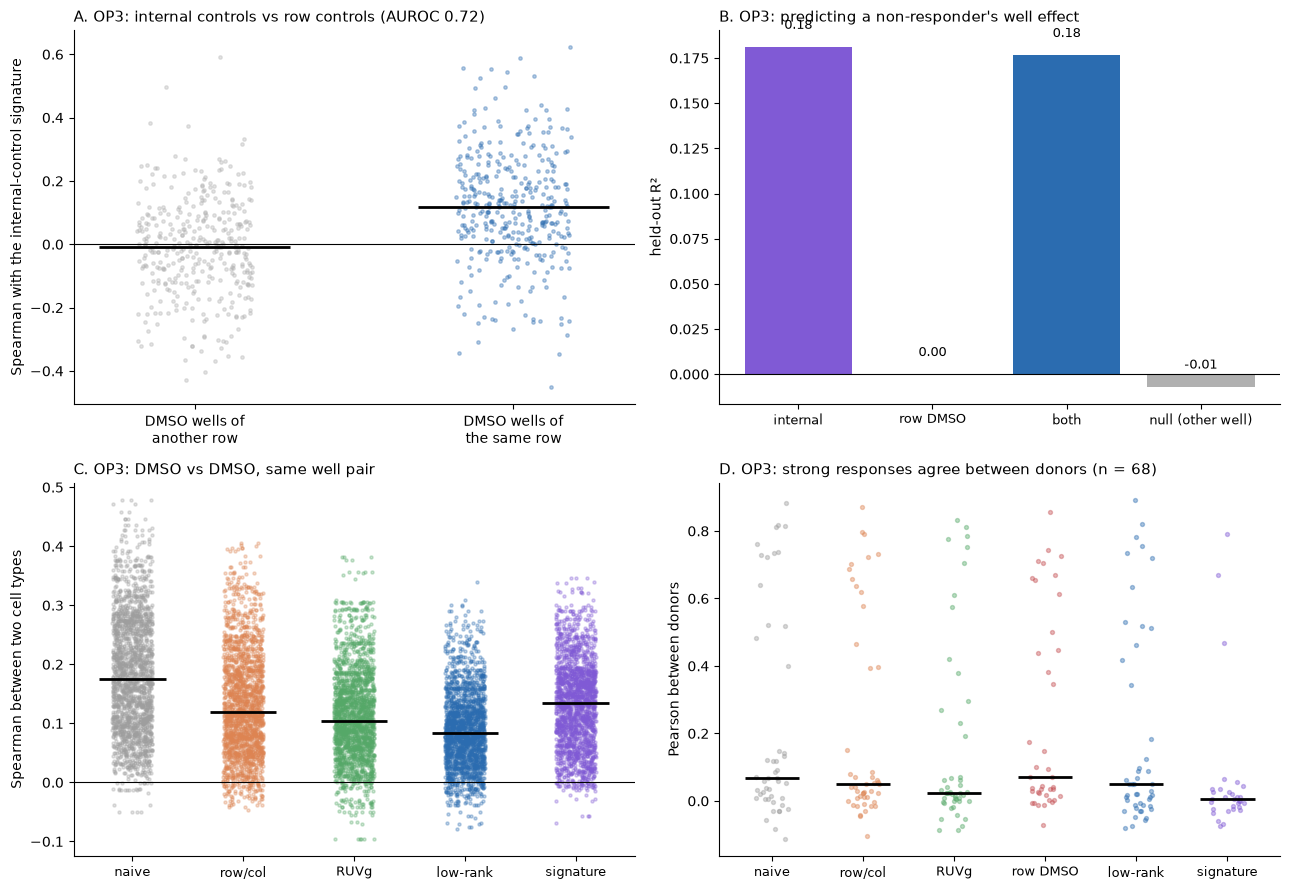

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_extend_analysis/aim2_op3_tests.png True


In [42]:
CM = {"naive": "#9e9e9e", "row/col": "#dd8452", "RUVg": "#55a868", "row DMSO": "#c44e52",
      "low-rank": "#2b6cb0", "signature": "#805ad5"}
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
a = ax[0, 0]
for i, (col_, lab) in enumerate([("other_row", "other row"), ("same_row", "same row")]):
    v = A1[col_].dropna().values
    a.scatter(i + np.random.default_rng(SEED + i).uniform(-.18, .18, len(v)), v, s=6, alpha=.35,
              color=["#b0b0b0", "#2b6cb0"][i])
    a.hlines(np.median(v), i - .3, i + .3, color="k", lw=2)
a.axhline(0, color="k", lw=.8)
a.set_xticks([0, 1]); a.set_xticklabels(["DMSO wells of\nanother row", "DMSO wells of\nthe same row"])
a.set_ylabel("Spearman with the internal-control signature")
a.set_title(f"A. OP3: internal controls vs row controls (AUROC {auroc(A1.same_row, A1.other_row):.2f})", loc="left", fontsize=11)

a = ax[0, 1]
a.bar(range(len(A2)), A2.values, color=["#805ad5", "#c44e52", "#2b6cb0", "#b0b0b0"])
for i, v in enumerate(A2.values):
    a.text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
a.set_xticks(range(len(A2))); a.set_xticklabels(A2.index, fontsize=9)
a.axhline(0, color="k", lw=.8); a.set_ylabel("held-out R²")
a.set_title("B. OP3: predicting a non-responder's well effect", loc="left", fontsize=11)

a = ax[1, 0]
for i, r in A3.reset_index(drop=True).iterrows():
    v = r.dist[~np.isnan(r.dist)]
    a.scatter(i + np.random.default_rng(SEED + i).uniform(-.18, .18, len(v)), v, s=5, alpha=.3, color=CM[r.method])
    a.hlines(np.median(v), i - .3, i + .3, color="k", lw=2)
a.axhline(0, color="k", lw=.8)
a.set_xticks(range(len(A3))); a.set_xticklabels(A3.method, fontsize=9)
a.set_ylabel("Spearman between two cell types")
a.set_title("C. OP3: DMSO vs DMSO, same well pair", loc="left", fontsize=11)

a = ax[1, 1]
for i, r in A4.reset_index(drop=True).iterrows():
    v = r.dist[~np.isnan(r.dist)]
    a.scatter(i + np.random.default_rng(SEED + i).uniform(-.18, .18, len(v)), v, s=8, alpha=.4, color=CM[r.method])
    if len(v): a.hlines(np.median(v), i - .3, i + .3, color="k", lw=2)
a.set_xticks(range(len(A4))); a.set_xticklabels(A4.method, fontsize=9)
a.set_ylabel("Pearson between donors")
a.set_title(f"D. OP3: strong responses agree between donors (n = {len(TOP3)})", loc="left", fontsize=11)
for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "aim2_op3_tests.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))

# Part B. Tahoe: all available plates
## B0. Which plates are complete?
A plate is used only if its file is complete (size equal to the bucket listing; if the listing cannot be read, the file must open). Plates 6, 13 and 14 use their cached pseudobulks.

In [43]:
t0 = time.time()
try:
    import urllib.request
    items = json.load(urllib.request.urlopen(BUCKET_LIST, timeout=20)).get("items", [])
    EXPECTED = {it["name"].split("/")[-1]: int(it["size"]) for it in items if it["name"].endswith(".h5ad")}
except Exception as ex:
    EXPECTED = {}
    print("Bucket listing not available:", type(ex).__name__)


def plate_ready(plate):
    if os.path.exists(os.path.join(TAHOE_PB_DIR, f"pseudobulk_{plate}.h5ad")):
        return True
    f = [x for x in os.listdir(TAHOE_H5AD_DIR) if x.startswith(plate + "_") and x.endswith(".h5ad")] if os.path.isdir(TAHOE_H5AD_DIR) else []
    if len(f) != 1:
        return False
    path = os.path.join(TAHOE_H5AD_DIR, f[0])
    if f[0] in EXPECTED:
        return os.path.getsize(path) == EXPECTED[f[0]]
    try:
        ad.read_h5ad(path, backed="r").file.close()
        return True
    except Exception:
        return False


ALL_PLATES = [f"plate{i}" for i in range(1, 15)]
PLATES = [p for p in ALL_PLATES if plate_ready(p)]
print("Plates used:", PLATES)
print("Not ready:", [p for p in ALL_PLATES if p not in PLATES])
stamp(t0, "plate check")

Plates used: ['plate1', 'plate2', 'plate3', 'plate4', 'plate5', 'plate6', 'plate7', 'plate8', 'plate9', 'plate10', 'plate11', 'plate12', 'plate13', 'plate14']
Not ready: []
[plate check] 0.2s | total 0.4 min


## B1. Pseudobulk per (plate, sample, cell line)
Same function as the Tahoe feasibility notebook, same cache folder. About 10 to 30 minutes per new plate, once.

In [44]:
def plate_file(plate):
    f = [x for x in os.listdir(TAHOE_H5AD_DIR) if x.startswith(plate + "_") and x.endswith(".h5ad")]
    assert len(f) == 1, f"{plate}: found {f}"
    return os.path.join(TAHOE_H5AD_DIR, f[0])


def pseudobulk_plate(plate):
    path = os.path.join(TAHOE_PB_DIR, f"pseudobulk_{plate}.h5ad")
    if os.path.exists(path):
        print(f"{plate}: loaded cache")
        return ad.read_h5ad(path)
    os.makedirs(TAHOE_PB_DIR, exist_ok=True)
    a = ad.read_h5ad(plate_file(plate), backed="r")
    line_col = "cell_name" if "cell_name" in a.obs.columns else "cell_line"
    o = a.obs[["sample", line_col]].astype(str)
    if "pass_filter" in a.obs.columns:
        keep = a.obs["pass_filter"].astype(str).isin(["full", "True", "true", "1"])
        if keep.mean() > 0.2:
            o.loc[~keep.values, "sample"] = np.nan
            print(f"{plate}: keeping pass_filter cells ({keep.mean():.0%})")
    key = (o["sample"] + "|" + o[line_col]).where(o["sample"].notna())
    codes, groups = pd.factorize(key)
    acc = np.zeros((len(groups), a.n_vars), dtype=np.float32)
    t0 = time.time()
    for s in range(0, a.n_obs, CHUNK):
        e = min(s + CHUNK, a.n_obs)
        c = codes[s:e]
        m = c >= 0
        if m.any():
            X = a.X[s:e]
            X = X if sp.issparse(X) else sp.csr_matrix(X)
            X = X[np.where(m)[0]]
            ug, local = np.unique(c[m], return_inverse=True)
            Gm = sp.csr_matrix((np.ones(len(local), dtype=np.float32), (local, np.arange(len(local)))),
                               shape=(len(ug), len(local)))
            acc[ug] += np.asarray((Gm @ X).todense(), dtype=np.float32)
        if (s // CHUNK) % 25 == 0 or e == a.n_obs:
            el = time.time() - t0
            print(f"  {plate}: {e:,} / {a.n_obs:,} cells ({e / a.n_obs:.0%}) | elapsed {el / 60:.1f} min | "
                  f"remaining ~{el / e * (a.n_obs - e) / 60:.0f} min", flush=True)
    meta = pd.DataFrame([g.split("|") for g in groups], columns=["sample", "line"])
    meta["n_cells"] = np.bincount(codes[codes >= 0], minlength=len(groups))
    meta["plate"] = plate
    meta.index = [f"{plate}_{i}" for i in range(len(groups))]
    pb = ad.AnnData(X=sp.csr_matrix(acc), obs=meta, var=pd.DataFrame(index=a.var_names.astype(str)))
    a.file.close()
    pb.write_h5ad(path)
    print(f"{plate}: saved {pb.shape} | {(time.time() - t0) / 60:.1f} min")
    return pb


t0 = time.time()
PBT = {p: pseudobulk_plate(p) for p in PLATES}
stamp(t0, "Tahoe pseudobulks")

plate1: loaded cache
plate2: loaded cache
plate3: loaded cache
plate4: loaded cache
plate5: loaded cache
plate6: loaded cache
plate7: loaded cache
plate8: loaded cache
plate9: loaded cache
plate10: loaded cache
plate11: loaded cache
plate12: loaded cache
plate13: loaded cache
plate14: loaded cache
[Tahoe pseudobulks] 19.1s | total 0.7 min


In [46]:
# B25. Doublets: is the shared well signal of Tahoe-100M made by doublets?
# In split-pool barcoding two cells can share all barcodes only if they were in the same first-round well, so doublets
# (and barcode collisions) are confined to a well and would create a signal shared by the cell lines of that well.
# Cells of different lines are separated by genotype in Tahoe, so the doublets left are mostly two cells of the same
# line, which carry about twice the transcripts of a single cell. Proxy: within each (sample, line), a cell is a
# doublet candidate if its transcript count is above twice the median of that (sample, line).
# Three pseudobulks per plate, from the same cells that pass the released filter: all cells, without the
# candidates ("clean"), and the candidates only. Tests on each (no responder masks needed):
#   Test R: for every well and line, d = profile on plate 6 minus profile on plate 14 (same drug, same position),
#           centred per line over wells; Spearman between two lines of the same well vs of different wells.
#   Test A: within each plate, H11 minus H12 (the two DMSO wells) per line; Spearman between two lines,
#           same plate vs one line from each plate.
# Fixed before running: doublets do not explain the shared signal if, without the candidates, the same-well excess
# (same minus different) keeps at least 80% of its value with all cells in both tests.
# Needs: the setup cell and the B1 function cell (plate_file, TAHOE_H5AD_DIR, CHUNK, MIN_CELLS, to_cpm, stamp).
# Run time: about 10 minutes per plate (one pass over the cells).
t0 = time.time()
PLATES_D = ["plate6", "plate14"]
DBL_FOLD = 2.0
DB_DIR = os.path.join(OUT_DIR, "doublets")
os.makedirs(DB_DIR, exist_ok=True)


def pick(cols, options):
    for c in options:
        if c in cols:
            return c
    raise KeyError(f"none of {options} in obs")


def pseudobulk_doublet_split(plate):
    paths = {k: os.path.join(DB_DIR, f"pb_{plate}_{k}.h5ad") for k in ["all", "clean", "doublet"]}
    if all(os.path.exists(p) for p in paths.values()):
        print(f"{plate}: loaded cache")
        return {k: ad.read_h5ad(p) for k, p in paths.items()}
    a = ad.read_h5ad(plate_file(plate), backed="r")
    cols = a.obs.columns
    line_col = pick(cols, ["cell_name", "cell_line"])
    umi_col = pick(cols, ["tscp_count", "total_counts", "n_counts", "nCount_RNA"])
    o = a.obs[["sample", line_col, umi_col]].copy()
    o.columns = ["sample", "line", "umi"]
    o["sample"], o["line"] = o["sample"].astype(str), o["line"].astype(str)
    keep = np.ones(len(o), bool)
    if "pass_filter" in cols:
        kf = a.obs["pass_filter"].astype(str).isin(["full", "True", "true", "1"]).values
        if kf.mean() > 0.2:
            keep = kf
    med = o[keep].groupby(["sample", "line"], observed=True).umi.transform("median")
    is_dbl = np.zeros(len(o), bool)
    is_dbl[np.where(keep)[0]] = (o.umi.values[keep] > DBL_FOLD * med.values)
    print(f"{plate}: {keep.sum():,} cells pass the filter | doublet candidates {is_dbl[keep].mean():.1%} "
          f"(UMI above {DBL_FOLD}x the median of their sample and line)")
    key = (o["sample"] + "|" + o["line"]).values
    codes, groups = pd.factorize(key)
    cls = np.where(~keep, -1, np.where(is_dbl, 1, 0))           # -1 dropped, 0 single, 1 candidate
    acc = {0: np.zeros((len(groups), a.n_vars), np.float32), 1: np.zeros((len(groups), a.n_vars), np.float32)}
    t1 = time.time()
    for s in range(0, a.n_obs, CHUNK):
        e = min(s + CHUNK, a.n_obs)
        X = a.X[s:e]; X = X if sp.issparse(X) else sp.csr_matrix(X)
        for k in (0, 1):
            m = np.where(cls[s:e] == k)[0]
            if len(m):
                ug, local = np.unique(codes[s:e][m], return_inverse=True)
                Gm = sp.csr_matrix((np.ones(len(local), np.float32), (local, np.arange(len(local)))), shape=(len(ug), len(local)))
                acc[k][ug] += np.asarray((Gm @ X[m]).todense(), dtype=np.float32)
        if (s // CHUNK) % 50 == 0 or e == a.n_obs:
            el = time.time() - t1
            print(f"  {plate}: {e / a.n_obs:.0%} | {el / 60:.1f} min | remaining ~{el / e * (a.n_obs - e) / 60:.0f} min", flush=True)
    meta = pd.DataFrame([g.split("|") for g in groups], columns=["sample", "line"])
    out = {}
    for name, X, n in [("all", acc[0] + acc[1], np.bincount(codes[cls >= 0], minlength=len(groups))),
                       ("clean", acc[0], np.bincount(codes[cls == 0], minlength=len(groups))),
                       ("doublet", acc[1], np.bincount(codes[cls == 1], minlength=len(groups)))]:
        mm = meta.copy(); mm["n_cells"] = n; mm["plate"] = plate; mm.index = [f"{plate}_{i}" for i in range(len(mm))]
        out[name] = ad.AnnData(X=sp.csr_matrix(X), obs=mm, var=pd.DataFrame(index=a.var_names.astype(str)))
        out[name].write_h5ad(paths[name])
    a.file.close()
    return out


PBD = {p: pseudobulk_doublet_split(p) for p in PLATES_D}
stamp(t0, "doublet pseudobulks")

# ---- tensors: same lines and genes for all three versions; wells from the barcode map
wmapD = pd.read_csv(TAHOE_MAP_BARCODE); wmapD["sample"] = wmapD["sample"].astype(str)
WELLS96 = [r + str(c) for r in "ABCDEFGH" for c in range(1, 13)]
base = {p: PBD[p]["all"] for p in PLATES_D}
okl = [set(b.obs.line[b.obs.n_cells >= MIN_CELLS["tahoe"]]) for b in base.values()]
LINES_D = sorted(set.intersection(*okl))
cp_all = {p: to_cpm(b.X) for p, b in base.items()}
mean_l = np.vstack([np.asarray(cp_all[PLATES_D[0]][np.where(base[PLATES_D[0]].obs.line.values == l)[0]].mean(0)).ravel() for l in LINES_D])
GEN_D = np.argsort(-mean_l.min(0))[:N_GENES]


def tensor(b, plate, min_cells):
    ob = b.obs.copy(); ob["sample"] = ob["sample"].astype(str)
    mp = wmapD[wmapD.plate == plate].drop_duplicates("sample").set_index("sample").well
    cp = to_cpm(b.X)[:, GEN_D].toarray()
    Y = np.full((96, len(LINES_D), len(GEN_D)), np.nan, np.float32)
    li_ = {l: i for i, l in enumerate(LINES_D)}
    for i, (s, l, n) in enumerate(zip(ob["sample"], ob.line, ob.n_cells)):
        w = mp.get(s)
        if w in WELLS96 and l in li_ and n >= min_cells:
            Y[WELLS96.index(w), li_[l]] = np.log2(cp[i] + 1)
    return Y


def spear_pairs(D, same=True, n=3000, seed=SEED):
    """D [K, C, G]; Spearman of two lines, same well (same=True) or different wells."""
    rng = np.random.default_rng(seed); out = []
    K, C, _ = D.shape
    for _ in range(n):
        k = rng.integers(K); a, b = rng.choice(C, 2, replace=False)
        k2 = k if same else rng.integers(K)
        if np.isnan(D[k, a, 0]) or np.isnan(D[k2, b, 0]) or (not same and k2 == k):
            continue
        out.append(spearmanr(D[k, a], D[k2, b])[0])
    return np.nanmedian(out) if out else np.nan          # nan from a constant vector is skipped


rows = []
for version, min_cells in [("all", MIN_CELLS["tahoe"]), ("clean", MIN_CELLS["tahoe"]), ("doublet", 5)]:
    Y = {p: tensor(PBD[p][version], p, min_cells) for p in PLATES_D}
    d = Y["plate6"] - Y["plate14"]
    d = d - np.nanmean(d, 0, keepdims=True)                         # centre per line over wells
    r_same, r_diff = spear_pairs(d, True), spear_pairs(d, False)
    A = {p: (Y[p][WELLS96.index("H11")] - Y[p][WELLS96.index("H12")])[None] for p in PLATES_D}
    a_same = np.nanmedian([spear_pairs(A[p], True, n=1000) for p in PLATES_D])
    rng = np.random.default_rng(SEED); cross = []
    for _ in range(1000):
        x, y = rng.choice(len(LINES_D), 2, replace=False)
        u, v = A["plate6"][0, x], A["plate14"][0, y]
        if not (np.isnan(u[0]) or np.isnan(v[0])):
            cross.append(spearmanr(u, v)[0])
    a_diff = np.nanmedian(cross)
    n_obs = np.mean(~np.isnan(Y["plate6"][..., 0]))
    rows.append(dict(version=version, entries_observed=n_obs, testR_same=r_same, testR_diff=r_diff,
                     testR_excess=r_same - r_diff, testA_same=a_same, testA_cross=a_diff, testA_excess=a_same - a_diff))
DBL = pd.DataFrame(rows).set_index("version")
DBL.to_csv(os.path.join(DB_DIR, "doublet_tests.csv"))
print(DBL.round(3).to_string())
keepR = DBL.loc["clean", "testR_excess"] / DBL.loc["all", "testR_excess"]
keepA = DBL.loc["clean", "testA_excess"] / DBL.loc["all", "testA_excess"]
print(f"\nExcess kept without doublet candidates: Test R {keepR:.0%}, Test A {keepA:.0%}")
print(f"Fixed rule (>= 80% in both): doublets do not explain the shared signal: {bool(keepR >= 0.8 and keepA >= 0.8)}")
stamp(t0, "doublet tests")

plate6: loaded cache
plate14: loaded cache
[doublet pseudobulks] 22.7s | total 38.2 min


/tmp/ipykernel_528573/1404431226.py:118: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  out.append(spearmanr(D[k, a], D[k2, b])[0])


         entries_observed  testR_same  testR_diff  testR_excess  testA_same  testA_cross  testA_excess
version                                                                                               
all                 0.983       0.329         0.0         0.329       0.513        0.002         0.511
clean               0.980       0.300         0.0         0.300       0.483        0.002         0.480
doublet             0.976       0.125         0.0         0.125       0.207        0.002         0.204

Excess kept without doublet candidates: Test R 91%, Test A 94%
Fixed rule (>= 80% in both): doublets do not explain the shared signal: True
[doublet tests] 34.5s | total 38.4 min


## B2. Tahoe tensors
* Sample to well and drug: the barcode map for plates 6, 13 and 14 (verified), the inferred map for the other plates. Well positions are used only by the row/col baseline; the internal-control model needs only which cells share a well.
* Cell lines: at least `MIN_CELLS` cells in at least 80% of the wells of every plate used. Genes: the `N_GENES` genes with the highest minimum mean CPM across those lines.

In [15]:
t0 = time.time()
wm = pd.read_csv(TAHOE_MAP_INFERRED)
if os.path.exists(TAHOE_MAP_BARCODE):
    wb = pd.read_csv(TAHOE_MAP_BARCODE)
    wm = pd.concat([wm[~wm.plate.isin(wb.plate.unique())], wb[["plate", "sample", "well", "drug"]]], ignore_index=True)
wm["sample"] = wm["sample"].astype(str)
genes_common = None
TP = {}
for p, b in PBT.items():
    ob = b.obs.copy()
    ob["sample"], ob["line"] = ob["sample"].astype(str), ob["line"].astype(str)
    mp = wm[wm.plate == p].drop_duplicates("sample").set_index("sample")
    ob["well"], ob["drug"] = ob["sample"].map(mp.well), ob["sample"].map(mp.drug).astype(str)
    TP[p] = (ob.reset_index(drop=True), b)
    genes_common = set(b.var_names) if genes_common is None else genes_common & set(b.var_names)
genes_common = sorted(genes_common)
cov = pd.concat([ob[ob.n_cells >= MIN_CELLS["tahoe"]].groupby("line")["sample"].nunique() / ob["sample"].nunique()
                 for ob, _ in TP.values()], axis=1)
LINES = sorted(cov.index[(cov.fillna(0) >= 0.8).all(axis=1)])
li = {l: i for i, l in enumerate(LINES)}
CP = {p: to_cpm(b[:, genes_common].X) for p, (ob, b) in TP.items()}
sum_l = np.zeros((len(LINES), len(genes_common))); cnt = np.zeros(len(LINES))
for p, (ob, _) in TP.items():
    for l in LINES:
        r_ = np.where((ob.line.values == l) & (ob.n_cells.values >= MIN_CELLS["tahoe"]))[0]
        sum_l[li[l]] += np.asarray(CP[p][r_].sum(0)).ravel(); cnt[li[l]] += len(r_)
tg = np.argsort(-(sum_l / np.maximum(cnt, 1)[:, None]).min(0))[:N_GENES]

TAH = {}
for p, (ob, _) in TP.items():
    smp = sorted(ob["sample"].unique(), key=lambda s: (str(ob[ob["sample"] == s].well.iat[0]), s))
    si = {s: i for i, s in enumerate(smp)}
    cp = CP[p][:, tg].toarray()
    Y = np.full((1, len(smp), len(LINES), len(tg)), np.nan, np.float32)
    for i, (s, l, n) in enumerate(zip(ob["sample"], ob.line, ob.n_cells)):
        if l in li and n >= MIN_CELLS["tahoe"]:
            Y[0, si[s], li[l]] = np.log2(cp[i] + 1)
    first = ob.drop_duplicates("sample").set_index("sample")
    well = np.array([str(first.well.get(s, "")) for s in smp])
    drugs = np.array([parent(first.drug.get(s, "")) for s in smp])
    #drugs = np.array([str(first.drug.get(s, "")) for s in smp])
    ok_w = np.array([bool(re.fullmatch(r"[A-H]\d{1,2}", w)) for w in well])
    row = np.where(ok_w, [("ABCDEFGH".index(w[0]) if ok else -1) for w, ok in zip(well, ok_w)], -1)[None]
    col = np.where(ok_w, [(int(w[1:]) - 1 if ok else -1) for w, ok in zip(well, ok_w)], -1)[None]
    ref = (drugs == "DMSO_TF")[None]
    TAH[p] = dict(Y=Y, well=well, drug=drugs, ref=ref, row=row, col=col)
    print(f"{p}: samples {len(smp)} | DMSO wells {ref.sum()} | wells with a position {ok_w.mean():.0%} | "
          f"observed {np.mean(~np.isnan(Y[..., 0])):.1%}")
print("Cell lines:", len(LINES), "| genes:", len(tg))
del CP
stamp(t0, "Tahoe tensors")

plate1: samples 96 | DMSO wells 2 | wells with a position 100% | observed 90.2%
plate2: samples 96 | DMSO wells 2 | wells with a position 100% | observed 96.5%
plate3: samples 96 | DMSO wells 2 | wells with a position 100% | observed 99.2%
plate4: samples 96 | DMSO wells 2 | wells with a position 100% | observed 100.0%
plate5: samples 96 | DMSO wells 2 | wells with a position 100% | observed 100.0%
plate6: samples 96 | DMSO wells 2 | wells with a position 100% | observed 100.0%
plate7: samples 96 | DMSO wells 2 | wells with a position 100% | observed 100.0%
plate8: samples 96 | DMSO wells 2 | wells with a position 100% | observed 100.0%
plate9: samples 96 | DMSO wells 2 | wells with a position 100% | observed 99.9%
plate10: samples 96 | DMSO wells 2 | wells with a position 100% | observed 100.0%
plate11: samples 96 | DMSO wells 2 | wells with a position 100% | observed 100.0%
plate12: samples 96 | DMSO wells 2 | wells with a position 100% | observed 100.0%
plate13: samples 96 | DMSO we

## B3. Run all methods, plate by plate
Responders are called on the plate itself (low-rank model). This replaces the cross-fitting of plates 6 and 14 used in `aim2_model_real_data.ipynb`, so that every plate is treated the same way; their numbers can therefore differ slightly from section 22 there.

In [16]:
t0 = time.time()
RUN = {}
for p, T in TAH.items():
    print(p, end=": ")
    RUN[p] = run_all(T["Y"], T["ref"], T["row"], T["col"], MIN_CONTROLS["tahoe"])
    out, nr, info, fl = RUN[p]
    act = ~T["ref"][0]
    obs = ~np.isnan(T["Y"][0, :, :, 0])
    print(f"    responders {(~nr[0][act][obs[act]]).mean():.1%} | flagged entries {fl[0][act][obs[act]].mean():.1%}")
METHODS_T = list(next(iter(RUN.values()))[0])
stamp(t0, "Tahoe methods")

plate1: [all methods] 8.1s | total 33.2 min
    responders 7.7% | flagged entries 2.0%
plate2: [all methods] 8.7s | total 33.3 min
    responders 8.4% | flagged entries 2.0%
plate3: [all methods] 8.1s | total 33.4 min
    responders 12.0% | flagged entries 4.2%
plate4: [all methods] 9.0s | total 33.6 min
    responders 7.7% | flagged entries 3.1%
plate5: [all methods] 8.9s | total 33.7 min
    responders 9.6% | flagged entries 4.4%
plate6: [all methods] 9.0s | total 33.9 min
    responders 10.1% | flagged entries 5.3%
plate7: [all methods] 9.1s | total 34.0 min
    responders 7.8% | flagged entries 3.1%
plate8: [all methods] 8.7s | total 34.2 min
    responders 13.0% | flagged entries 6.4%
plate9: [all methods] 8.7s | total 34.3 min
    responders 13.7% | flagged entries 8.4%
plate10: [all methods] 9.1s | total 34.5 min
    responders 11.3% | flagged entries 2.2%
plate11: [all methods] 8.8s | total 34.6 min
    responders 10.8% | flagged entries 5.3%
plate12: [all methods] 8.5s | total

## B4. Genotype test with the targeted variants
Same rules as section 22 of `aim2_model_real_data.ipynb`. For each well of a targeted drug: AUROC of response size, carriers vs non-carriers (0.5 = no separation). Also a paired test across drugs: does the final model change the AUROC compared with the naive analysis?

In [17]:
VARIANT_RULES = {
    "KRAS G12C": (["adagrasib", "sotorasib", "divarasib"], {"KRAS"}, r"G12C"),
    "KRAS G12D": (["mrtx1133"], {"KRAS"}, r"G12D"),
    "EGFR activating": (["osimertinib", "almonertinib", "erlotinib", "gefitinib", "afatinib", "dacomitinib",
                         "lazertinib", "furmonertinib", "icotinib", "aumolertinib", "befotertinib"],
                        {"EGFR"}, r"L858R|T790M|G719|L861Q|E746|L747|del|ins"),
    "BRAF V600": (["vemurafenib", "dabrafenib", "encorafenib"], {"BRAF"}, r"V600"),
    "MAPK active": (["trametinib", "cobimetinib", "binimetinib", "selumetinib", "mirdametinib"],
                    {"BRAF", "KRAS", "NRAS", "HRAS"}, r"V600|G12|G13|Q61"),
    "PIK3CA hotspot": (["alpelisib", "inavolisib"], {"PIK3CA"}, r"H1047|E545|E542"),
}
t0 = time.time()
CL = pd.read_parquet(os.path.join(TAHOE_META, "cell_line_metadata.parquet"))
var = {l: list(zip(g.Driver_Gene_Symbol.astype(str).str.upper(), g.Driver_ProtEffect_or_CdnaEffect.astype(str)))
       for l, g in CL.groupby(CL.cell_name.astype(str))}


def rule_for(drug):
    d = str(drug).lower()
    for name, rule in VARIANT_RULES.items():
        if any(x in d for x in rule[0]):
            return name, rule
    return None, None


def carriers(rule):
    _, genes, rx = rule
    return np.array([any(g in genes and re.search(rx, e) for g, e in var.get(l, [])) for l in LINES])


rows = []
for p, T in TAH.items():
    out, nr, info, fl = RUN[p]
    R = {m: contrast(out[m], T["ref"])[0] for m in METHODS_T}
    for k, d in enumerate(T["drug"]):
        name, rule = rule_for(d)
        if rule is None or T["ref"][0, k]:
            continue
        car = carriers(rule)
        if car.sum() < 2 or (~car).sum() < 2:
            continue
        row = dict(plate=p, well=T["well"][k], drug=d, variant=name, n_carriers=int(car.sum()),
                   n_flagged=int(fl[0, k].sum()), n_responders=int((~nr[0, k]).sum()))
        for m in METHODS_T:
            sz = np.linalg.norm(R[m][k], axis=-1)
            row[m] = auroc(sz[car], sz[~car])
        rows.append(row)
GENO = pd.DataFrame(rows)
GENO.to_csv(os.path.join(OUT_DIR, "tahoe_genotype_variants_all_plates.csv"), index=False)
print(GENO.round(3).to_string(index=False))
print("\nMedian AUROC by variant:")
print(GENO.groupby("variant")[METHODS_T].median().round(3).to_string())
print("\nMedian AUROC, all drug wells:", GENO[METHODS_T].median().round(3).to_dict())
pair = GENO[["naive", "signature"]].dropna()
if len(pair) >= 5 and (pair.signature != pair.naive).any():
    print(f"Signature vs naive: higher in {(pair.signature > pair.naive).mean():.0%} of {len(pair)} wells | "
          f"median change {(pair.signature - pair.naive).median():+.3f} | Wilcoxon p = {wilcoxon(pair.signature, pair.naive).pvalue:.2g}")
stamp(t0, "genotype test")

  plate well        drug        variant  n_carriers  n_flagged  n_responders  naive  row/col  RUVg  low-rank  signature
 plate1  A10   Alpelisib PIK3CA hotspot           4          0             5  0.401    0.390 0.442     0.419      0.430
 plate1  B12 Binimetinib    MAPK active          35          0            31  0.593    0.595 0.474     0.693      0.588
 plate1   B9 Vemurafenib      BRAF V600           7          0             0  0.525    0.500 0.604     0.536      0.496
 plate1  C11  Trametinib    MAPK active          35          0             4  0.460    0.419 0.467     0.467      0.462
 plate1   C7  Dabrafenib      BRAF V600           7          0             1  0.625    0.643 0.643     0.582      0.707
 plate1   C8 Encorafenib      BRAF V600           7          0             0  0.504    0.436 0.529     0.425      0.511
 plate1  H10   Adagrasib      KRAS G12C           5          0             5  0.886    0.862 0.667     0.895      0.905
 plate2  A10   Alpelisib PIK3CA hotspot 

## B5. Technical similarity and agreement between plates
* **Technical similarity**: responses of two non-responding cell lines in the same treated, unflagged well, vs two lines from different wells (Spearman). The signature model corrects both lines with a signature that excludes both. Should drop toward zero.
* **Agreement between plates**: a drug on several plates (different plates, often a different dose). For strong (drug, line) pairs (top `TOP_FRAC` of the mean size rank over all methods), the mean Pearson between plates should be kept.

In [18]:
t0 = time.time()
rows = []
for p, T in TAH.items():
    out, nr, info, fl = RUN[p]
    keep = nr[0] & ~fl[0] & ~np.isnan(T["Y"][0, :, :, 0])
    keep[T["ref"][0]] = False
    units = [(k, c) for k, c in zip(*np.where(keep))]
    if len(units) < 50:
        continue
    for m in METHODS_T:
        R = contrast(out[m], T["ref"])[0]
        rng = np.random.default_rng(SEED)
        same, dif, tries = [], [], 0
        while len(same) < N_PAIRS // 4 and tries < 50 * N_PAIRS:
            tries += 1
            k, a = units[rng.integers(len(units))]
            bs = [c for c in np.where(keep[k])[0] if c != a]
            if not bs:
                continue
            b = rng.choice(bs)
            k2, b2 = units[rng.integers(len(units))]
            if k2 == k:
                continue
            if m == "signature":
                pr = sig_pair(info, 0, k, a, b)
                if pr is None:
                    continue
                ref_mean = np.nanmean(out[m][0, T["ref"][0]], 0)
                ra, rb = pr[0] - ref_mean[a], pr[1] - ref_mean[b]
            else:
                ra, rb = R[k, a], R[k, b]
            if np.isnan(ra[0] + rb[0] + R[k2, b2, 0]):
                continue
            same.append(spearmanr(ra, rb)[0]); dif.append(spearmanr(ra, R[k2, b2])[0])
        rows.append(dict(plate=p, method=m, same_well=np.median(same), different_well=np.median(dif), n=len(same)))
TECH = pd.DataFrame(rows)
TECH.to_csv(os.path.join(OUT_DIR, "tahoe_technical_similarity.csv"), index=False)
print(TECH.pivot(index="plate", columns="method", values="same_well").round(3).to_string())

# agreement between plates for the same drug
RT = {p: {m: contrast(RUN[p][0][m], TAH[p]["ref"])[0] for m in METHODS_T} for p in TAH}
multi = pd.DataFrame([(p, d, k) for p, T in TAH.items() for k, d in enumerate(T["drug"]) if not T["ref"][0, k]],
                     columns=["plate", "drug", "k"])
multi = multi[multi.groupby("drug").plate.transform("nunique") >= 2]
rows, n_top = [], 0
if len(multi):
    drugs_m = sorted(multi.drug.unique())
    size = {m: np.array([[np.nanmean([np.linalg.norm(RT[p][m][k, c]) for p, k in zip(g.plate, g.k)])
                          for c in range(len(LINES))] for _, g in [(d, multi[multi.drug == d]) for d in drugs_m]])
            for m in METHODS_T}
    top = strong_pairs(size)
    n_top = int(top.sum())
    for m in METHODS_T:
        ag = []
        for i, c in zip(*np.where(top)):
            g = multi[multi.drug == drugs_m[i]]
            prof = [RT[p][m][k, c] for p, k in zip(g.plate, g.k) if not np.isnan(RT[p][m][k, c, 0])]
            if len(prof) >= 2:
                ag.append(np.mean([np.corrcoef(prof[x], prof[y])[0, 1] for x in range(len(prof)) for y in range(x + 1, len(prof))]))
        rows.append(dict(method=m, agreement=np.median(ag) if ag else np.nan, n_pairs=len(ag), dist=np.array(ag)))
AGREE = pd.DataFrame(rows)
if len(AGREE):
    AGREE.drop(columns="dist").to_csv(os.path.join(OUT_DIR, "tahoe_agreement_between_plates.csv"), index=False)
    print(f"\nStrong (drug, line) pairs on >= 2 plates: {n_top}")
    print(AGREE.drop(columns="dist").round(3).to_string(index=False))
else:
    print("\nNo drug on two or more of the plates used.")
stamp(t0, "technical similarity and agreement")

method    RUVg  low-rank  naive  row/col  signature
plate                                              
plate1   0.400     0.389  0.518    0.532      0.012
plate10  0.406     0.404  0.589    0.536      0.012
plate11  0.477     0.435  0.570    0.592      0.012
plate12  0.488     0.453  0.610    0.625      0.002
plate13  0.416     0.398  0.516    0.483      0.004
plate14  0.380     0.346  0.466    0.492     -0.002
plate2   0.429     0.447  0.646    0.629      0.001
plate3   0.385     0.369  0.517    0.505      0.013
plate4   0.393     0.407  0.535    0.635      0.011
plate5   0.430     0.414  0.542    0.526      0.016
plate6   0.478     0.437  0.587    0.575      0.012
plate7   0.368     0.375  0.533    0.528      0.007
plate8   0.447     0.417  0.594    0.605      0.015
plate9   0.400     0.302  0.579    0.535      0.012

Strong (drug, line) pairs on >= 2 plates: 1645
   method  agreement  n_pairs
    naive      0.244     1641
  row/col      0.264     1641
     RUVg      0.207     1641


## B6. Tahoe figure and summary

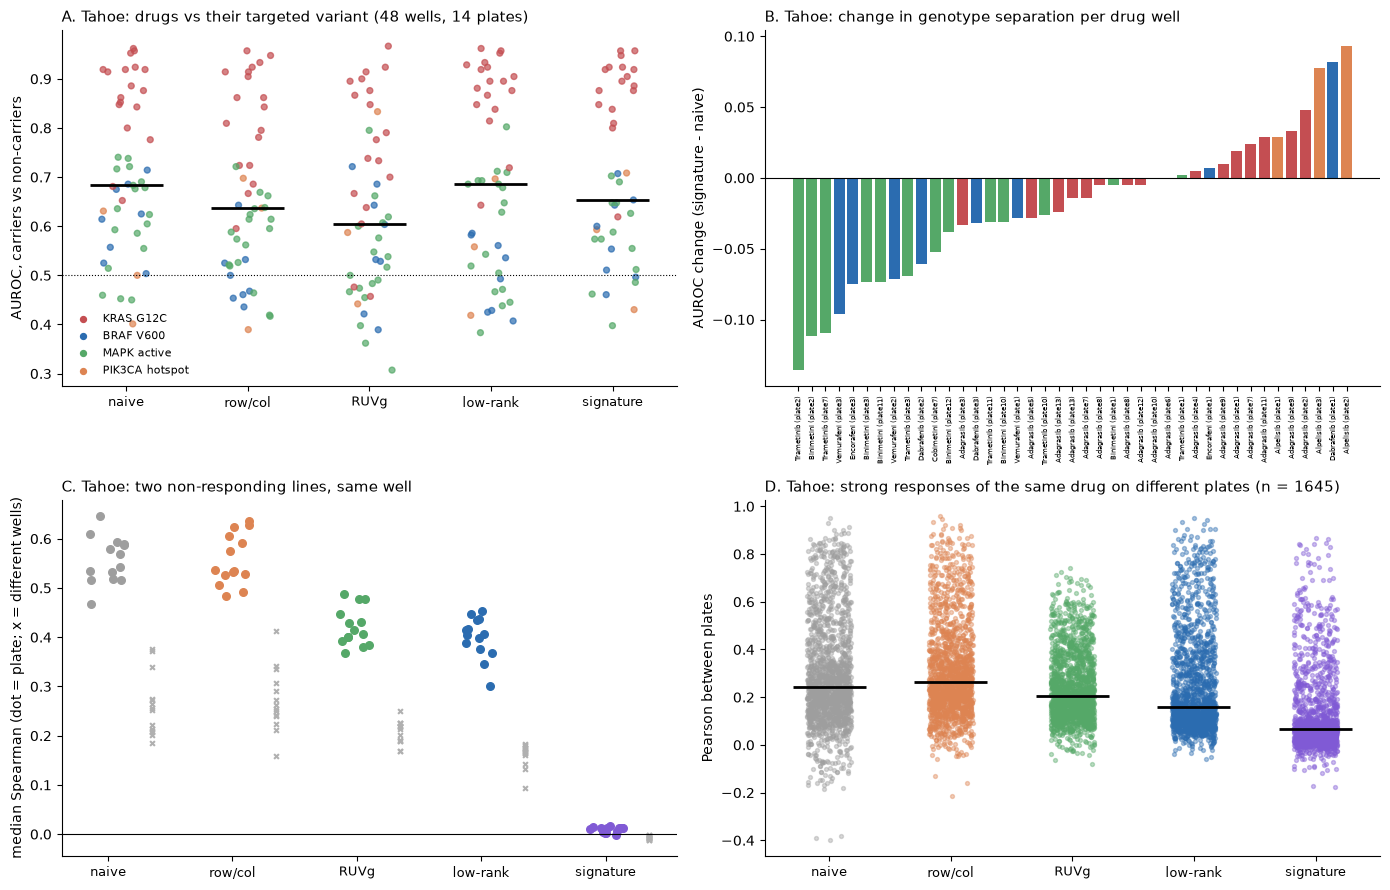

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_extend_analysis/aim2_tahoe_all_plates.png True
{
 "op3": {
  "units": 6,
  "cell_types": [
   "B cells",
   "Myeloid cells",
   "NK cells",
   "T cells CD4+",
   "T cells CD8+"
  ],
  "A1_same_row": 0.1188447552779951,
  "A1_other_row": -0.007361793719515643,
  "A1_auroc": 0.7182433012096429,
  "A1_r2_row": 0.047929945140573804,
  "A2": {
   "internal": 0.1811,
   "row DMSO": 0.0,
   "both": 0.1766,
   "null (other well)": -0.0069
  },
  "A3": {
   "naive": 0.1759,
   "row/col": 0.1185,
   "RUVg": 0.1044,
   "low-rank": 0.0832,
   "signature": 0.1345
  },
  "A4": {
   "naive": 0.0683,
   "row/col": 0.0498,
   "RUVg": 0.0246,
   "row DMSO": 0.0695,
   "low-rank": 0.0488,
   "signature": 0.0047
  }
 },
 "tahoe": {
  "plates": [
   "plate1",
   "plate2",
   "plate3",
   "plate4",
   "plate5",
   "plate6",
   "plate7",
   "plate8",
   "plate9",
   "plate10",
   "plate11",
   "plate12",
   "plate13",
   "plate14"
  ],
  "n_lines"

In [19]:
VC = {"KRAS G12C": "#c44e52", "BRAF V600": "#2b6cb0", "MAPK active": "#55a868", "PIK3CA hotspot": "#dd8452",
      "KRAS G12D": "#8172b2", "EGFR activating": "#937860"}
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
a = ax[0, 0]
if len(GENO):
    for i, m in enumerate(METHODS_T):
        g = GENO[["variant", m]].dropna()
        x = i + np.random.default_rng(SEED + i).uniform(-.2, .2, len(g))
        a.scatter(x, g[m], s=18, alpha=.7, c=[VC.get(v, "k") for v in g.variant])
        a.hlines(g[m].median(), i - .3, i + .3, color="k", lw=2)
    for v, c in VC.items():
        if v in set(GENO.variant):
            a.scatter([], [], color=c, label=v, s=18)
    a.legend(frameon=False, fontsize=8)
a.axhline(.5, color="k", ls=":", lw=.8)
a.set_xticks(range(len(METHODS_T))); a.set_xticklabels(METHODS_T, fontsize=9)
a.set_ylabel("AUROC, carriers vs non-carriers")
a.set_title(f"A. Tahoe: drugs vs their targeted variant ({len(GENO)} wells, {GENO.plate.nunique() if len(GENO) else 0} plates)", loc="left", fontsize=11)

a = ax[0, 1]
if len(GENO):
    g = GENO.assign(delta=GENO.signature - GENO.naive).dropna(subset=["delta"]).sort_values("delta")
    a.bar(range(len(g)), g.delta, color=[VC.get(v, "k") for v in g.variant])
    a.set_xticks(range(len(g))); a.set_xticklabels([f"{d[:10]} ({p})" for d, p in zip(g.drug, g.plate)], rotation=90, fontsize=5)
a.axhline(0, color="k", lw=.8)
a.set_ylabel("AUROC change (signature - naive)")
a.set_title("B. Tahoe: change in genotype separation per drug well", loc="left", fontsize=11)

a = ax[1, 0]
if len(TECH):
    for i, m in enumerate(METHODS_T):
        v = TECH[TECH.method == m]
        a.scatter(np.full(len(v), i) + np.random.default_rng(SEED + i).uniform(-.15, .15, len(v)), v.same_well,
                  color=CM.get(m, "k"), s=30, label=None)
        a.scatter(np.full(len(v), i) + .35, v.different_well, color="#b0b0b0", s=12, marker="x")
a.axhline(0, color="k", lw=.8)
a.set_xticks(range(len(METHODS_T))); a.set_xticklabels(METHODS_T, fontsize=9)
a.set_ylabel("median Spearman (dot = plate; x = different wells)")
a.set_title("C. Tahoe: two non-responding lines, same well", loc="left", fontsize=11)

a = ax[1, 1]
if len(AGREE):
    for i, r in AGREE.reset_index(drop=True).iterrows():
        v = r.dist[~np.isnan(r.dist)]
        a.scatter(i + np.random.default_rng(SEED + i).uniform(-.18, .18, len(v)), v, s=8, alpha=.4, color=CM.get(r.method, "k"))
        if len(v): a.hlines(np.median(v), i - .3, i + .3, color="k", lw=2)
    a.set_xticks(range(len(AGREE))); a.set_xticklabels(AGREE.method, fontsize=9)
a.set_ylabel("Pearson between plates")
a.set_title(f"D. Tahoe: strong responses of the same drug on different plates (n = {n_top})", loc="left", fontsize=11)
for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "aim2_tahoe_all_plates.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))

SUMMARY = dict(
    op3=dict(units=len(UNITS), cell_types=CT3, A1_same_row=float(A1.same_row.median()), A1_other_row=float(A1.other_row.median()),
             A1_auroc=float(auroc(A1.same_row, A1.other_row)), A1_r2_row=float(A1.r2_row.median()),
             A2=A2.round(4).to_dict(), A3=A3.set_index("method").same_pair.round(4).to_dict(),
             A4=A4.set_index("method").agreement.round(4).to_dict()),
    tahoe=dict(plates=PLATES, n_lines=len(LINES), n_drug_wells=len(GENO),
               auroc_median=GENO[METHODS_T].median().round(4).to_dict() if len(GENO) else {},
               auroc_by_variant=GENO.groupby("variant")[METHODS_T].median().round(4).to_dict("index") if len(GENO) else {},
               tech_same_well=TECH.groupby("method").same_well.median().round(4).to_dict() if len(TECH) else {},
               agreement=AGREE.set_index("method").agreement.round(4).to_dict() if len(AGREE) else {}))
with open(os.path.join(OUT_DIR, "summary.json"), "w") as fh:
    json.dump(SUMMARY, fh, indent=1, default=str)
print(json.dumps(SUMMARY, indent=1, default=str))
stamp(T_START, "whole notebook")

In [20]:
# B7. MPAS test: does the correction remove real (shared) biology?
t0 = time.time()
MPAS = ["PHLDA1", "SPRY2", "SPRY4", "DUSP4", "DUSP6", "CCND1", "EPHA2", "EPHA4", "ETV4", "ETV5"]
MPAS_ENSG = {"PHLDA1": "ENSG00000139289", "SPRY2": "ENSG00000136158", "SPRY4": "ENSG00000187678",
             "DUSP4": "ENSG00000120875", "DUSP6": "ENSG00000139318", "CCND1": "ENSG00000110092",
             "EPHA2": "ENSG00000142627", "EPHA4": "ENSG00000116106", "ETV4": "ENSG00000175832",
             "ETV5": "ENSG00000244405"}
gname = pd.Index(genes_common)
base_id = gname.str.split(".").str[0]
idx = [int(np.where(gname == g)[0][0]) if (gname == g).any()
       else (int(np.where(base_id == MPAS_ENSG[g])[0][0]) if (base_id == MPAS_ENSG[g]).any() else None) for g in MPAS]
found = [g for g, i in zip(MPAS, idx) if i is not None]
idx = [i for i in idx if i is not None]
print(f"MPAS genes found: {len(found)} of {len(MPAS)} {found}")

MP = {}          # plate -> method -> [K, C] MPAS change (well minus DMSO)
for p, (ob, b) in TP.items():
    cp = to_cpm(b[:, genes_common].X)[:, idx].toarray()
    T = TAH[p]
    smp = sorted(ob["sample"].unique(), key=lambda s: (str(ob[ob["sample"] == s].well.iat[0]), s))
    si = {s: i for i, s in enumerate(smp)}
    Ym = np.full((1, len(smp), len(LINES), len(idx)), np.nan, np.float32)
    for i, (s, l, n) in enumerate(zip(ob["sample"], ob.line, ob.n_cells)):
        if l in li and n >= MIN_CELLS["tahoe"]:
            Ym[0, si[s], li[l]] = np.log2(cp[i] + 1)
    out, nr, info, fl = RUN[p]
    Ys, inf_m = m_signature(Ym, nr)
    Ys, _ = flag(Ys, inf_m, MIN_CONTROLS["tahoe"])
    MP[p] = {m: np.nanmean(contrast(Y_, T["ref"])[0], -1) for m, Y_ in [("naive", Ym), ("signature", Ys)]}

rows = []
for _, g in GENO.iterrows():
    p, T = g.plate, TAH[g.plate]
    k = int(np.where((T["well"] == g.well) & (T["drug"] == g.drug))[0][0])
    car = carriers(rule_for(g.drug)[1])
    other = [x for x in range(len(T["drug"])) if x != k and not T["ref"][0, x]]
    row = dict(plate=p, drug=g.drug, variant=g.variant, n_carriers=int(car.sum()))
    for m in ["naive", "signature"]:
        M = MP[p][m]
        mu, sd = np.nanmean(M[other], 0), np.nanstd(M[other], 0) + 1e-6
        z = (M[k] - mu) / sd
        row[f"carriers_{m}"] = np.nanmedian(z[car])
        row[f"noncarriers_{m}"] = np.nanmedian(z[~car])
    rows.append(row)
MPAS_RES = pd.DataFrame(rows)
MPAS_RES.to_csv(os.path.join(OUT_DIR, "tahoe_mpas_test.csv"), index=False)
print("Median z of the MPAS change (negative = MAPK output down); one row per drug well")
print(MPAS_RES.round(2).to_string(index=False))
print("\nBy variant (median over wells):")
print(MPAS_RES.groupby("variant")[["carriers_naive", "noncarriers_naive", "carriers_signature", "noncarriers_signature"]].median().round(2).to_string())
stamp(t0, "MPAS test")

MPAS genes found: 10 of 10 ['PHLDA1', 'SPRY2', 'SPRY4', 'DUSP4', 'DUSP6', 'CCND1', 'EPHA2', 'EPHA4', 'ETV4', 'ETV5']
Median z of the MPAS change (negative = MAPK output down); one row per drug well
  plate        drug        variant  n_carriers  carriers_naive  noncarriers_naive  carriers_signature  noncarriers_signature
 plate1   Alpelisib PIK3CA hotspot           4           -0.79              -0.56               -0.33                   0.06
 plate1 Binimetinib    MAPK active          35           -2.61              -1.50               -2.12                  -0.19
 plate1 Vemurafenib      BRAF V600           7            0.04               0.06               -0.03                   0.10
 plate1  Trametinib    MAPK active          35           -1.27              -1.14                0.09                   0.15
 plate1  Dabrafenib      BRAF V600           7           -1.13               0.95               -4.00                   0.67
 plate1 Encorafenib      BRAF V600           7      

In [21]:
# B8. Agreement on the same pairs, split into responders vs non-responders on every plate/donor
t0 = time.time()
def agreement_same_pairs(groups, R, nrs, methods):
    """groups: list of [(unit, k)] per drug; R[m][unit] [K,C,G]; nrs[unit] [K,C]."""
    rows = []
    for gi, members in enumerate(groups):
        for c in range(len(LINES_OR_CT)):
            ok = all(not np.isnan(R[m][u][k, c, 0]) for m in methods for u, k in members)
            if not ok or len(members) < 2:
                continue
            resp = [not nrs[u][k, c] for u, k in members]
            kind = "responder on all" if all(resp) else ("non-responder on all" if not any(resp) else None)
            if kind is None:
                continue
            r = dict(group=gi, c=c, kind=kind)
            for m in methods:
                prof = [R[m][u][k, c] for u, k in members]
                r[m] = np.mean([np.corrcoef(prof[x], prof[y])[0, 1] for x in range(len(prof)) for y in range(x + 1, len(prof))])
            rows.append(r)
    return pd.DataFrame(rows)

# Tahoe: same drug on >= 2 plates
LINES_OR_CT = LINES
groups = [list(zip(g.plate, g.k)) for _, g in multi.groupby("drug")]
AG_T = agreement_same_pairs(groups, {m: {p: RT[p][m] for p in RT} for m in METHODS_T},
                            {p: RUN[p][1][0] for p in RUN}, METHODS_T)
AG_T.to_csv(os.path.join(OUT_DIR, "tahoe_agreement_same_pairs.csv"), index=False)
print("Tahoe, same pairs for every method (median Pearson between plates):")
print(AG_T.groupby("kind")[METHODS_T].median().round(3).assign(n=AG_T.groupby("kind").size()).to_string())

# OP3: same compound and dose in >= 2 donors
LINES_OR_CT = CT3
groups = []
for kk in sorted(set(KEY3[treated])):
    dd, ww = np.where((KEY3 == kk) & treated)
    if len(set(dd)) >= 2:
        groups.append(list(zip(dd, ww)))
AG_O = agreement_same_pairs(groups, {m: {d: R3[m][d] for d in range(len(UNITS))} for m in METHODS3},
                            {d: NR3[d] for d in range(len(UNITS))}, METHODS3)
AG_O.to_csv(os.path.join(OUT_DIR, "op3_agreement_same_pairs.csv"), index=False)
print("\nOP3, same pairs for every method (median Pearson between donors):")
print(AG_O.groupby("kind")[METHODS3].median().round(3).assign(n=AG_O.groupby("kind").size()).to_string())
stamp(t0, "agreement on the same pairs")

Tahoe, same pairs for every method (median Pearson between plates):
                      naive  row/col   RUVg  low-rank  signature      n
kind                                                                   
non-responder on all  0.500    0.544  0.465     0.413      0.167  12263
responder on all      0.724    0.719  0.591     0.704      0.659     87

OP3, same pairs for every method (median Pearson between donors):
                      naive  row/col   RUVg  row DMSO  low-rank  signature    n
kind                                                                           
non-responder on all  0.130    0.130  0.075     0.057     0.053      0.056  396
responder on all      0.784    0.672  0.631     0.611     0.676      0.718    4
[agreement on the same pairs] 6.5s | total 36.3 min


In [22]:
# B9. Can the shared drug response be separated from the position effect?
# Needs (a) the same position holding other drugs on other plates, and (b) the same drug at other positions.
t0 = time.time()
lay = wm[["plate", "well", "drug"]].drop_duplicates()
pnum = lambda s: int(re.sub(r"\D", "", s))
rows = []
for _, g in GENO[["plate", "well", "drug", "variant"]].drop_duplicates().iterrows():
    pos = lay[(lay.well == g.well) & (lay.plate != g.plate) & (lay.drug != g.drug)]
    drg = lay[(lay.drug == g.drug) & (lay.well != g.well)]
    rows.append(dict(plate=g.plate, well=g.well, drug=g.drug, variant=g.variant,
                     n_plates_same_position_other_drug=pos.plate.nunique(),
                     plates_same_position=",".join(sorted(pos.plate.unique(), key=pnum)),
                     n_other_positions_same_drug=len(drg),
                     where_else=",".join(f"{p}:{w}" for p, w in sorted(zip(drg.plate, drg.well), key=lambda x: pnum(x[0])))))
LAYOUT = pd.DataFrame(rows)
LAYOUT.to_csv(os.path.join(OUT_DIR, "tahoe_separability_layout.csv"), index=False)
print(LAYOUT.to_string(index=False))
print("\nDrugs found at more than one position:", sorted(LAYOUT[LAYOUT.n_other_positions_same_drug > 0].drug.unique()))
stamp(t0, "layout check")

  plate well        drug        variant  n_plates_same_position_other_drug                                                                            plates_same_position  n_other_positions_same_drug                                                                                                                                                                                      where_else
 plate1  A10   Alpelisib PIK3CA hotspot                                 11               plate4,plate5,plate6,plate7,plate8,plate9,plate10,plate11,plate12,plate13,plate14                            0                                                                                                                                                                                                
 plate1  B12 Binimetinib    MAPK active                                 11               plate4,plate5,plate6,plate7,plate8,plate9,plate10,plate11,plate12,plate13,plate14                            3                 

In [23]:
# B12. Add the dose (drugname_drugconc) to the well map, so that g is estimated per drug and dose
SM = pd.read_parquet(os.path.join(TAHOE_META, "sample_metadata.parquet"))[["sample", "drugname_drugconc"]]
SM["sample"] = SM["sample"].astype(str)
wm = wm.drop(columns=[c for c in ["drugname_drugconc"] if c in wm.columns]).merge(
    SM.drop_duplicates("sample"), on="sample", how="left")
print(f"Samples with a dose: {wm.drugname_drugconc.notna().mean():.1%}")
key_drugs = ["Trametinib", "Binimetinib", "Adagrasib", "Dabrafenib", "Vemurafenib", "Encorafenib", "Alpelisib"]
print(wm[wm.drug.isin(key_drugs) & wm.plate.isin(list(TAH))]
      .groupby(["drug", "plate"]).drugname_drugconc.first().unstack(0).to_string())

Samples with a dose: 100.0%
drug                       Adagrasib                    Alpelisib                    Binimetinib                    Dabrafenib                    Encorafenib                    Trametinib                    Vemurafenib
plate                                                                                                                                                                                                                     
plate1   [('Adagrasib', 0.05, 'uM')]  [('Alpelisib', 0.05, 'uM')]  [('Binimetinib', 0.05, 'uM')]  [('Dabrafenib', 0.05, 'uM')]  [('Encorafenib', 0.05, 'uM')]  [('Trametinib', 0.05, 'uM')]  [('Vemurafenib', 0.05, 'uM')]
plate10  [('Adagrasib', 0.05, 'uM')]                          NaN  [('Binimetinib', 0.05, 'uM')]                           NaN                            NaN  [('Trametinib', 0.05, 'uM')]                            NaN
plate11  [('Adagrasib', 0.05, 'uM')]                          NaN   [('Binimetinib', 0.5, 'uM')]

In [24]:
# B10a. Separate the shared drug response (g) from the position effect (t)
t0 = time.time()
LAM = 1.0      # shrinkage of g and t toward 0 (in units of wells)
DOSE_COL = "drugname_drugconc" if "drugname_drugconc" in wm.columns else None   # added by B12
print("Main drug key: drug name | dose key for B10d:", DOSE_COL)
KEY, KEY_DOSE, SMP = {}, {}, {}
for p, (ob, _) in TP.items():
    smp = sorted(ob["sample"].unique(), key=lambda s: (str(ob[ob["sample"] == s].well.iat[0]), s))
    SMP[p] = smp
    KEY[p] = TAH[p]["drug"].copy()
    if DOSE_COL is None:
        KEY_DOSE[p] = KEY[p].copy()
    else:
        dmap = wm[wm.plate == p].drop_duplicates("sample").set_index("sample")[DOSE_COL].astype(str)
        KEY_DOSE[p] = np.array([str(dmap.get(s, d)) for s, d in zip(smp, TAH[p]["drug"])])
REF_KEYS = {k for p in TAH for k, r in zip(KEY[p], TAH[p]["ref"][0]) if r}


def well_signature(info, min_ctrl):
    """[K,G] mean centred profile of the non-responders of each well (NaN if too few)."""
    ok, Y0 = info["ok"][0], info["Y0"][0]
    n = ok.sum(1)
    S = (Y0 * ok[..., None]).sum(1) / np.maximum(n, 1)[:, None]
    S[n < min_ctrl] = np.nan
    return S


def decompose(Sd, n_iter=30, lam=LAM):
    U = [(p, k) for p in Sd for k in range(len(Sd[p])) if not np.isnan(Sd[p][k, 0])]
    X = np.stack([Sd[p][k] for p, k in U])
    dk = np.array([KEY[p][k] for p, k in U]); pk = np.array([TAH[p]["well"][k] for p, k in U])
    du, di = np.unique(dk, return_inverse=True); pu, pi = np.unique(pk, return_inverse=True)
    is_ref = np.isin(du, list(REF_KEYS))
    nd, npos = np.bincount(di, minlength=len(du))[:, None], np.bincount(pi, minlength=len(pu))[:, None]
    g, t = np.zeros((len(du), X.shape[1])), np.zeros((len(pu), X.shape[1]))
    for _ in range(n_iter):
        g = np.zeros_like(g); np.add.at(g, di, X - t[pi]); g /= nd + lam; g[is_ref] = 0
        t = np.zeros_like(t); np.add.at(t, pi, X - g[di]); t /= npos + lam
    keys_at = {w: set(dk[pk == w]) for w in pu}
    ident = {d: any(len(keys_at[w] - {d}) > 0 for w in set(pk[dk == d])) for d in du}
    return dict(g=dict(zip(du, g)), t=dict(zip(pu, t)), n_pos=dict(zip(pu, npos[:, 0])), ident=ident)


# 1) do positions behave like positions? signature vs mean signature at the same position on other plates (other drugs)
SIG = {p: well_signature(RUN[p][2], MIN_CONTROLS["tahoe"]) for p in TAH}
rows = []
for p in TAH:
    vals = []
    for k in range(len(SIG[p])):
        if np.isnan(SIG[p][k, 0]) or TAH[p]["ref"][0, k]:
            continue
        oth = [SIG[q][j] for q in TAH if q != p for j in np.where(TAH[q]["well"] == TAH[p]["well"][k])[0]
               if not np.isnan(SIG[q][j, 0]) and KEY[q][j] != KEY[p][k]]
        if len(oth) >= 2:
            vals.append(spearmanr(SIG[p][k], np.mean(oth, 0))[0])
    rows.append(dict(plate=p, barcode_map=p in set(pd.read_csv(TAHOE_MAP_BARCODE).plate) if os.path.exists(TAHOE_MAP_BARCODE) else False,
                     same_position_rho=np.median(vals) if vals else np.nan, n_wells=len(vals)))
POSCHK = pd.DataFrame(rows)
print("Signature vs the same position on other plates (other drugs); near 0 = positions not recurring or map wrong")
print(POSCHK.round(3).to_string(index=False))

# 2) decompose and build the corrected data
DEC = decompose(SIG)
nid = [d for d, v in DEC["ident"].items() if not v]
print(f"\nDrug keys: {len(DEC['g'])} | not identifiable (position holds no other drug): {len(nid)}")


def correct_gt(p, dec, Ysig=None, info=None):
    out, nr, info0, fl = RUN[p]
    info = info0 if info is None else info
    Y1 = (out["signature"] if Ysig is None else Ysig).copy()
    B, Y0 = info["B"], info["Y0"]
    for k in range(Y1.shape[1]):
        gk = dec["g"].get(KEY[p][k]) if dec["ident"].get(KEY[p][k], False) else None
        tk = dec["t"].get(TAH[p]["well"][k]) if dec["n_pos"].get(TAH[p]["well"][k], 0) >= 2 else None
        for c in range(Y1.shape[2]):
            if np.isnan(TAH[p]["Y"][0, k, c, 0]):
                continue
            if fl[0, k, c]:
                if tk is not None:                     # flagged: borrow the position effect
                    Y1[0, k, c] = Y0[0, k, c] - B[c] * tk
            elif gk is not None:                       # add the shared drug part back
                Y1[0, k, c] = Y1[0, k, c] + B[c] * gk
    return Y1


for p in TAH:
    RUN[p][0]["g+t"] = correct_gt(p, DEC)
stamp(t0, "g + t decomposition")

Main drug key: drug name | dose key for B10d: drugname_drugconc
Signature vs the same position on other plates (other drugs); near 0 = positions not recurring or map wrong
  plate  barcode_map  same_position_rho  n_wells
 plate1        False              0.738       82
 plate2        False              0.589       88
 plate3        False              0.446       89
 plate4        False              0.763       90
 plate5        False              0.765       89
 plate6         True              0.678       88
 plate7        False              0.790       90
 plate8        False              0.690       87
 plate9        False              0.654       85
plate10        False              0.774       91
plate11        False              0.762       88
plate12        False              0.725       85
plate13         True              0.766       88
plate14         True              0.658       89

Drug keys: 357 | not identifiable (position holds no other drug): 0
[g + t decomposition] 2.

In [25]:
# B10b. Evaluate g + t: MPAS, genotype AUROC, agreement at different positions, flagged wells
t0 = time.time()
M3 = ["naive", "signature", "g+t"]
# 3) MPAS with g + t (the decomposition is redone on the MPAS genes, gene by gene)
SIGM, INFM, YM = {}, {}, {}
for p, (ob, b) in TP.items():
    cp = to_cpm(b[:, genes_common].X)[:, idx].toarray()
    si = {s: i for i, s in enumerate(SMP[p])}
    Ym = np.full((1, len(SMP[p]), len(LINES), len(idx)), np.nan, np.float32)
    for i, (s, l, n) in enumerate(zip(ob["sample"], ob.line, ob.n_cells)):
        if l in li and n >= MIN_CELLS["tahoe"]:
            Ym[0, si[s], li[l]] = np.log2(cp[i] + 1)
    Ys, inf = m_signature(Ym, RUN[p][1])
    YM[p] = {"naive": Ym, "signature": flag(Ys, inf, MIN_CONTROLS["tahoe"])[0]}
    INFM[p] = inf
    SIGM[p] = well_signature(inf, MIN_CONTROLS["tahoe"])
DECM = decompose(SIGM)
for p in TAH:
    YM[p]["g+t"] = correct_gt(p, DECM, Ysig=YM[p]["signature"], info=INFM[p])

rows = []
for _, g in GENO.iterrows():
    p, T = g.plate, TAH[g.plate]
    k = int(np.where((T["well"] == g.well) & (T["drug"] == g.drug))[0][0])
    car = carriers(rule_for(g.drug)[1])
    other = [x for x in range(len(T["drug"])) if x != k and not T["ref"][0, x]]
    row = dict(plate=p, drug=g.drug, variant=g.variant)
    for m in M3:
        M = np.nanmean(contrast(YM[p][m], T["ref"])[0], -1)
        z = (M[k] - np.nanmean(M[other], 0)) / (np.nanstd(M[other], 0) + 1e-6)
        row[f"car_{m}"], row[f"non_{m}"] = np.nanmedian(z[car]), np.nanmedian(z[~car])
    rows.append(row)
MPAS_GT = pd.DataFrame(rows)
MPAS_GT.to_csv(os.path.join(OUT_DIR, "tahoe_mpas_g_t.csv"), index=False)
print("MPAS z (median over wells): carriers (car) and non-carriers (non)")
print(MPAS_GT.groupby("variant")[[f"{a}_{m}" for m in M3 for a in ["car", "non"]]].median().round(2).to_string())

# 4) genotype AUROC with g + t
for i, g in GENO.iterrows():
    p, T = g.plate, TAH[g.plate]
    k = int(np.where((T["well"] == g.well) & (T["drug"] == g.drug))[0][0])
    car = carriers(rule_for(g.drug)[1])
    sz = np.linalg.norm(contrast(RUN[p][0]["g+t"], T["ref"])[0, k], axis=-1)
    GENO.loc[i, "g+t"] = auroc(sz[car], sz[~car])
print("\nGenotype AUROC, median by variant:")
print(GENO.groupby("variant")[["naive", "signature", "g+t"]].median().round(3).to_string())
pr = GENO[["naive", "g+t"]].dropna()
print(f"All wells: naive {GENO.naive.median():.3f}, signature {GENO.signature.median():.3f}, g+t {GENO['g+t'].median():.3f} | "
      f"g+t > naive in {(pr['g+t'] > pr.naive).mean():.0%} of {len(pr)} | Wilcoxon p = {wilcoxon(pr['g+t'], pr.naive).pvalue:.2g}")

# 5) same drug at DIFFERENT positions: agreement of carriers between plates (no shared position)
rows = []
for d in sorted(set(GENO.drug)):
    car = carriers(rule_for(d)[1])
    members = [(p, k) for p in TAH for k in np.where(TAH[p]["drug"] == d)[0]]
    for (p1, k1), (p2, k2) in [(a, b) for i, a in enumerate(members) for b in members[i + 1:]]:
        if TAH[p1]["well"][k1] == TAH[p2]["well"][k2]:
            continue
        for c in np.where(car)[0]:
            r = dict(drug=d, pair=f"{p1}:{TAH[p1]['well'][k1]} vs {p2}:{TAH[p2]['well'][k2]}", line=LINES[c])
            for m in M3:
                a = contrast(RUN[p1][0][m], TAH[p1]["ref"])[0, k1, c]; b = contrast(RUN[p2][0][m], TAH[p2]["ref"])[0, k2, c]
                r[m] = np.nan if np.isnan(a[0] + b[0]) else np.corrcoef(a, b)[0, 1]
            rows.append(r)
XPOS = pd.DataFrame(rows).dropna(subset=M3)
XPOS.to_csv(os.path.join(OUT_DIR, "tahoe_agreement_different_positions.csv"), index=False)
print("\nCarriers, same drug at different positions (median Pearson between plates):")
print(XPOS.groupby("drug")[M3].median().round(3).assign(n=XPOS.groupby("drug").size()).to_string())

# 6) flagged wells recovered by the position effect
rec = GENO[GENO.signature.isna() & GENO["g+t"].notna()]
print("\nFlagged drug wells corrected with the position effect:", rec[["plate", "well", "drug", "naive", "g+t"]].round(3).to_dict("records"))
stamp(t0, "g + t evaluation")

MPAS z (median over wells): carriers (car) and non-carriers (non)
                car_naive  non_naive  car_signature  non_signature  car_g+t  non_g+t
variant                                                                             
BRAF V600           -0.58       0.32          -1.65           0.61    -1.03     0.47
KRAS G12C           -3.10      -0.04          -5.77           0.21    -3.25     0.12
MAPK active         -5.22      -3.98          -2.12          -0.19    -4.99    -4.08
PIK3CA hotspot      -0.79      -0.56          -0.36           0.06    -0.79    -0.46

Genotype AUROC, median by variant:
                naive  signature    g+t
variant                                
BRAF V600       0.620      0.577  0.589
KRAS G12C       0.881      0.895  0.879
MAPK active     0.630      0.574  0.627
PIK3CA hotspot  0.500      0.593  0.564
All wells: naive 0.683, signature 0.654, g+t 0.674 | g+t > naive in 32% of 47 | Wilcoxon p = 0.04

Carriers, same drug at different positions (media

In [5]:
# B10c-functions. Cross-fitted g and the correction (also run this after a restart)
MIN_OTHER = 3
LAM = 1.0


def make_g_cf(Sd, dec, min_other=MIN_OTHER, lam=LAM):
    at = {}
    for q in Sd:
        for j in range(len(Sd[q])):
            if not np.isnan(Sd[q][j, 0]):
                at.setdefault(TAH[q]["well"][j], []).append(KEY[q][j])
    n_other = lambda w, key: sum(x != key for x in at.get(w, []))

    def g_of(p, key):
        if key in REF_KEYS:
            return None
        vals = [Sd[q][j] - dec["t"][TAH[q]["well"][j]] for q in Sd if q != p for j in np.where(KEY[q] == key)[0]
                if not np.isnan(Sd[q][j, 0]) and n_other(TAH[q]["well"][j], key) >= min_other]
        return np.sum(vals, 0) / (len(vals) + lam) if vals else None
    return g_of, n_other


def correct_cf(p, g_of, n_other, dec, Ysig=None, info=None):
    out, nr, info0, fl = RUN[p]
    info = info0 if info is None else info
    Y1 = (out["signature"] if Ysig is None else Ysig).copy()
    B, Y0 = info["B"], info["Y0"]
    for k in range(Y1.shape[1]):
        w, key = TAH[p]["well"][k], KEY[p][k]
        gk = g_of(p, key)
        tk = dec["t"].get(w) if n_other(w, key) >= MIN_OTHER else None
        for c in range(Y1.shape[2]):
            if np.isnan(TAH[p]["Y"][0, k, c, 0]):
                continue
            if fl[0, k, c]:
                if tk is not None:
                    Y1[0, k, c] = Y0[0, k, c] - B[c] * tk
            elif gk is not None:
                Y1[0, k, c] = Y1[0, k, c] + B[c] * gk
    return Y1


In [27]:
# B10c. Cross-fitted g: keep only what repeats on other plates, at well-measured positions
t0 = time.time()

g_of, n_oth = make_g_cf(SIG, DEC)
g_ofm, n_othm = make_g_cf(SIGM, DECM)
n_with_g = {p: sum(g_of(p, KEY[p][k]) is not None for k in range(len(KEY[p]))) for p in TAH}
print("Wells per plate that get a cross-fitted g:", n_with_g)
for p in TAH:
    RUN[p][0]["g+t cf"] = correct_cf(p, g_of, n_oth, DEC)
    YM[p]["g+t cf"] = correct_cf(p, g_ofm, n_othm, DECM, Ysig=YM[p]["signature"], info=INFM[p])
M4 = ["naive", "signature", "g+t", "g+t cf"]

# MPAS
rows = []
for _, g in GENO.iterrows():
    p, T = g.plate, TAH[g.plate]
    k = int(np.where((T["well"] == g.well) & (T["drug"] == g.drug))[0][0])
    car = carriers(rule_for(g.drug)[1])
    other = [x for x in range(len(T["drug"])) if x != k and not T["ref"][0, x]]
    row = dict(plate=p, well=g.well, drug=g.drug, variant=g.variant, g_used=g_of(p, KEY[p][k]) is not None)
    for m in M4:
        M = np.nanmean(contrast(YM[p][m], T["ref"])[0], -1)
        z = (M[k] - np.nanmean(M[other], 0)) / (np.nanstd(M[other], 0) + 1e-6)
        row[f"car_{m}"], row[f"non_{m}"] = np.nanmedian(z[car]), np.nanmedian(z[~car])
    rows.append(row)
MPAS_CF = pd.DataFrame(rows)
MPAS_CF.to_csv(os.path.join(OUT_DIR, "tahoe_mpas_g_t_cf.csv"), index=False)
print("\nMPAS z (median over wells): carriers (car) and non-carriers (non)")
print(MPAS_CF.groupby("variant")[[f"{a}_{m}" for m in M4 for a in ["car", "non"]]].median().round(2).to_string())
print("\nPer well (MEK and KRAS G12C):")
print(MPAS_CF[MPAS_CF.variant.isin(["MAPK active", "KRAS G12C"])][["plate", "well", "drug", "g_used"] +
      [f"{a}_{m}" for m in M4 for a in ["car", "non"]]].round(2).to_string(index=False))

# genotype AUROC
for i, g in GENO.iterrows():
    p, T = g.plate, TAH[g.plate]
    k = int(np.where((T["well"] == g.well) & (T["drug"] == g.drug))[0][0])
    car = carriers(rule_for(g.drug)[1])
    sz = np.linalg.norm(contrast(RUN[p][0]["g+t cf"], T["ref"])[0, k], axis=-1)
    GENO.loc[i, "g+t cf"] = auroc(sz[car], sz[~car])
print("\nGenotype AUROC, median by variant:")
print(GENO.groupby("variant")[M4].median().round(3).to_string())
pr = GENO[["naive", "g+t cf"]].dropna()
print(f"All wells: " + ", ".join(f"{m} {GENO[m].median():.3f}" for m in M4) +
      f" | g+t cf > naive in {(pr['g+t cf'] > pr.naive).mean():.0%} of {len(pr)} | Wilcoxon p = {wilcoxon(pr['g+t cf'], pr.naive).pvalue:.2g}")

# technical similarity: two non-responding lines in the same treated, unflagged well (no partner exclusion, same for all)
rows = []
for p, T in TAH.items():
    out, nr, info, fl = RUN[p]
    keep = nr[0] & ~fl[0] & ~np.isnan(T["Y"][0, :, :, 0]); keep[T["ref"][0]] = False
    units = list(zip(*np.where(keep)))
    rng = np.random.default_rng(SEED)
    picks = []
    while len(picks) < N_PAIRS // 4:
        k, a = units[rng.integers(len(units))]
        bs = [c for c in np.where(keep[k])[0] if c != a]
        if bs:
            picks.append((k, a, rng.choice(bs)))
    for m in M4:
        R = contrast(out[m], T["ref"])[0]
        v = [spearmanr(R[k, a], R[k, b])[0] for k, a, b in picks if not np.isnan(R[k, a, 0] + R[k, b, 0])]
        rows.append(dict(plate=p, method=m, same_well=np.median(v)))
TECH_CF = pd.DataFrame(rows)
print("\nTechnical similarity (median over plates of the per-plate median):")
print(TECH_CF.groupby("method").same_well.median().reindex(M4).round(3).to_string())

# same drug at different positions
rows = []
for d in sorted(set(GENO.drug)):
    car = carriers(rule_for(d)[1])
    members = [(p, k) for p in TAH for k in np.where(TAH[p]["drug"] == d)[0]]
    for (p1, k1), (p2, k2) in [(a, b) for i, a in enumerate(members) for b in members[i + 1:]]:
        if TAH[p1]["well"][k1] == TAH[p2]["well"][k2]:
            continue
        for c in np.where(car)[0]:
            r = dict(drug=d)
            for m in M4:
                a = contrast(RUN[p1][0][m], TAH[p1]["ref"])[0, k1, c]; b = contrast(RUN[p2][0][m], TAH[p2]["ref"])[0, k2, c]
                r[m] = np.nan if np.isnan(a[0] + b[0]) else np.corrcoef(a, b)[0, 1]
            rows.append(r)
XPOS_CF = pd.DataFrame(rows).dropna(subset=M4)
XPOS_CF.to_csv(os.path.join(OUT_DIR, "tahoe_agreement_different_positions_cf.csv"), index=False)
print("\nCarriers, same drug at different positions (median Pearson between plates):")
print(XPOS_CF.groupby("drug")[M4].median().round(3).assign(n=XPOS_CF.groupby("drug").size()).to_string())

rec = GENO[GENO.signature.isna()][["plate", "well", "drug", "naive", "g+t", "g+t cf"]]
print("\nFlagged drug wells:", rec.round(3).to_dict("records"))
stamp(t0, "cross-fitted g + t")

Wells per plate that get a cross-fitted g: {'plate1': 94, 'plate2': 93, 'plate3': 94, 'plate4': 92, 'plate5': 93, 'plate6': 93, 'plate7': 91, 'plate8': 92, 'plate9': 92, 'plate10': 89, 'plate11': 92, 'plate12': 92, 'plate13': 61, 'plate14': 93}

MPAS z (median over wells): carriers (car) and non-carriers (non)
                car_naive  non_naive  car_signature  non_signature  car_g+t  non_g+t  car_g+t cf  non_g+t cf
variant                                                                                                     
BRAF V600           -0.58       0.32          -1.65           0.61    -1.03     0.47       -0.92        0.61
KRAS G12C           -3.10      -0.04          -5.77           0.21    -3.25     0.12       -3.25        0.17
MAPK active         -5.22      -3.98          -2.12          -0.19    -4.99    -4.08       -5.03       -4.00
PIK3CA hotspot      -0.79      -0.56          -0.36           0.06    -0.79    -0.46       -0.79       -0.51

Per well (MEK and KRAS G12C):
  p

In [28]:
# B10d. Partial pooling across doses: g[drug, dose] borrows from g[drug]
t0 = time.time()
KAPPA = 1.0
KEY_NAME = {p: TAH[p]["drug"].copy() for p in TAH}


def make_g_pp(Sd, dec, min_other=MIN_OTHER, lam=LAM, kappa=KAPPA):
    at = {}
    for q in Sd:
        for j in range(len(Sd[q])):
            if not np.isnan(Sd[q][j, 0]):
                at.setdefault(TAH[q]["well"][j], []).append(KEY_NAME[q][j])
    good = lambda q, j: (not np.isnan(Sd[q][j, 0])
                         and sum(x != KEY_NAME[q][j] for x in at.get(TAH[q]["well"][j], [])) >= min_other)

    def g_of(p, k):
        if TAH[p]["ref"][0, k]:
            return None
        name, key = KEY_NAME[p][k], KEY_DOSE[p][k]
        inst = [(q, j) for q in Sd if q != p for j in np.where(KEY_NAME[q] == name)[0] if good(q, j)]
        if not inst:
            return None
        res = {(q, j): Sd[q][j] - dec["t"][TAH[q]["well"][j]] for q, j in inst}
        g_name = np.sum(list(res.values()), 0) / (len(res) + lam)
        same = [v for (q, j), v in res.items() if KEY_DOSE[q][j] == key]
        return (np.sum(same, 0) + kappa * g_name) / (len(same) + kappa) if same else g_name
    n_other = lambda w, name: sum(x != name for x in at.get(w, []))
    return g_of, n_other


def correct_pp(p, g_of, n_other, dec, Ysig=None, info=None):
    out, nr, info0, fl = RUN[p]
    info = info0 if info is None else info
    Y1 = (out["signature"] if Ysig is None else Ysig).copy()
    B, Y0 = info["B"], info["Y0"]
    for k in range(Y1.shape[1]):
        w = TAH[p]["well"][k]
        gk = g_of(p, k)
        tk = dec["t"].get(w) if n_other(w, KEY_NAME[p][k]) >= MIN_OTHER else None
        for c in range(Y1.shape[2]):
            if np.isnan(TAH[p]["Y"][0, k, c, 0]):
                continue
            if fl[0, k, c]:
                if tk is not None:
                    Y1[0, k, c] = Y0[0, k, c] - B[c] * tk
            elif gk is not None:
                Y1[0, k, c] = Y1[0, k, c] + B[c] * gk
    return Y1


gp, nop = make_g_pp(SIG, DEC)
gpm, nopm = make_g_pp(SIGM, DECM)
print("Wells per plate that get a pooled g:", {p: sum(gp(p, k) is not None for k in range(len(KEY[p]))) for p in TAH})
for p in TAH:
    RUN[p][0]["g+t pp"] = correct_pp(p, gp, nop, DEC)
    YM[p]["g+t pp"] = correct_pp(p, gpm, nopm, DECM, Ysig=YM[p]["signature"], info=INFM[p])
M5 = ["naive", "signature", "g+t cf", "g+t pp"]

rows = []
for _, g in GENO.iterrows():
    p, T = g.plate, TAH[g.plate]
    k = int(np.where((T["well"] == g.well) & (T["drug"] == g.drug))[0][0])
    car = carriers(rule_for(g.drug)[1])
    other = [x for x in range(len(T["drug"])) if x != k and not T["ref"][0, x]]
    row = dict(plate=p, well=g.well, drug=g.drug, variant=g.variant)
    for m in M5:
        M = np.nanmean(contrast(YM[p][m], T["ref"])[0], -1)
        row[f"car_{m}"], row[f"non_{m}"] = np.nanmedian(M[k][car]), np.nanmedian(M[k][~car])
        row[f"sd_{m}"] = np.nanmedian(np.nanstd(M[other], 0))
    rows.append(row)
MPAS_PP = pd.DataFrame(rows)
MPAS_PP.to_csv(os.path.join(OUT_DIR, "tahoe_mpas_raw_pp.csv"), index=False)
print("\nMPAS raw change (log2, median over wells):")
print(MPAS_PP.groupby("variant")[[f"{a}_{m}" for m in M5 for a in ["car", "non"]]].median().round(3).to_string())
print("SD across wells:", {m: round(float(MPAS_PP[f"sd_{m}"].median()), 3) for m in M5})

for i, g in GENO.iterrows():
    p, T = g.plate, TAH[g.plate]
    k = int(np.where((T["well"] == g.well) & (T["drug"] == g.drug))[0][0])
    car = carriers(rule_for(g.drug)[1])
    sz = np.linalg.norm(contrast(RUN[p][0]["g+t pp"], T["ref"])[0, k], axis=-1)
    GENO.loc[i, "g+t pp"] = auroc(sz[car], sz[~car])
pr = GENO[["naive", "g+t pp"]].dropna()
print("\nGenotype AUROC, median by variant:")
print(GENO.groupby("variant")[M5].median().round(3).to_string())
print("All wells: " + ", ".join(f"{m} {GENO[m].median():.3f}" for m in M5) +
      f" | g+t pp > naive in {(pr['g+t pp'] > pr.naive).mean():.0%} | Wilcoxon p = {wilcoxon(pr['g+t pp'], pr.naive).pvalue:.2g}")

rows = []
for p, T in TAH.items():
    out, nr, info, fl = RUN[p]
    keep = nr[0] & ~fl[0] & ~np.isnan(T["Y"][0, :, :, 0]); keep[T["ref"][0]] = False
    units = list(zip(*np.where(keep)))
    rng = np.random.default_rng(SEED)
    picks = []
    while len(picks) < N_PAIRS // 4:
        k, a = units[rng.integers(len(units))]
        bs = [c for c in np.where(keep[k])[0] if c != a]
        if bs:
            picks.append((k, a, rng.choice(bs)))
    for m in M5:
        R = contrast(out[m], T["ref"])[0]
        v = [spearmanr(R[k, a], R[k, b])[0] for k, a, b in picks if not np.isnan(R[k, a, 0] + R[k, b, 0])]
        rows.append(dict(plate=p, method=m, same_well=np.median(v)))
print("\nTechnical similarity:", pd.DataFrame(rows).groupby("method").same_well.median().reindex(M5).round(3).to_dict())

rows = []
for d in sorted(set(GENO.drug)):
    car = carriers(rule_for(d)[1])
    members = [(p, k) for p in TAH for k in np.where(TAH[p]["drug"] == d)[0]]
    for (p1, k1), (p2, k2) in [(a, b) for i, a in enumerate(members) for b in members[i + 1:]]:
        if TAH[p1]["well"][k1] == TAH[p2]["well"][k2]:
            continue
        for c in np.where(car)[0]:
            r = dict(drug=d, same_dose=KEY_DOSE[p1][k1] == KEY_DOSE[p2][k2])
            for m in M5:
                a = contrast(RUN[p1][0][m], TAH[p1]["ref"])[0, k1, c]; b = contrast(RUN[p2][0][m], TAH[p2]["ref"])[0, k2, c]
                r[m] = np.nan if np.isnan(a[0] + b[0]) else np.corrcoef(a, b)[0, 1]
            rows.append(r)
XPOS_PP = pd.DataFrame(rows).dropna(subset=M5)
XPOS_PP.to_csv(os.path.join(OUT_DIR, "tahoe_agreement_different_positions_pp.csv"), index=False)
print("\nCarriers, same drug at different positions (median Pearson between plates):")
print(XPOS_PP.groupby(["drug", "same_dose"])[M5].median().round(3).assign(n=XPOS_PP.groupby(["drug", "same_dose"]).size()).to_string())
stamp(t0, "partial pooling")

Wells per plate that get a pooled g: {'plate1': 94, 'plate2': 93, 'plate3': 94, 'plate4': 92, 'plate5': 93, 'plate6': 93, 'plate7': 91, 'plate8': 92, 'plate9': 92, 'plate10': 89, 'plate11': 92, 'plate12': 92, 'plate13': 61, 'plate14': 93}

MPAS raw change (log2, median over wells):
                car_naive  non_naive  car_signature  non_signature  car_g+t cf  non_g+t cf  car_g+t pp  non_g+t pp
variant                                                                                                           
BRAF V600          -0.268      0.008         -0.288          0.052      -0.267       0.131      -0.267       0.131
KRAS G12C          -0.803     -0.078         -0.692          0.013      -0.697       0.009      -0.704       0.000
MAPK active        -1.616     -1.222         -0.216         -0.069      -1.053      -0.802      -1.192      -0.841
PIK3CA hotspot     -0.182     -0.130         -0.054          0.021      -0.229      -0.147      -0.229      -0.147
SD across wells: {'naive': 

In [29]:
# B11. (1) MPAS as raw log2 change, no z: is the KRAS difference a noise-scale effect?
#      (2) is there a dose column in the Tahoe metadata?
rows = []
for _, g in GENO.iterrows():
    p, T = g.plate, TAH[g.plate]
    k = int(np.where((T["well"] == g.well) & (T["drug"] == g.drug))[0][0])
    car = carriers(rule_for(g.drug)[1])
    other = [x for x in range(len(T["drug"])) if x != k and not T["ref"][0, x]]
    row = dict(plate=p, drug=g.drug, variant=g.variant)
    for m in M4:
        M = np.nanmean(contrast(YM[p][m], T["ref"])[0], -1)
        row[f"car_{m}"], row[f"non_{m}"] = np.nanmedian(M[k][car]), np.nanmedian(M[k][~car])
        row[f"sd_{m}"] = np.nanmedian(np.nanstd(M[other], 0))
    rows.append(row)
R11 = pd.DataFrame(rows)
R11.to_csv(os.path.join(OUT_DIR, "tahoe_mpas_raw.csv"), index=False)
print("MPAS raw change (log2, median over wells):")
print(R11.groupby("variant")[[f"{a}_{m}" for m in M4 for a in ["car", "non"]]].median().round(3).to_string())
print("\nTypical SD of a line's MPAS change across wells (the z denominator):")
print(R11[[f"sd_{m}" for m in M4]].median().round(3).to_string())

import glob, pyarrow.parquet as pq
for f in sorted(glob.glob(os.path.join(TAHOE_META, "*.parquet"))):
    print(os.path.basename(f), pq.read_schema(f).names)

MPAS raw change (log2, median over wells):
                car_naive  non_naive  car_signature  non_signature  car_g+t  non_g+t  car_g+t cf  non_g+t cf
variant                                                                                                     
BRAF V600          -0.268      0.008         -0.288          0.052   -0.269    0.084      -0.267       0.131
KRAS G12C          -0.803     -0.078         -0.692          0.013   -0.707    0.003      -0.697       0.009
MAPK active        -1.616     -1.222         -0.216         -0.069   -1.087   -0.865      -1.053      -0.802
PIK3CA hotspot     -0.182     -0.130         -0.054          0.021   -0.194   -0.120      -0.229      -0.147

Typical SD of a line's MPAS change across wells (the z denominator):
sd_naive        0.227
sd_signature    0.099
sd_g+t          0.227
sd_g+t cf       0.239
cell_line_metadata.parquet ['cell_name', 'Cell_ID_DepMap', 'Cell_ID_Cellosaur', 'Organ', 'Driver_Gene_Symbol', 'Driver_VarZyg', 'Driver_VarType',

In [30]:
# Snapshot of the state after B10d (to recover quickly after a kernel restart)
import pickle
t0 = time.time()
STATE_PATH = os.path.join(OUT_DIR, "state_after_B10d.pkl")
state = {k: globals()[k] for k in ["TAH", "RUN", "KEY", "KEY_DOSE", "KEY_NAME", "REF_KEYS", "SMP", "SIG", "DEC", "SIGM", "DECM",
                                   "YM", "INFM", "GENO", "LINES", "li", "idx", "MIN_OTHER", "LAM"] if k in globals()}
with open(STATE_PATH, "wb") as f:
    pickle.dump(state, f, protocol=pickle.HIGHEST_PROTOCOL)
print(f"Saved {list(state)} to {STATE_PATH} ({os.path.getsize(STATE_PATH) / 1e9:.2f} GB)")
stamp(t0, "snapshot")


Saved ['TAH', 'RUN', 'KEY', 'KEY_DOSE', 'KEY_NAME', 'REF_KEYS', 'SMP', 'SIG', 'DEC', 'SIGM', 'DECM', 'YM', 'INFM', 'GENO', 'LINES', 'li', 'idx', 'MIN_OTHER', 'LAM'] to results/cache/aim2_extend_analysis/state_after_B10d.pkl (5.61 GB)
[snapshot] 5.5s | total 40.3 min


## Restore

In [4]:
# Restore the state saved after B10d (skipped if it is already in memory)
import pickle
t0 = time.time()
if "TAH" not in globals():
    with open(os.path.join(OUT_DIR, "state_after_B10d.pkl"), "rb") as f:
        globals().update(pickle.load(f))
    print("Restored from disk")
print("In memory:", [k for k in ["TAH", "RUN", "KEY", "SIG", "DEC", "GENO", "make_g_cf", "correct_cf"] if k in globals()])
stamp(t0, "restore")


Restored from disk
In memory: ['TAH', 'RUN', 'KEY', 'SIG', 'DEC', 'GENO']
[restore] 10.7s | total 2.8 min


## Confirmatory test (run first on the 14-plate state)
B19c applies the parent-compound names (harmless if B2 already did). B20 is the registered confirmatory test (commit 02bcb19); it must be the first cell that scores plates 4, 5, 7-9, so it runs before B13-B18.

In [6]:
# B19c. Apply the parent-compound rule (amendment 1) to the whole pipeline
# Run after Restore and B10c-functions, before any cell that scores plates 4, 5, 7-9. Run it again after every restart
# (it is cheap). It renames drugs to their parent compound, rebuilds KEY / KEY_NAME / KEY_DOSE / REF_KEYS,
# recomputes the decomposition DEC and the cross-fitted g+t correction, and renames GENO.
t0 = time.time()


def parent(name):
    """Drop a trailing parenthetical (salt, solvate); keep leading stereo prefixes such as '(S)-crizotinib'."""
    return re.sub(r"\s*\([^()]*\)\s*$", "", str(name)).strip()


if "decompose" not in globals():                      # defined in B10a; functions are not in the snapshot
    def decompose(Sd, n_iter=30, lam=LAM):
        U = [(p, k) for p in Sd for k in range(len(Sd[p])) if not np.isnan(Sd[p][k, 0])]
        X = np.stack([Sd[p][k] for p, k in U])
        dk = np.array([KEY[p][k] for p, k in U]); pk = np.array([TAH[p]["well"][k] for p, k in U])
        du, di = np.unique(dk, return_inverse=True); pu, pi = np.unique(pk, return_inverse=True)
        is_ref = np.isin(du, list(REF_KEYS))
        nd, npos = np.bincount(di, minlength=len(du))[:, None], np.bincount(pi, minlength=len(pu))[:, None]
        g, t = np.zeros((len(du), X.shape[1])), np.zeros((len(pu), X.shape[1]))
        for _ in range(n_iter):
            g = np.zeros_like(g); np.add.at(g, di, X - t[pi]); g /= nd + lam; g[is_ref] = 0
            t = np.zeros_like(t); np.add.at(t, pi, X - g[di]); t /= npos + lam
        keys_at = {w: set(dk[pk == w]) for w in pu}
        ident = {d: any(len(keys_at[w] - {d}) > 0 for w in set(pk[dk == d])) for d in du}
        return dict(g=dict(zip(du, g)), t=dict(zip(pu, t)), n_pos=dict(zip(pu, npos[:, 0])), ident=ident)

changed = {}
for p in TAH:
    if "drug_orig" not in TAH[p]:                      # keep the original names once
        TAH[p]["drug_orig"] = TAH[p]["drug"].copy()
    orig = TAH[p]["drug_orig"]
    new = np.array([parent(d) for d in orig], dtype=object)
    for a, b in zip(orig, new):
        if a != b:
            changed[a] = b
    TAH[p]["drug"] = new
    KEY[p] = new.copy()
    if "KEY_NAME" in globals():
        KEY_NAME[p] = new.copy()
    if "KEY_DOSE" in globals():                        # replace the drug-name part inside the drug-and-dose key
        KEY_DOSE[p] = np.array([str(kd).replace(str(a), str(b)) if a != b else kd
                                for kd, a, b in zip(KEY_DOSE[p], orig, new)], dtype=object)
REF_KEYS = {k for p in TAH for k, r in zip(KEY[p], TAH[p]["ref"][0]) if r}
print("Renamed on the loaded plates:", changed if changed else "none")
print("Reference keys:", REF_KEYS)

if "GENO" in globals():
    GENO["drug"] = GENO["drug"].map(parent)

# drugs that now occur at more than one position on the loaded plates
occ = pd.DataFrame([(p, w, d) for p in TAH for w, d in zip(TAH[p]["well"], TAH[p]["drug"])],
                   columns=["plate", "well", "drug"]).drop_duplicates()
multi = occ.groupby("drug").well.nunique()
print("Targeted drugs at >1 position:",
      {d: int(n) for d, n in multi.items() if n > 1 and any(x in d.lower() for x in
       ["adagrasib", "trametinib", "binimetinib", "cobimetinib", "dabrafenib", "encorafenib", "vemurafenib", "alpelisib"])})

# rebuild the decomposition and the cross-fitted g+t (the 'leaky' comparator used in B16-B18)
DEC = decompose(SIG)
g_of, n_oth = make_g_cf(SIG, DEC)
for p in TAH:
    RUN[p][0]["g+t cf"] = correct_cf(p, g_of, n_oth, DEC)
print("Drug keys in DEC:", len(DEC["g"]), "| positions:", len(DEC["t"]))
stamp(t0, "parent-compound patch")

Renamed on the loaded plates: none
Reference keys: {'DMSO_TF'}
Targeted drugs at >1 position: {'Adagrasib': 4, 'Binimetinib': 2, 'Trametinib': 3}
Drug keys in DEC: 357 | positions: 96
[parent-compound patch] 1.4s | total 3.3 min


In [33]:
# B20. Confirmatory test of Aim 2 (registered 26 Oct 2026, commit 02bcb19; amendment 1 = parent-compound names)
# Run on the 14-plate state (after Restore and B19c), BEFORE any other cell that scores plates 4, 5, 7-9.
# Unit: carrier cell line. Pairs: same drug at different wells on different plates, at least one plate new.
# Each plate of a pair is corrected from a disjoint half of the other plates (positions with >= 2 other drugs).
t0 = time.time()
import json, itertools
from scipy.stats import wilcoxon

REG = json.load(open(os.path.join(OUT_DIR, "confirmatory_registration_amendment1.json")))
ELIG = REG["eligible_drugs"]
NEW = ["plate4", "plate5", "plate7", "plate8", "plate9"]
assert all(p in TAH for p in NEW), "The new plates are not loaded: re-run the notebook with all 14 plates"
assert all("drug_orig" in TAH[p] for p in TAH), "Run B19c first"
MO_DISJ = 2
print("Registered drugs:", ELIG, "| registered on", REG["registered_on"])

if "carriers" not in globals():                       # same rules as B4
    VARIANT_RULES = {
        "KRAS G12C": (["adagrasib", "sotorasib", "divarasib"], {"KRAS"}, r"G12C"),
        "BRAF V600": (["vemurafenib", "dabrafenib", "encorafenib"], {"BRAF"}, r"V600"),
        "MAPK active": (["trametinib", "cobimetinib", "binimetinib", "selumetinib", "mirdametinib"],
                        {"BRAF", "KRAS", "NRAS", "HRAS"}, r"V600|G12|G13|Q61"),
        "PIK3CA hotspot": (["alpelisib", "inavolisib"], {"PIK3CA"}, r"H1047|E545|E542"),
    }
    CL = pd.read_parquet(os.path.join(TAHOE_META, "cell_line_metadata.parquet"))
    var = {l: list(zip(g.Driver_Gene_Symbol.astype(str).str.upper(), g.Driver_ProtEffect_or_CdnaEffect.astype(str)))
           for l, g in CL.groupby(CL.cell_name.astype(str))}

    def rule_for(drug):
        d = str(drug).lower()
        for name, rule in VARIANT_RULES.items():
            if any(x in d for x in rule[0]):
                return name, rule
        return None, None

    def carriers(rule):
        _, genes, rx = rule
        return np.array([any(g in genes and re.search(rx, e) for g, e in var.get(l, [])) for l in LINES])


def med_ref(Y, T):
    return Y[0] - np.nanmedian(Y[0][~T["ref"][0]], axis=0, keepdims=True)


REFF = {"treated median": lambda Y, p: med_ref(Y, TAH[p]),          # primary (registered)
        "DMSO ref": lambda Y, p: contrast(Y, TAH[p]["ref"])[0]}       # reported alongside
PLS = sorted(TAH, key=lambda s: int(re.sub(r"\D", "", s)))
NAIVE = {r: {p: f(RUN[p][0]["naive"], p).astype(np.float32) for p in PLS} for r, f in REFF.items()}
CACHE = {}


def corrected_from(p, plates):
    key = (p, tuple(sorted(plates)))
    if key not in CACHE:
        Sd = {q: SIG[q] for q in plates}
        dec = decompose(Sd)
        g_of, n_oth = make_g_cf(Sd, dec, min_other=MO_DISJ)
        Y = correct_cf(p, g_of, n_oth, dec)
        CACHE[key] = ({r: f(Y, p).astype(np.float32) for r, f in REFF.items()}, g_of)
    return CACHE[key]


def halves(d, p1, p2):
    oth = [q for q in PLS if q not in (p1, p2)]
    has = [q for q in oth if (TAH[q]["drug"] == d).any()]
    rest = [q for q in oth if q not in has]
    a, b = has[0::2] + rest[0::2], has[1::2] + rest[1::2]
    return [(a, b), (b, a)]


rows = []
for d in ELIG:
    car = carriers(rule_for(d)[1])
    members = [(p, k) for p in PLS for k in np.where(TAH[p]["drug"] == d)[0]]
    pairs = [(a, b) for a, b in itertools.combinations(members, 2)
             if a[0] != b[0] and TAH[a[0]]["well"][a[1]] != TAH[b[0]]["well"][b[1]] and (a[0] in NEW or b[0] in NEW)]
    print(f"{d}: {car.sum()} carrier lines | {len(pairs)} confirmatory pairs", flush=True)
    for (p1, k1), (p2, k2) in pairs:
        for fold, (H1, H2) in enumerate(halves(d, p1, p2)):
            (C1, g1), (C2, g2) = corrected_from(p1, H1), corrected_from(p2, H2)
            both_g = g1(p1, KEY[p1][k1]) is not None and g2(p2, KEY[p2][k2]) is not None
            for rname in REFF:
                for c in np.where(car)[0]:
                    a0, b0 = NAIVE[rname][p1][k1, c], NAIVE[rname][p2][k2, c]
                    a1, b1 = C1[rname][k1, c], C2[rname][k2, c]
                    if np.isnan(a0[0] + b0[0] + a1[0] + b1[0]):
                        continue
                    r0, r1 = np.corrcoef(a0, b0)[0, 1], np.corrcoef(a1, b1)[0, 1]
                    rows.append(dict(drug=d, line=LINES[c], reference=rname, fold=fold, plates=f"{p1}-{p2}",
                                     wells=f"{TAH[p1]['well'][k1]}-{TAH[p2]['well'][k2]}", both_g=both_g,
                                     uncorrected=r0, gt_disjoint=r1, diff=r1 - r0))
CONF = pd.DataFrame(rows)
CONF.to_csv(os.path.join(OUT_DIR, "confirmatory_pairs.csv"), index=False)

# testability: a drug is testable only if its pairs get a g from both halves
testable = [d for d in ELIG if CONF[(CONF.drug == d) & CONF.both_g].shape[0] > 0]
print("\nTestable drugs (g from both halves):", testable, "| not testable:", [d for d in ELIG if d not in testable])


def signflip_p(x, n_max=20, n_perm=100000, seed=SEED):
    """One-sided p of mean(x) > 0 under random sign flips (exact if n <= n_max)."""
    x = np.asarray(x, float); n = len(x)
    if n == 0:
        return np.nan
    obs = x.mean()
    if n <= n_max:
        flips = np.array(list(itertools.product([1, -1], repeat=n)))
    else:
        flips = np.random.default_rng(seed).choice([1, -1], size=(n_perm, n))
    return float(((flips * x).mean(1) >= obs - 1e-12).mean())


def line_test(sub):
    """Average over pairs and folds within (drug, line), then over drugs within line; test over unique lines."""
    per_drug_line = sub.groupby(["drug", "line"])["diff"].mean()
    per_line = per_drug_line.groupby(level="line").mean()
    p_w = wilcoxon(per_line, alternative="greater").pvalue if len(per_line) >= 2 and (per_line != 0).any() else np.nan
    return dict(n_lines=len(per_line), median_diff=per_line.median(), share_lines_gain=(per_line > 0).mean(),
                wilcoxon_p=p_w, signflip_p=signflip_p(per_line.values))


res = []
for rname in REFF:
    sub = CONF[(CONF.reference == rname) & CONF.both_g & CONF.drug.isin(testable)]
    res.append(dict(reference=rname, test="pooled over testable drugs", **line_test(sub)))
    for d in testable:
        res.append(dict(reference=rname, test=d, **line_test(sub[sub.drug == d])))
RES = pd.DataFrame(res)
RES.to_csv(os.path.join(OUT_DIR, "confirmatory_result.csv"), index=False)
print("\nConfirmatory result (unit = carrier cell line; diff = g+t disjoint minus uncorrected):")
print(RES.round(4).to_string(index=False))

prim = RES[(RES.reference == "treated median")]
if len(testable) >= 3:
    n_sig = int((prim[prim.test.isin(testable)].wilcoxon_p < 0.05).sum())
    verdict = f"{n_sig} of {len(testable)} drugs gain (success if >= 2/3)"
else:
    p = prim[prim.test == "pooled over testable drugs"].wilcoxon_p.iat[0]
    verdict = f"pooled one-sided Wilcoxon over carrier lines p = {p:.4g} (success if < 0.05)"
print("\nRegistered criterion, primary reference (treated median):", verdict)
stamp(t0, "confirmatory test")

Registered drugs: ['Adagrasib', 'Trametinib'] | registered on 2026-10-26T21:01:26-04:00
Adagrasib: 5 carrier lines | 52 confirmatory pairs
Trametinib: 35 carrier lines | 18 confirmatory pairs

Testable drugs (g from both halves): ['Adagrasib', 'Trametinib'] | not testable: []

Confirmatory result (unit = carrier cell line; diff = g+t disjoint minus uncorrected):
     reference                       test  n_lines  median_diff  share_lines_gain  wilcoxon_p  signflip_p
treated median pooled over testable drugs       35       0.0557            0.8857      0.0000      0.0000
treated median                  Adagrasib        5       0.1645            1.0000      0.0312      0.0312
treated median                 Trametinib       35       0.0486            0.8857      0.0000      0.0000
      DMSO ref pooled over testable drugs       35       0.0097            0.6000      0.2718      0.2781
      DMSO ref                  Adagrasib        5       0.1237            1.0000      0.0312      0.0312

In [48]:
# B20b. Agreement levels behind the confirmatory result (descriptive, no new test)
S = CONF[CONF.both_g].copy()
S["pair_type"] = S.plates.map(lambda s: "both new" if all(p in NEW for p in s.split("-")) else "new vs old")
per_line = S.groupby(["reference", "drug", "line"])[["uncorrected", "gt_disjoint"]].mean()
print("Median over carrier lines of the mean Pearson (uncorrected -> g+t disjoint):")
print(per_line.groupby(["reference", "drug"]).median().round(3).to_string())
print("\nBy pair type (median over lines):")
print(S.groupby(["reference", "drug", "pair_type", "line"])[["uncorrected", "gt_disjoint"]].mean()
        .groupby(["reference", "drug", "pair_type"]).median().round(3)
        .assign(n_lines=S.groupby(["reference", "drug", "pair_type"]).line.nunique()).to_string())
print("\nPlate pairs per drug:", {d: sorted(g.plates.unique()) for d, g in S.groupby("drug")})

Median over carrier lines of the mean Pearson (uncorrected -> g+t disjoint):
                           uncorrected  gt_disjoint
reference      drug                                
DMSO ref       Adagrasib         0.489        0.627
               Trametinib        0.544        0.551
treated median Adagrasib         0.488        0.676
               Trametinib        0.569        0.615

By pair type (median over lines):
                                      uncorrected  gt_disjoint  n_lines
reference      drug       pair_type                                    
DMSO ref       Adagrasib  both new          0.562        0.621        5
                          new vs old        0.477        0.626        5
               Trametinib new vs old        0.544        0.551       35
treated median Adagrasib  both new          0.517        0.664        5
                          new vs old        0.483        0.678        5
               Trametinib new vs old        0.569        0.615       35


In [50]:
# B21. Secondary check, NOT registered: is the confirmatory gain more than pooling across plates?
# g+t adds g (estimated from a disjoint half of the other plates) to each plate of a pair. Two baselines borrow the
# same information from the same half WITHOUT removing the well (position) signature:
#   pool:   uncorrected + b_c * g        (the same g and slope as g+t, added to the uncorrected profile)
#   shrink: (uncorrected + mean uncorrected profile of the same drug and line on the half) / 2
# If g+t beats both, the gain needs the removal of the position signature, not only pooling.
# Run after B19c (any time after it; it rebuilds the B20 helpers itself). Uses `carriers` and `rule_for` from B20.
t0 = time.time()
import itertools
from scipy.stats import wilcoxon
assert all("drug_orig" in TAH[p] for p in TAH), "Run B19c first"

# Later cells (B13-B19) delete or redefine some names used by B20, so they are rebuilt here exactly as in B20.
REG = json.load(open(os.path.join(OUT_DIR, "confirmatory_registration_amendment1.json")))
ELIG = REG["eligible_drugs"]
NEW = ["plate4", "plate5", "plate7", "plate8", "plate9"]
MO_DISJ = 2
PLS = sorted(TAH, key=lambda s: int(re.sub(r"\D", "", s)))


def med_ref(Y, T):
    return Y[0] - np.nanmedian(Y[0][~T["ref"][0]], axis=0, keepdims=True)


REFF = {"treated median": lambda Y, p: med_ref(Y, TAH[p]),
        "DMSO ref": lambda Y, p: contrast(Y, TAH[p]["ref"])[0]}
NAIVE = {r: {p: f(RUN[p][0]["naive"], p).astype(np.float32) for p in PLS} for r, f in REFF.items()}
CACHE = {}


def corrected_from(p, plates):
    key = (p, tuple(sorted(plates)))
    if key not in CACHE:
        Sd = {q: SIG[q] for q in plates}
        dec = decompose(Sd)
        g_of, n_oth = make_g_cf(Sd, dec, min_other=MO_DISJ)
        Y = correct_cf(p, g_of, n_oth, dec)
        CACHE[key] = ({r: f(Y, p).astype(np.float32) for r, f in REFF.items()}, g_of)
    return CACHE[key]


def halves(d, p1, p2):
    oth = [q for q in PLS if q not in (p1, p2)]
    has = [q for q in oth if (TAH[q]["drug"] == d).any()]
    rest = [q for q in oth if q not in has]
    a, b = has[0::2] + rest[0::2], has[1::2] + rest[1::2]
    return [(a, b), (b, a)]


def pool_profile(p, k, g_of, rname):
    out, nr, info, fl = RUN[p]
    Y = out["naive"].copy()
    gk = g_of(p, KEY[p][k])
    if gk is not None:
        for c in range(Y.shape[2]):
            if not fl[0, k, c] and not np.isnan(Y[0, k, c, 0]):
                Y[0, k, c] = Y[0, k, c] + info["B"][c] * gk
    return REFF[rname](Y, p)[k]


def shrink_profile(p, k, d, half, rname):
    own = NAIVE[rname][p][k]
    others = [NAIVE[rname][q][j] for q in half for j in np.where(TAH[q]["drug"] == d)[0]]
    if not others:
        return own
    return 0.5 * own + 0.5 * np.nanmean(np.stack(others), 0)


M21 = ["uncorrected", "pool", "shrink", "gt_disjoint"]
rows = []
for d in ELIG:
    car = carriers(rule_for(d)[1])
    members = [(p, k) for p in PLS for k in np.where(TAH[p]["drug"] == d)[0]]
    pairs = [(a, b) for a, b in itertools.combinations(members, 2)
             if a[0] != b[0] and TAH[a[0]]["well"][a[1]] != TAH[b[0]]["well"][b[1]] and (a[0] in NEW or b[0] in NEW)]
    for (p1, k1), (p2, k2) in pairs:
        for fold, (H1, H2) in enumerate(halves(d, p1, p2)):
            (C1, g1), (C2, g2) = corrected_from(p1, H1), corrected_from(p2, H2)
            if g1(p1, KEY[p1][k1]) is None or g2(p2, KEY[p2][k2]) is None:
                continue
            for rname in REFF:
                P1, P2 = pool_profile(p1, k1, g1, rname), pool_profile(p2, k2, g2, rname)
                S1, S2 = shrink_profile(p1, k1, d, H1, rname), shrink_profile(p2, k2, d, H2, rname)
                for c in np.where(car)[0]:
                    v = {"uncorrected": (NAIVE[rname][p1][k1, c], NAIVE[rname][p2][k2, c]),
                         "pool": (P1[c], P2[c]), "shrink": (S1[c], S2[c]),
                         "gt_disjoint": (C1[rname][k1, c], C2[rname][k2, c])}
                    if any(np.isnan(a[0] + b[0]) for a, b in v.values()):
                        continue
                    rows.append(dict(drug=d, line=LINES[c], reference=rname, fold=fold, plates=f"{p1}-{p2}",
                                     **{m: np.corrcoef(a, b)[0, 1] for m, (a, b) in v.items()}))
X21 = pd.DataFrame(rows)
X21.to_csv(os.path.join(OUT_DIR, "confirmatory_pooling_baselines.csv"), index=False)


def per_line(sub, col):
    return sub.groupby(["drug", "line"])[col].mean().groupby(level="line").mean()


res = []
for rname, sub0 in X21.groupby("reference"):
    for test in ["pooled"] + ELIG:
        sub = sub0 if test == "pooled" else sub0[sub0.drug == test]
        L = {m: per_line(sub, m) for m in M21}
        lev = {f"median_{m}": L[m].median() for m in M21}
        for a, b in [("gt_disjoint", "uncorrected"), ("pool", "uncorrected"), ("shrink", "uncorrected"),
                     ("gt_disjoint", "pool"), ("gt_disjoint", "shrink")]:
            x = (L[a] - L[b]).dropna()
            p = wilcoxon(x, alternative="greater").pvalue if len(x) >= 2 and (x != 0).any() else np.nan
            res.append(dict(reference=rname, test=test, comparison=f"{a} - {b}", n_lines=len(x),
                            median_diff=x.median(), share_lines_positive=(x > 0).mean(), wilcoxon_p=p, **lev))
R21 = pd.DataFrame(res)
R21.to_csv(os.path.join(OUT_DIR, "confirmatory_pooling_baselines_result.csv"), index=False)
pd.set_option("display.width", 250)
print("Median over carrier lines (agreement levels):")
print(R21.drop_duplicates(["reference", "test"])[["reference", "test"] + [f"median_{m}" for m in M21]]
      .round(3).to_string(index=False))
print("\nPaired over carrier lines (one-sided: first minus second > 0):")
print(R21[["reference", "test", "comparison", "n_lines", "median_diff", "share_lines_positive", "wilcoxon_p"]]
      .round(4).to_string(index=False))
stamp(t0, "pooling baselines (secondary, not registered)")

Median over carrier lines (agreement levels):
     reference       test  median_uncorrected  median_pool  median_shrink  median_gt_disjoint
      DMSO ref     pooled               0.542        0.582          0.781               0.551
      DMSO ref  Adagrasib               0.489        0.493          0.788               0.627
      DMSO ref Trametinib               0.544        0.603          0.781               0.551
treated median     pooled               0.567        0.628          0.828               0.615
treated median  Adagrasib               0.488        0.485          0.783               0.676
treated median Trametinib               0.569        0.643          0.828               0.615

Paired over carrier lines (one-sided: first minus second > 0):
     reference       test                comparison  n_lines  median_diff  share_lines_positive  wilcoxon_p
      DMSO ref     pooled gt_disjoint - uncorrected       35       0.0097                0.6000      0.2718
      DMSO ref  

In [51]:
# B21b. Same pairs as B20/B21, one more column: the within-well signature alone (borrows nothing from other plates).
# Descriptive, not registered. Run right after B21 (uses X21's helpers: REFF, NAIVE, PLS, NEW, ELIG, halves, corrected_from).
t0 = time.time()
SIGR = {r: {p: f(RUN[p][0]["signature"], p).astype(np.float32) for p in PLS} for r, f in REFF.items()}
rows = []
for d in ELIG:
    car = carriers(rule_for(d)[1])
    members = [(p, k) for p in PLS for k in np.where(TAH[p]["drug"] == d)[0]]
    pairs = [(a, b) for a, b in itertools.combinations(members, 2)
             if a[0] != b[0] and TAH[a[0]]["well"][a[1]] != TAH[b[0]]["well"][b[1]] and (a[0] in NEW or b[0] in NEW)]
    for (p1, k1), (p2, k2) in pairs:
        for fold, (H1, H2) in enumerate(halves(d, p1, p2)):
            (C1, g1), (C2, g2) = corrected_from(p1, H1), corrected_from(p2, H2)
            if g1(p1, KEY[p1][k1]) is None or g2(p2, KEY[p2][k2]) is None:
                continue
            for rname in REFF:
                for c in np.where(car)[0]:
                    v = {"uncorrected": (NAIVE[rname][p1][k1, c], NAIVE[rname][p2][k2, c]),
                         "signature": (SIGR[rname][p1][k1, c], SIGR[rname][p2][k2, c]),
                         "gt_disjoint": (C1[rname][k1, c], C2[rname][k2, c])}
                    if any(np.isnan(a[0] + b[0]) for a, b in v.values()):
                        continue
                    rows.append(dict(drug=d, line=LINES[c], reference=rname,
                                     **{m: np.corrcoef(a, b)[0, 1] for m, (a, b) in v.items()}))
X21b = pd.DataFrame(rows)
res = []
for rname, sub0 in X21b.groupby("reference"):
    for test in ["pooled"] + ELIG:
        sub = sub0 if test == "pooled" else sub0[sub0.drug == test]
        L = {m: sub.groupby(["drug", "line"])[m].mean().groupby(level="line").mean()
             for m in ["uncorrected", "signature", "gt_disjoint"]}
        x = (L["signature"] - L["uncorrected"]).dropna()
        p = wilcoxon(x, alternative="greater").pvalue if len(x) >= 2 and (x != 0).any() else np.nan
        res.append(dict(reference=rname, test=test, n_lines=len(x),
                        median_uncorrected=L["uncorrected"].median(), median_signature=L["signature"].median(),
                        median_gt_disjoint=L["gt_disjoint"].median(),
                        signature_gain_share=(x > 0).mean(), signature_gain_p=p))
R21b = pd.DataFrame(res)
R21b.to_csv(os.path.join(OUT_DIR, "confirmatory_signature_column.csv"), index=False)
print(R21b.round(4).to_string(index=False))
stamp(t0, "signature column (descriptive)")

     reference       test  n_lines  median_uncorrected  median_signature  median_gt_disjoint  signature_gain_share  signature_gain_p
      DMSO ref     pooled       35              0.4590            0.3898              0.4383                0.2286            1.0000
      DMSO ref  Adagrasib        5              0.4889            0.6395              0.6273                1.0000            0.0312
      DMSO ref Trametinib       35              0.4590            0.3535              0.4383                0.1429            1.0000
treated median     pooled       35              0.5455            0.5072              0.5682                0.4286            0.8809
treated median  Adagrasib        5              0.4881            0.7089              0.6763                1.0000            0.0312
treated median Trametinib       35              0.5455            0.5072              0.5682                0.3429            0.9954
[signature column (descriptive)] 2.8s | total 97.7 min


In [3]:
# B22. Barcode-based well map for all 14 Tahoe plates (metadata only: reads cell barcodes, no expression data)
# The first token of the cell barcode is the round-1 (well) barcode: one value per sample, 96 per plate.
# Token n (1..96) -> well, row by row: 1 = A1, 12 = A12, 13 = B1, ..., 96 = H12.
# Writes a NEW file (tahoe_sample_wells_barcode_all.csv); the maps used by the analysis are not touched.
# Self-contained: runs on a fresh kernel (defines the paths and helpers it needs if the setup cell was not run).
import os, re, time
import numpy as np
import pandas as pd
import h5py

if "TAHOE_H5AD_DIR" not in globals():
    TAHOE_H5AD_DIR = "data/tahoe100m_h5ad"
    TAHOE_PB_DIR = "results/cache/aim2_tahoe_shared_well_effect"
    TAHOE_MAP_BARCODE = os.path.join(TAHOE_PB_DIR, "tahoe_sample_wells_barcode.csv")
    TAHOE_MAP_INFERRED = "results/cache/aim2_download/tahoe_sample_wells_inferred.csv"

if "plate_file" not in globals():
    def plate_file(plate):
        f = [x for x in os.listdir(TAHOE_H5AD_DIR) if x.startswith(plate + "_") and x.endswith(".h5ad")]
        assert len(f) == 1, f"{plate}: found {f}"
        return os.path.join(TAHOE_H5AD_DIR, f[0])

if "stamp" not in globals():
    def stamp(t0, what):
        print(f"[{what}] {time.time() - t0:.1f}s")

t0 = time.time()

ROWS = "ABCDEFGH"
tok2well = lambda n: f"{ROWS[(n - 1) // 12]}{(n - 1) % 12 + 1}"
pnum = lambda s: int(re.sub(r"\D", "", str(s)))
PLATES_ALL = [f"plate{i}" for i in range(1, 15)]


def as_str(ds):
    """Read an h5py string dataset as a numpy array of Python str."""
    try:
        return np.asarray(ds.asstr()[:])
    except (TypeError, AttributeError):
        v = ds[:]
        return v.astype(str) if v.dtype.kind in "SU" else np.asarray([x.decode() if isinstance(x, bytes) else str(x) for x in v])


def read_any(g, f=None):
    """Decode an anndata-encoded string column (categorical, nullable string, or plain string dataset)."""
    if isinstance(g, h5py.Group):
        enc = g.attrs.get("encoding-type", "")
        if "categories" in g:                             # categorical
            cats = read_any(g["categories"])
            return cats[g["codes"][:]]
        if "values" in g:                                 # nullable-string-array
            return read_any(g["values"])
        raise ValueError(f"unknown encoding {enc}")
    v = g[:]
    if "categories" in g.attrs and f is not None:         # old-style categorical
        return read_any(f["obs"][g.attrs["categories"]])[v]
    return as_str(g) if v.dtype.kind in "OS" else v.astype(str)


def read_obs_column(f, name):
    return read_any(f["obs"][name], f)


def barcodes_of(f):
    """Cell barcodes: a barcode column if present, else the obs index."""
    cols = list(f["obs"].keys())
    for c in ["BARCODE", "barcode", "cell_barcode", "BARCODE_SUB_LIB_ID"]:
        if c in cols:
            return read_obs_column(f, c), c
    idx = f["obs"].attrs.get("_index", "_index")
    return read_any(f["obs"][idx], f), "obs index"


rows, checks = [], []
for p in PLATES_ALL:
    t1 = time.time()
    with h5py.File(plate_file(p), "r") as f:
        smp = read_obs_column(f, "sample")
        bc, src = barcodes_of(f)
    tok = pd.Series(bc).str.extract(r"^\D*?(\d+)")[0]      # first run of digits = round-1 barcode
    ok = tok.notna().values
    df = pd.DataFrame({"sample": smp[ok], "tok": tok[ok].astype(int).values})
    ct = df.groupby(["sample", "tok"]).size().rename("n").reset_index()
    top = ct.sort_values("n", ascending=False).drop_duplicates("sample")
    tot = ct.groupby("sample").n.sum()
    top = top.assign(purity=top.n.values / tot.reindex(top["sample"]).values)
    for _, r in top.iterrows():
        rows.append(dict(plate=p, sample=r["sample"], token=int(r.tok), well=tok2well(int(r.tok)) if 1 <= r.tok <= 96 else None,
                         purity=r.purity, n_cells=int(tot[r["sample"]])))
    checks.append(dict(plate=p, source=src, example=bc[0], samples=len(top), distinct_tokens=top.tok.nunique(),
                       token_range=f"{top.tok.min()}-{top.tok.max()}", min_purity=round(top.purity.min(), 4),
                       seconds=round(time.time() - t1)))
    print(f"{p}: {len(top)} samples, {top.tok.nunique()} tokens, min purity {top.purity.min():.4f} | {time.time() - t1:.0f}s",
          flush=True)

BC = pd.DataFrame(rows)
print("\nPer plate (a clean map has 96 samples, 96 distinct tokens 1-96, purity close to 1):")
print(pd.DataFrame(checks).to_string(index=False))

# compare with the inferred map and with the existing barcode map (plates 6, 13, 14)
INF = pd.read_csv(TAHOE_MAP_INFERRED).astype({"plate": str, "sample": str})
BC = BC.merge(INF[["plate", "sample", "well", "drug"]].rename(columns={"well": "well_inferred"}),
              on=["plate", "sample"], how="left")
if os.path.exists(TAHOE_MAP_BARCODE):
    OLD = pd.read_csv(TAHOE_MAP_BARCODE).astype({"plate": str, "sample": str})
    BC = BC.merge(OLD[["plate", "sample", "well"]].rename(columns={"well": "well_old_barcode"}),
                  on=["plate", "sample"], how="left")
BC["agree_inferred"] = BC.well == BC.well_inferred
summ = BC.groupby("plate").agg(samples=("sample", "size"), agree_inferred=("agree_inferred", "mean"),
                               min_purity=("purity", "min"))
if "well_old_barcode" in BC:
    has = BC.well_old_barcode.notna()
    summ["agree_old_barcode"] = BC[has].assign(a=BC.well[has] == BC.well_old_barcode[has]).groupby("plate").a.mean()
print("\nAgreement of the barcode map with the inferred map (and with the old barcode map where it exists):")
print(summ.reindex(PLATES_ALL).round(4).to_string())

bad = BC[~BC.agree_inferred]
print(f"\nSamples whose barcode well differs from the inferred well: {len(bad)}")
if len(bad):
    print(bad[["plate", "sample", "drug", "well_inferred", "well", "purity"]].head(60).to_string(index=False))

dm = BC[BC.drug.astype(str).str.upper().str.startswith("DMSO")]
print("\nDMSO wells by the barcode map:", {p: sorted(g.well) for p, g in dm.groupby("plate", sort=False)})

out = os.path.join(TAHOE_PB_DIR, "tahoe_sample_wells_barcode_all.csv")
BC.to_csv(out, index=False)
print("\nSaved:", out)
stamp(t0, "barcode maps, 14 plates")

plate1: 96 samples, 96 tokens, min purity 1.0000 | 7s
plate2: 96 samples, 96 tokens, min purity 1.0000 | 9s
plate3: 96 samples, 96 tokens, min purity 1.0000 | 6s
plate4: 96 samples, 96 tokens, min purity 1.0000 | 9s
plate5: 96 samples, 96 tokens, min purity 1.0000 | 8s
plate6: 96 samples, 96 tokens, min purity 1.0000 | 9s
plate7: 96 samples, 96 tokens, min purity 1.0000 | 7s
plate8: 96 samples, 96 tokens, min purity 1.0000 | 11s
plate9: 96 samples, 96 tokens, min purity 1.0000 | 7s
plate10: 96 samples, 96 tokens, min purity 1.0000 | 9s
plate11: 96 samples, 96 tokens, min purity 1.0000 | 9s
plate12: 96 samples, 96 tokens, min purity 1.0000 | 12s
plate13: 96 samples, 96 tokens, min purity 1.0000 | 10s
plate14: 96 samples, 96 tokens, min purity 1.0000 | 8s

Per plate (a clean map has 96 samples, 96 distinct tokens 1-96, purity close to 1):
  plate  source    example  samples  distinct_tokens token_range  min_purity  seconds
 plate1 BARCODE 01_001_025       96               96        1-96 

Splits: 50 | drugs tested (in both halves in >= 10 splits): 0 | median R_A + R_B nan (range nan to nan)
sigma^2 from residuals (pooled over genes and splits): 0.0103
Spearman(R_A + R_B, spread) = nan | slope = nan = nan x sigma^2
REGISTERED TEST (Spearman >= 0.5 and slope within 2x of sigma^2): FAIL
Empty DataFrame
Columns: [drugs, R_sum, spread, spread_over_sigma2]
Index: []


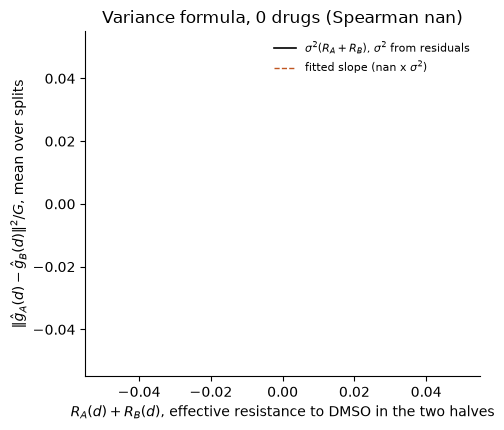

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_extend_analysis/variance_test.png
[variance test] 4.5s | total 4.1 min


In [8]:
# B23. Registered test of the variance formula (Proposition graph, part ii): Var(g_hat[d]) = sigma^2 * R_H(d)
# Run after Restore, B10c-functions and B19c (parent-compound names). Uses SIG, KEY, TAH, REF_KEYS.
# Registered rule (proposal, Aim 3b): least squares WITHOUT shrinkage (lambda = 0); spread of g_hat[d] over random
# subsets of plates compared with R_H(d) of the same subsets; sigma^2 from the residuals of the fit, not from the
# spread being tested. Success: Spearman >= 0.5 and fitted slope within a factor of two of sigma^2.
# How the spread is measured: the plates are split at random into two halves A and B with no well in common, and
# D[d] = g_hat_A[d] - g_hat_B[d]. If the formula holds, E|D[d]|^2 / G = sigma^2 * (R_A(d) + R_B(d)), because the two
# estimates are unbiased for the same g[d] and their noise is independent. Overlapping subsets would share noise and
# shrink the spread, so they are not used. Plate 13 is the only plate that links DMSO to the drugs, so a half without
# it has no drug linked to DMSO; its wells are therefore split between the two halves (one DMSO well each), and the
# other 13 plates are split at random (6 and 7). This is the one deviation from "subsets of plates", stated here.
t0 = time.time()
N_SPLITS_VAR = 50
LINK_PLATE = "plate13"


def ls_fit(wells):
    """wells: list of (plate, k). Exact least squares s = g[drug] + t[pos] (+ e), g[DMSO] = 0, nodes in the anchored
    component only. Returns g_hat {drug: [G]}, R {drug: effective resistance}, residual variance (pooled over genes)."""
    E = [(KEY[p][k], TAH[p]["well"][k]) for p, k in wells]
    drugs, pos, nid, A, anchors = graph_from_edges(E)
    R, _ = resistance_to_anchor(A, anchors)
    free = [i for i in range(len(A)) if np.isfinite(R[i]) and i not in set(anchors)]
    col = {i: j for j, i in enumerate(free)}
    rows = [r for r, (d, w) in enumerate(E) if np.isfinite(R[nid[("d", d)]])]   # wells of the anchored component
    X = np.zeros((len(rows), len(free)))
    for i, r in enumerate(rows):
        d, w = E[r]
        if nid[("d", d)] in col:
            X[i, col[nid[("d", d)]]] = 1
        X[i, col[nid[("w", w)]]] = 1
    S = np.stack([SIG[p][k] for p, k in (wells[r] for r in rows)]).astype(np.float64)
    theta, *_ = np.linalg.lstsq(X, S, rcond=None)
    resid = S - X @ theta
    dof = len(rows) - np.linalg.matrix_rank(X)
    sigma2 = float((resid ** 2).sum() / (dof * S.shape[1]))
    g = {d: theta[col[nid[("d", d)]]] for d in drugs if nid[("d", d)] in col}
    Rd = {d: R[nid[("d", d)]] for d in g}
    return g, Rd, sigma2, dof


PL = sorted(TAH, key=pnum)
others = [p for p in PL if p != LINK_PLATE]
link_wells = [k for k in range(len(KEY[LINK_PLATE])) if not np.isnan(SIG[LINK_PLATE][k, 0])]
link_ref = [k for k in link_wells if KEY[LINK_PLATE][k] in REF_KEYS]
link_trt = [k for k in link_wells if KEY[LINK_PLATE][k] not in REF_KEYS]
assert len(link_ref) >= 2, "plate13 needs two DMSO wells with a signature"
rng = np.random.default_rng(SEED)
recs, sig2s = [], []
for s in range(N_SPLITS_VAR):
    perm = rng.permutation(others)
    half = [list(perm[: len(perm) // 2]), list(perm[len(perm) // 2:])]
    rr, rt = rng.permutation(link_ref), rng.permutation(link_trt)
    lk = [list(rr[0::2]) + list(rt[0::2]), list(rr[1::2]) + list(rt[1::2])]
    fits = []
    for h in range(2):
        wells = [(p, k) for p in half[h] for k in range(len(KEY[p])) if not np.isnan(SIG[p][k, 0])]
        wells += [(LINK_PLATE, k) for k in lk[h]]
        fits.append(ls_fit(wells))
    (gA, RA, s2A, dA), (gB, RB, s2B, dB) = fits
    sig2s.append((s2A * dA + s2B * dB) / (dA + dB))
    for d in set(gA) & set(gB):
        recs.append(dict(split=s, drug=d, R_sum=RA[d] + RB[d], D2=float(np.mean((gA[d] - gB[d]) ** 2))))
VT = pd.DataFrame(recs)
SIGMA2 = float(np.mean(sig2s))
per_drug = VT.groupby("drug").agg(R_sum=("R_sum", "mean"), D2=("D2", "mean"), n_splits=("split", "size"))
per_drug = per_drug[per_drug.n_splits >= 10]          # drugs estimable in both halves in at least 10 splits
rho = spearmanr(per_drug.R_sum, per_drug.D2)[0]
slope = float((per_drug.R_sum * per_drug.D2).sum() / (per_drug.R_sum ** 2).sum())   # through the origin
ratio = slope / SIGMA2
ok = (rho >= 0.5) and (0.5 <= ratio <= 2)
VT.to_csv(os.path.join(OUT_DIR, "variance_test_splits.csv"), index=False)
per_drug.to_csv(os.path.join(OUT_DIR, "variance_test_drugs.csv"))
print(f"Splits: {N_SPLITS_VAR} | drugs tested (in both halves in >= 10 splits): {len(per_drug)} "
      f"| median R_A + R_B {per_drug.R_sum.median():.2f} (range {per_drug.R_sum.min():.2f} to {per_drug.R_sum.max():.2f})")
print(f"sigma^2 from residuals (pooled over genes and splits): {SIGMA2:.4f}")
print(f"Spearman(R_A + R_B, spread) = {rho:.2f} | slope = {slope:.4f} = {ratio:.2f} x sigma^2")
print(f"REGISTERED TEST (Spearman >= 0.5 and slope within 2x of sigma^2): {'PASS' if ok else 'FAIL'}")

# descriptive: spread by bins of resistance (one row per bin)
per_drug["R_bin"] = pd.qcut(per_drug.R_sum, 4, duplicates="drop")
print(per_drug.groupby("R_bin", observed=True).agg(drugs=("D2", "size"), R_sum=("R_sum", "median"),
                                                   spread=("D2", "median"))
      .assign(spread_over_sigma2=lambda x: x.spread / SIGMA2).round(3).to_string())

fig, ax = plt.subplots(figsize=(5, 4.4))
ax.scatter(per_drug.R_sum, per_drug.D2, s=12, alpha=0.6, color="#2b6cb0")
xx = np.linspace(0, per_drug.R_sum.max() * 1.05, 50)
ax.plot(xx, SIGMA2 * xx, color="k", lw=1.2, label=r"$\sigma^2 (R_A + R_B)$, $\sigma^2$ from residuals")
ax.plot(xx, slope * xx, color="#c05621", lw=1, ls="--", label=f"fitted slope ({ratio:.2f} x $\\sigma^2$)")
ax.set_xlabel(r"$R_A(d) + R_B(d)$, effective resistance to DMSO in the two halves")
ax.set_ylabel(r"$\|\hat g_A(d) - \hat g_B(d)\|^2 / G$, mean over splits")
ax.set_title(f"Variance formula, {len(per_drug)} drugs (Spearman {rho:.2f})")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "variance_test.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf")); plt.show()
print("Saved:", png)
stamp(t0, "variance test")

Plates per drug (drugs with a signature): {0: 5, 1: 17, 2: 20, 3: 217, 4: 83, 5: 4, 6: 7, 7: 5, 8: 2, 13: 1}
plate split, half 0: plates [np.str_('plate3'), np.str_('plate5'), np.str_('plate6'), np.str_('plate8'), np.str_('plate11'), np.str_('plate14')] + half of plate13 | drugs 345, linked to DMSO 57
plate split, half 1: plates [np.str_('plate1'), np.str_('plate2'), np.str_('plate4'), np.str_('plate7'), np.str_('plate9'), np.str_('plate10'), np.str_('plate12')] + half of plate13 | drugs 353, linked to DMSO 13

Well split, 50 splits | drugs tested: 0 | median R_A + R_B nan (range nan to nan)
sigma^2 from residuals: 0.0108 | Spearman = nan | slope = nan = nan x sigma^2
REGISTERED CRITERION on the well split (Spearman >= 0.5, slope within 2x): FAIL
Empty DataFrame
Columns: [drugs, R_sum, spread, spread_over_sigma2]
Index: []


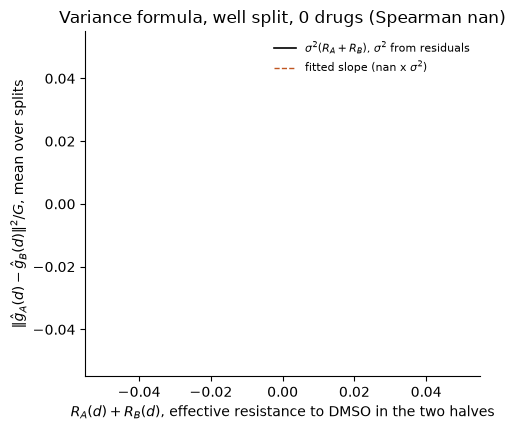

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_extend_analysis/variance_test.png
[variance test, well split] 3.7s | total 9.4 min


In [9]:
# B23b. Why did B23 find no drug in both halves? Diagnostic, then the same test with the wells (not plates) split.
# Run right after B23 (uses ls_fit, PL, LINK_PLATE, SIG, KEY, TAH, REF_KEYS).
t0 = time.time()

# ---- 1) diagnostic: on how many plates does each drug sit, and what does one plate split leave connected?
n_plates = pd.Series({d: len({p for p in PL for k in range(len(KEY[p])) if KEY[p][k] == d and not np.isnan(SIG[p][k, 0])})
                      for d in {KEY[p][k] for p in PL for k in range(len(KEY[p]))} if d not in REF_KEYS})
print("Plates per drug (drugs with a signature):", n_plates.value_counts().sort_index().to_dict())
rng = np.random.default_rng(SEED)
perm = rng.permutation([p for p in PL if p != LINK_PLATE])
half = [list(perm[:6]), list(perm[6:])]
lw = [k for k in range(len(KEY[LINK_PLATE])) if not np.isnan(SIG[LINK_PLATE][k, 0])]
lr = rng.permutation([k for k in lw if KEY[LINK_PLATE][k] in REF_KEYS]); lt = rng.permutation([k for k in lw if KEY[LINK_PLATE][k] not in REF_KEYS])
for h, lk in enumerate([list(lr[0::2]) + list(lt[0::2]), list(lr[1::2]) + list(lt[1::2])]):
    wells = [(p, k) for p in half[h] for k in range(len(KEY[p])) if not np.isnan(SIG[p][k, 0])] + [(LINK_PLATE, k) for k in lk]
    g_, R_, _, _ = ls_fit(wells)
    n_all = len({KEY[p][k] for p, k in wells} - REF_KEYS)
    print(f"plate split, half {h}: plates {sorted(half[h], key=pnum)} + half of {LINK_PLATE} | drugs {n_all}, linked to DMSO {len(g_)}")

# ---- 2) the test with the wells split: for every (plate, drug), its wells alternate between the halves at random,
# so a drug with two or more wells is in both halves; DMSO wells are split the same way (one of each pair per half).
# Deviation from the registration (subsets of plates): wells of one plate fall in both halves, so a plate-level term
# shared by them would make the two estimates covary and the spread smaller than sigma^2 * (R_A + R_B).
recs, sig2s = [], []
for s in range(N_SPLITS_VAR):
    hw = [[], []]
    for p in PL:
        groups = {}
        for k in range(len(KEY[p])):
            if not np.isnan(SIG[p][k, 0]):
                groups.setdefault(KEY[p][k], []).append(k)
        for d, ks in groups.items():
            ks = list(rng.permutation(ks)); start = int(rng.integers(2))
            for i, k in enumerate(ks):
                hw[(start + i) % 2].append((p, k))
    (gA, RA, s2A, dA), (gB, RB, s2B, dB) = ls_fit(hw[0]), ls_fit(hw[1])
    sig2s.append((s2A * dA + s2B * dB) / (dA + dB))
    for d in set(gA) & set(gB):
        recs.append(dict(split=s, drug=d, R_sum=RA[d] + RB[d], D2=float(np.mean((gA[d] - gB[d]) ** 2))))
VTW = pd.DataFrame(recs)
SIGMA2W = float(np.mean(sig2s))
pdw = VTW.groupby("drug").agg(R_sum=("R_sum", "mean"), D2=("D2", "mean"), n_splits=("split", "size"))
pdw = pdw[pdw.n_splits >= 10]
rho_w = spearmanr(pdw.R_sum, pdw.D2)[0]
slope_w = float((pdw.R_sum * pdw.D2).sum() / (pdw.R_sum ** 2).sum())
ratio_w = slope_w / SIGMA2W
ok_w = (rho_w >= 0.5) and (0.5 <= ratio_w <= 2)
VTW.to_csv(os.path.join(OUT_DIR, "variance_test_wellsplit_splits.csv"), index=False)
pdw.to_csv(os.path.join(OUT_DIR, "variance_test_wellsplit_drugs.csv"))
print(f"\nWell split, {N_SPLITS_VAR} splits | drugs tested: {len(pdw)} | median R_A + R_B {pdw.R_sum.median():.2f} "
      f"(range {pdw.R_sum.min():.2f} to {pdw.R_sum.max():.2f})")
print(f"sigma^2 from residuals: {SIGMA2W:.4f} | Spearman = {rho_w:.2f} | slope = {slope_w:.4f} = {ratio_w:.2f} x sigma^2")
print(f"REGISTERED CRITERION on the well split (Spearman >= 0.5, slope within 2x): {'PASS' if ok_w else 'FAIL'}")
pdw["R_bin"] = pd.qcut(pdw.R_sum, 4, duplicates="drop")
print(pdw.groupby("R_bin", observed=True).agg(drugs=("D2", "size"), R_sum=("R_sum", "median"), spread=("D2", "median"))
      .assign(spread_over_sigma2=lambda x: x.spread / SIGMA2W).round(3).to_string())

fig, ax = plt.subplots(figsize=(5, 4.4))
ax.scatter(pdw.R_sum, pdw.D2, s=12, alpha=0.6, color="#2b6cb0")
xx = np.linspace(0, pdw.R_sum.max() * 1.05, 50)
ax.plot(xx, SIGMA2W * xx, color="k", lw=1.2, label=r"$\sigma^2 (R_A + R_B)$, $\sigma^2$ from residuals")
ax.plot(xx, slope_w * xx, color="#c05621", lw=1, ls="--", label=f"fitted slope ({ratio_w:.2f} x $\\sigma^2$)")
ax.set_xlabel(r"$R_A(d) + R_B(d)$, effective resistance to DMSO in the two halves")
ax.set_ylabel(r"$\|\hat g_A(d) - \hat g_B(d)\|^2 / G$, mean over splits")
ax.set_title(f"Variance formula, well split, {len(pdw)} drugs (Spearman {rho_w:.2f})")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "variance_test.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf")); plt.show()
print("Saved:", png)
stamp(t0, "variance test, well split")

split 0: drugs in both halves 182, pairs in one component in both halves 100
50 splits | pair records 15640 | distinct pairs 783
median R_A + R_B 3.00 (5th to 95th pct 2.50 to 8.44)
sigma^2 from residuals: 0.0098 | Spearman = 0.50 | slope = 0.0113 = 1.15 x sigma^2
REGISTERED CRITERION on drug contrasts (Spearman >= 0.5, slope within 2x): FAIL
                records  R_sum  spread  spread_over_sigma2  predicted
R_bin                                                                
(1.999, 2.804]     3128  2.500   0.024               2.463      2.500
(2.804, 2.967]     3128  2.833   0.028               2.809      2.833
(2.967, 3.0]       3141  3.000   0.039               3.986      3.000
(3.0, 5.5]         3115  4.457   0.054               5.465      4.457
(5.5, 18.543]      3128  7.051   0.085               8.612      7.051


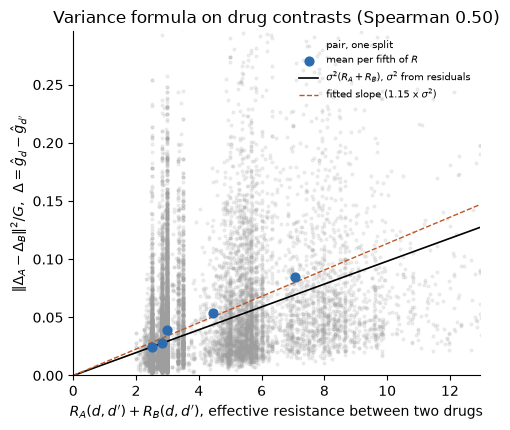

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_extend_analysis/variance_test.png
[variance test, contrasts] 29.7s | total 13.5 min


In [10]:
# B23c. Variance formula on contrasts between drugs (plates split, as registered).
# B23/B23b showed that after any split almost no drug stays linked to DMSO in both halves (57 and 13 of ~350 drugs in
# one plate split): the link runs through plate 13 only, and halving the edges breaks it. A difference between two drugs
# of the same connected component does not need DMSO: it is identified inside the component, and by the same proof
# Var(g_hat[d] - g_hat[d']) = sigma^2 * R(d, d'), the effective resistance between the two drug nodes.
# So here: plates split at random into two halves (plate 13 is now an ordinary plate), exact least squares in each half
# (lambda = 0), and for drug pairs in one component in both halves:
#   D = (g_A[d] - g_A[d']) - (g_B[d] - g_B[d']),   E |D|^2 / G = sigma^2 * (R_A(d, d') + R_B(d, d')).
# sigma^2 from the residuals of the fits. Registered criterion unchanged: Spearman >= 0.5, slope within 2x of sigma^2.
# Run after B23 (uses PL, SIG, KEY, TAH, N_SPLITS_VAR).
t0 = time.time()
N_PAIRS_VAR = 400          # random drug pairs per split


def ls_fit_free(wells):
    """Least squares s = g[drug] + t[pos] with no anchor (min-norm solution; contrasts within a component are
    unique). Returns drug index, component label and Laplacian pseudo-inverse per drug, g_hat, sigma^2, dof."""
    E = [(KEY[p][k], TAH[p]["well"][k]) for p, k in wells]
    drugs = sorted({d for d, _ in E}); pos = sorted({w for _, w in E})
    di = {d: i for i, d in enumerate(drugs)}; wi = {w: len(drugs) + i for i, w in enumerate(pos)}
    X = np.zeros((len(E), len(drugs) + len(pos)))
    A = np.zeros((X.shape[1], X.shape[1]))
    for r, (d, w) in enumerate(E):
        X[r, di[d]] = 1; X[r, wi[w]] = 1
        A[di[d], wi[w]] += 1; A[wi[w], di[d]] += 1
    S = np.stack([SIG[p][k] for p, k in wells]).astype(np.float64)
    theta, *_ = np.linalg.lstsq(X, S, rcond=None)
    rank = np.linalg.matrix_rank(X)
    resid = S - X @ theta
    dof = len(E) - rank
    sigma2 = float((resid ** 2).sum() / (dof * S.shape[1]))
    ncomp, lab = connected_components(A > 0, directed=False)
    Lp = np.linalg.pinv(np.diag(A.sum(1)) - A)     # within a component, R(u,v) = Lp[u,u] + Lp[v,v] - 2 Lp[u,v]
    return dict(di=di, lab=lab, Lp=Lp, g=theta, sigma2=sigma2, dof=dof)


def res(f, i, j):
    return f["Lp"][i, i] + f["Lp"][j, j] - 2 * f["Lp"][i, j]


rng = np.random.default_rng(SEED + 7)
recs, sig2s = [], []
for s in range(N_SPLITS_VAR):
    perm = rng.permutation(PL)
    halves = [list(perm[: len(PL) // 2]), list(perm[len(PL) // 2:])]
    F = [ls_fit_free([(p, k) for p in h for k in range(len(KEY[p])) if not np.isnan(SIG[p][k, 0])]) for h in halves]
    sig2s.append((F[0]["sigma2"] * F[0]["dof"] + F[1]["sigma2"] * F[1]["dof"]) / (F[0]["dof"] + F[1]["dof"]))
    common = sorted((set(F[0]["di"]) & set(F[1]["di"])) - REF_KEYS)
    # candidate pairs: same component in both halves
    cand = [(a, b) for i, a in enumerate(common) for b in common[i + 1:]
            if F[0]["lab"][F[0]["di"][a]] == F[0]["lab"][F[0]["di"][b]] and F[1]["lab"][F[1]["di"][a]] == F[1]["lab"][F[1]["di"][b]]]
    if not cand:
        continue
    for idx in rng.choice(len(cand), min(N_PAIRS_VAR, len(cand)), replace=False):
        a, b = cand[idx]
        RA = res(F[0], F[0]["di"][a], F[0]["di"][b]); RB = res(F[1], F[1]["di"][a], F[1]["di"][b])
        cA = F[0]["g"][F[0]["di"][a]] - F[0]["g"][F[0]["di"][b]]
        cB = F[1]["g"][F[1]["di"][a]] - F[1]["g"][F[1]["di"][b]]
        recs.append(dict(split=s, pair=f"{a} | {b}", R_sum=RA + RB, D2=float(np.mean((cA - cB) ** 2))))
    if s == 0:
        print(f"split 0: drugs in both halves {len(common)}, pairs in one component in both halves {len(cand)}")
VC = pd.DataFrame(recs)
SIGMA2C = float(np.mean(sig2s))
print(f"{N_SPLITS_VAR} splits | pair records {len(VC)} | distinct pairs {VC.pair.nunique() if len(VC) else 0}")
if len(VC) >= 20:
    rho_c = spearmanr(VC.R_sum, VC.D2)[0]
    slope_c = float((VC.R_sum * VC.D2).sum() / (VC.R_sum ** 2).sum())
    ratio_c = slope_c / SIGMA2C
    ok_c = (rho_c >= 0.5) and (0.5 <= ratio_c <= 2)
    print(f"median R_A + R_B {VC.R_sum.median():.2f} (5th to 95th pct {VC.R_sum.quantile(.05):.2f} to {VC.R_sum.quantile(.95):.2f})")
    print(f"sigma^2 from residuals: {SIGMA2C:.4f} | Spearman = {rho_c:.2f} | slope = {slope_c:.4f} = {ratio_c:.2f} x sigma^2")
    print(f"REGISTERED CRITERION on drug contrasts (Spearman >= 0.5, slope within 2x): {'PASS' if ok_c else 'FAIL'}")
    VC["R_bin"] = pd.qcut(VC.R_sum, 5, duplicates="drop")
    BINS_VC = (VC.groupby("R_bin", observed=True)
                 .agg(records=("D2", "size"), R_sum=("R_sum", "median"), spread=("D2", "mean"))
                 .assign(spread_over_sigma2=lambda x: x.spread / SIGMA2C, predicted=lambda x: x.R_sum))
    print(BINS_VC.round(3).to_string())
    VC.to_csv(os.path.join(OUT_DIR, "variance_test_contrasts.csv"), index=False)
    BINS_VC.to_csv(os.path.join(OUT_DIR, "variance_test_contrasts_bins.csv"))

    fig, ax = plt.subplots(figsize=(5, 4.4))
    ax.scatter(VC.R_sum, VC.D2, s=4, alpha=0.15, color="#9e9e9e", label="pair, one split")
    ax.scatter(BINS_VC.R_sum, BINS_VC.spread, s=40, color="#2b6cb0", zorder=3, label="mean per fifth of $R$")
    xx = np.linspace(0, VC.R_sum.quantile(.99) * 1.05, 50)
    ax.plot(xx, SIGMA2C * xx, color="k", lw=1.2, label=r"$\sigma^2 (R_A + R_B)$, $\sigma^2$ from residuals")
    ax.plot(xx, slope_c * xx, color="#c05621", lw=1, ls="--", label=f"fitted slope ({ratio_c:.2f} x $\\sigma^2$)")
    ax.set_xlim(0, xx[-1]); ax.set_ylim(0, np.quantile(VC.D2, .99) * 1.1)
    ax.set_xlabel(r"$R_A(d,d') + R_B(d,d')$, effective resistance between two drugs")
    ax.set_ylabel(r"$\|\Delta_A - \Delta_B\|^2 / G$,  $\Delta = \hat g_d - \hat g_{d'}$")
    ax.set_title(f"Variance formula on drug contrasts (Spearman {rho_c:.2f})")
    ax.legend(frameon=False, fontsize=7); ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    png = os.path.abspath(os.path.join(OUT_DIR, "variance_test.png"))
    fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf")); plt.show()
    print("Saved:", png)
stamp(t0, "variance test, contrasts")

uncorrected 14s | well mean 28s | internal controls 42s | 

Median Pearson across genes, all entries:
predictor                          global mean  line mean  position only  same drug, other position  same drug, same position
target                                                                                                                       
uncorrected, DMSO ref                    0.420      0.445          0.562                      0.092                     0.624
uncorrected, treated median              0.035      0.034          0.535                      0.008                     0.547
well mean, DMSO ref                     -0.000      0.252          0.174                      0.038                     0.275
well mean, treated median                0.007     -0.002          0.077                      0.029                     0.118
internal controls, DMSO ref              0.019      0.242          0.176                      0.038                     0.253
internal control

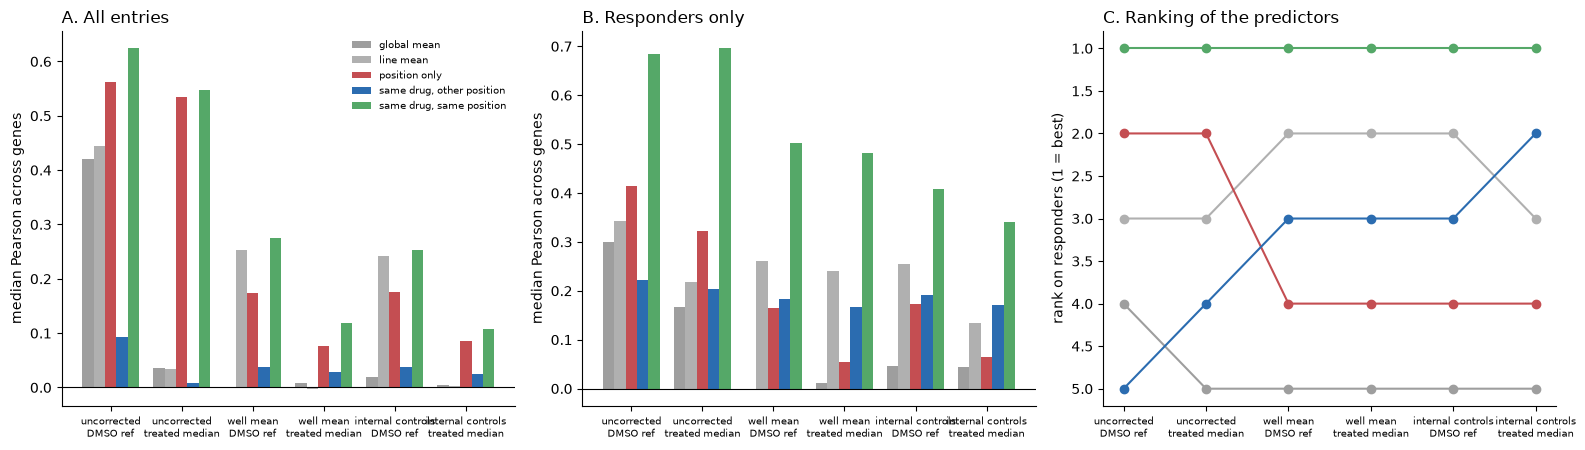

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_extend_analysis/benchmark_wellmean.png
[benchmark, well mean] 60.4s | total 18.6 min


In [13]:
# B24. Benchmark impact: does the well signature raise prediction scores, and does removing it change the ranking?
# Leave one plate out: the predictors are built from the other 13 plates and scored on the held-out plate.
# Targets: uncorrected, well mean (the leave-one-out mean of the other lines of the well removed, slope one, no masks)
# and internal controls (signature estimator), each with the DMSO reference and the treated-well median.
# Predictors (no model fitting, so nothing can overfit): global mean, line mean, position only (same line, same
# position, other drugs), same drug at another position, same drug at the same position.
# Questions fixed before running:
#   Q1 inflation: with uncorrected targets, "position only" scores above "same drug, other position" (paired median
#      difference < 0 on all entries, DMSO reference).
#   Q2 removal: with well-mean targets, that paired difference is >= 0 on responders, and the median score of
#      "position only" on the perturbation-specific part (line mean removed) is <= 0.05.
#   Q3 ranking: the rank order of the five predictors differs between uncorrected and well-mean targets
#      (Kendall tau < 1), and "position only" drops by at least two places on responders.
# Needs: setup, cell 1 functions (contrast), Restore, B19c. ~2-4 minutes.
t0 = time.time()
from scipy.stats import kendalltau
PL = sorted(TAH, key=lambda s: int(re.sub(r"\D", "", s)))
TR = {p: np.where(~TAH[p]["ref"][0])[0] for p in TAH}
PREDS = ["global mean", "line mean", "position only", "same drug, other position", "same drug, same position"]


def med_ref(Y, T):
    return Y[0] - np.nanmedian(Y[0][~T["ref"][0]], axis=0, keepdims=True)


def rowcorr(a, b):
    a = a - a.mean(1, keepdims=True); b = b - b.mean(1, keepdims=True)
    return (a * b).sum(1) / np.sqrt((a * a).sum(1) * (b * b).sum(1))


def well_mean_corr(p):
    """Well mean on the centred data of plate p: each line minus the mean of the other observed lines of its well."""
    Y0 = RUN[p][2]["Y0"].astype(np.float64)                      # [1, K, C, G], centred, NaN set to 0
    obs = ~np.isnan(TAH[p]["Y"][..., 0])                          # [1, K, C]
    okf = obs.astype(np.float64)
    S = np.einsum("dkc,dkcg->dkg", okf, Y0)
    n_other = okf.sum(-1)[..., None] - okf
    P = (S[:, :, None, :] - okf[..., None] * Y0) / np.maximum(n_other, 1)[..., None]
    P[n_other < 1] = 0
    Y1 = (Y0 - P).astype(np.float32)
    Y1[~obs] = np.nan
    return Y1


CORR = {"uncorrected": lambda p: RUN[p][0]["naive"], "well mean": well_mean_corr,
        "internal controls": lambda p: RUN[p][0]["signature"]}
REFS = {"DMSO ref": lambda Y, q: contrast(Y, TAH[q]["ref"])[0], "treated median": lambda Y, q: med_ref(Y, TAH[q])}
TARGETS = [f"{c}, {r}" for c in CORR for r in REFS]
out = []
for cname, fc in CORR.items():
    Yc = {q: fc(q) for q in PL}
    for rname, fr in REFS.items():
        Rt = {q: fr(Yc[q], q).astype(np.float32) for q in PL}
        tname = f"{cname}, {rname}"
        for p in PL:
            Tr = [q for q in PL if q != p]
            line_mean = np.nanmean(np.concatenate([Rt[q][TR[q]] for q in Tr]), 0)
            glob = np.broadcast_to(np.nanmean(line_mean, 0), line_mean.shape)
            for k in TR[p]:
                w, key = TAH[p]["well"][k], KEY[p][k]
                pos_o = [Rt[q][j] for q in Tr for j in np.where(TAH[q]["well"] == w)[0]
                         if KEY[q][j] != key and not TAH[q]["ref"][0, j]]
                same = [Rt[q][j] for q in Tr for j in np.where(KEY[q] == key)[0] if TAH[q]["well"][j] == w]
                diff = [Rt[q][j] for q in Tr for j in np.where(KEY[q] == key)[0] if TAH[q]["well"][j] != w]
                P_ = {"global mean": glob, "line mean": line_mean,
                      "position only": np.nanmean(pos_o, 0) if pos_o else None,
                      "same drug, other position": np.nanmean(diff, 0) if diff else None,
                      "same drug, same position": np.nanmean(same, 0) if same else None}
                y = Rt[p][k]
                okc = ~np.isnan(y[:, 0])
                nr = RUN[p][1][0][k]
                for name, pr in P_.items():
                    if pr is None:
                        continue
                    okp = okc & ~np.isnan(pr[:, 0])
                    if not okp.any():
                        continue
                    r = rowcorr(y[okp], pr[okp])
                    rd = (rowcorr(y[okp] - line_mean[okp], pr[okp] - line_mean[okp]) if name != "line mean"
                          else np.full(okp.sum(), np.nan))
                    for c, a, b in zip(np.where(okp)[0], r, rd):
                        out.append((tname, p, w, key, c, bool(nr[c]), name, a, b))
        del Rt
    del Yc
    print(cname, f"{time.time() - t0:.0f}s", end=" | ", flush=True)
print()
EV4 = pd.DataFrame(out, columns=["target", "plate", "well", "drug", "line", "nonresponder", "predictor", "pearson", "pearson_delta"])
del out
EV4.to_csv(os.path.join(OUT_DIR, "benchmark_wellmean_scores.csv.gz"), index=False)

tab = EV4.groupby(["target", "predictor"]).pearson.median().unstack().reindex(TARGETS)[PREDS]
tabd = EV4.groupby(["target", "predictor"]).pearson_delta.median().unstack().reindex(TARGETS)[PREDS]
tabr = EV4[~EV4.nonresponder].groupby(["target", "predictor"]).pearson.median().unstack().reindex(TARGETS)[PREDS]
rk, rkr = tab.rank(axis=1, ascending=False), tabr.rank(axis=1, ascending=False)
for T_, ttl in [(tab, "Median Pearson across genes, all entries"), (tabd, "Perturbation-specific part (line mean removed)"),
                (tabr, "Responders only"), (rk.astype(int), "Rank, all entries (1 = best)"), (rkr.astype(int), "Rank, responders")]:
    print(f"\n{ttl}:"); print(T_.round(3).to_string())
for name, T_ in [("all", tab), ("delta", tabd), ("responders", tabr)]:
    T_.to_csv(os.path.join(OUT_DIR, f"benchmark_wellmean_{name}.csv"))

pv = EV4.pivot_table(index=["target", "plate", "well", "drug", "line", "nonresponder"], columns="predictor",
                     values="pearson", aggfunc="first").dropna(subset=["position only", "same drug, other position"]).reset_index()
pv["d"] = pv["same drug, other position"] - pv["position only"]
rows = []
for t in TARGETS:
    for grp, sub in [("all", pv[pv.target == t]), ("responders", pv[(pv.target == t) & ~pv.nonresponder])]:
        rows.append(dict(target=t, entries=grp, n=len(sub), median_diff=sub.d.median(), drug_wins=(sub.d > 0).mean(),
                         wilcoxon_p=wilcoxon(sub.d).pvalue if len(sub) > 10 else np.nan))
PAIR4 = pd.DataFrame(rows)
PAIR4.to_csv(os.path.join(OUT_DIR, "benchmark_wellmean_paired.csv"), index=False)
print("\nSame entries, (same drug at another position) minus (position only):")
print(PAIR4.round(3).to_string(index=False))

# ---- the three questions
g = lambda t, e: PAIR4[(PAIR4.target == t) & (PAIR4.entries == e)].median_diff.iat[0]
q1 = g("uncorrected, DMSO ref", "all") < 0
q2 = (g("well mean, DMSO ref", "responders") >= 0) and (tabd.loc["well mean, DMSO ref", "position only"] <= 0.05)
tau = kendalltau(rk.loc["uncorrected, DMSO ref"], rk.loc["well mean, DMSO ref"])[0]
drop = rkr.loc["well mean, DMSO ref", "position only"] - rkr.loc["uncorrected, DMSO ref", "position only"]
q3 = (tau < 1) and (drop >= 2)
print(f"\nQ1 position-only beats same drug elsewhere on uncorrected targets: {q1}")
print(f"Q2 well mean removes the advantage (responders diff >= 0; position-only delta score <= 0.05): {q2}")
print(f"Q3 ranking changes (Kendall tau {tau:.2f} < 1) and position-only drops >= 2 places on responders ({drop:+.0f}): {q3}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
colors = ["#9e9e9e", "#b0b0b0", "#c44e52", "#2b6cb0", "#55a868"]
lab = [t.replace(", ", "\n") for t in TARGETS]; x = np.arange(len(TARGETS)); wdt = 0.16
for a, (T_, ttl) in zip(ax[:2], [(tab, "A. All entries"), (tabr, "B. Responders only")]):
    for i, (pname, col) in enumerate(zip(PREDS, colors)):
        a.bar(x + (i - 2) * wdt, T_[pname].values, wdt, color=col, label=pname)
    a.set_xticks(x); a.set_xticklabels(lab, fontsize=7); a.axhline(0, color="k", lw=.8)
    a.set_ylabel("median Pearson across genes"); a.set_title(ttl, loc="left")
ax[0].legend(frameon=False, fontsize=7)
for i, (pname, col) in enumerate(zip(PREDS, colors)):
    ax[2].plot(x, rkr[pname].values, "o-", color=col, label=pname)
ax[2].invert_yaxis(); ax[2].set_xticks(x); ax[2].set_xticklabels(lab, fontsize=7)
ax[2].set_ylabel("rank on responders (1 = best)"); ax[2].set_title("C. Ranking of the predictors", loc="left")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "benchmark_wellmean.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf")); plt.show()
print("Saved:", png)
stamp(t0, "benchmark, well mean")

In [14]:
# B23d. Checks of the variance test before anything is written. Run after B23, B23b and B23c (same kernel).
# (1) Is the failure of the single-drug form (B23, B23b) a property of the graph or a bug? Count, for one split of each
#     kind, the drugs linked to DMSO in each half and in both.
# (2) Does the contrast procedure (B23c) pass on simulated signatures WITH THE ACTUAL TAHOE LAYOUT, where the formula is
#     true by construction? If not, the Spearman >= 0.5 threshold is not reachable with this layout, whatever the data.
#     Simulated signature of a well = g_hat[drug] + t_hat[position] (full least-squares fit) + noise with the residual sigma.
# (3) Unit of analysis: the registration names drugs, not records. Records of one pair are repeated over splits, so the
#     pair (mean over its splits) is the closer unit; both are reported.
# (4) Drug key: KEY merges the doses of a drug. If the response differs between doses, the two halves estimate
#     different things and the spread gets a term that does not shrink with R. Repeat with KEY_DOSE (drug and dose).
t0 = time.time()

# ---- (1) graph or bug?
def linked_counts(wells):
    g_, _, _, _ = ls_fit(wells)
    return len(g_)

rng = np.random.default_rng(SEED)
perm = rng.permutation([p for p in PL if p != LINK_PLATE])
lw = [k for k in range(len(KEY[LINK_PLATE])) if not np.isnan(SIG[LINK_PLATE][k, 0])]
lr = rng.permutation([k for k in lw if KEY[LINK_PLATE][k] in REF_KEYS]); lt = rng.permutation([k for k in lw if KEY[LINK_PLATE][k] not in REF_KEYS])
hp = [[(p, k) for p in list(perm[:6]) for k in range(len(KEY[p])) if not np.isnan(SIG[p][k, 0])] + [(LINK_PLATE, k) for k in list(lr[0::2]) + list(lt[0::2])],
      [(p, k) for p in list(perm[6:]) for k in range(len(KEY[p])) if not np.isnan(SIG[p][k, 0])] + [(LINK_PLATE, k) for k in list(lr[1::2]) + list(lt[1::2])]]
hw = [[], []]
for p in PL:
    groups = {}
    for k in range(len(KEY[p])):
        if not np.isnan(SIG[p][k, 0]):
            groups.setdefault(KEY[p][k], []).append(k)
    for d, ks in groups.items():
        ks = list(rng.permutation(ks)); st = int(rng.integers(2))
        for i, k in enumerate(ks):
            hw[(st + i) % 2].append((p, k))
full = [(p, k) for p in PL for k in range(len(KEY[p])) if not np.isnan(SIG[p][k, 0])]
print(f"(1) linked to DMSO: all wells {linked_counts(full)} drugs")
for name, H in [("plate split", hp), ("well split", hw)]:
    gA, _, _, _ = ls_fit(H[0]); gB, _, _, _ = ls_fit(H[1])
    print(f"    {name}: half A {len(gA)}, half B {len(gB)}, both {len(set(gA) & set(gB))} "
          f"| wells {len(H[0])} + {len(H[1])} | DMSO wells {sum(KEY[p][k] in REF_KEYS for p, k in H[0])} + {sum(KEY[p][k] in REF_KEYS for p, k in H[1])}")


# ---- contrast test as a function of the signatures and the drug key (same procedure as B23c)
def contrast_test(SIGx, KEYx, n_splits=N_SPLITS_VAR, seed=SEED + 7):
    global KEY, SIG
    KEY0, SIG0 = KEY, SIG
    KEY, SIG = KEYx, SIGx                                  # ls_fit_free reads the globals
    try:
        rng = np.random.default_rng(seed)
        recs, sig2s = [], []
        for s in range(n_splits):
            perm = rng.permutation(PL)
            halves = [list(perm[: len(PL) // 2]), list(perm[len(PL) // 2:])]
            F = [ls_fit_free([(p, k) for p in h for k in range(len(KEY[p])) if not np.isnan(SIG[p][k, 0])]) for h in halves]
            sig2s.append((F[0]["sigma2"] * F[0]["dof"] + F[1]["sigma2"] * F[1]["dof"]) / (F[0]["dof"] + F[1]["dof"]))
            common = sorted((set(F[0]["di"]) & set(F[1]["di"])) - REF_KEYS)
            cand = [(a, b) for i, a in enumerate(common) for b in common[i + 1:]
                    if F[0]["lab"][F[0]["di"][a]] == F[0]["lab"][F[0]["di"][b]] and F[1]["lab"][F[1]["di"][a]] == F[1]["lab"][F[1]["di"][b]]]
            for idx in (rng.choice(len(cand), min(N_PAIRS_VAR, len(cand)), replace=False) if cand else []):
                a, b = cand[idx]
                cA = F[0]["g"][F[0]["di"][a]] - F[0]["g"][F[0]["di"][b]]
                cB = F[1]["g"][F[1]["di"][a]] - F[1]["g"][F[1]["di"][b]]
                recs.append(dict(split=s, pair=f"{a} | {b}",
                                 R_sum=res(F[0], F[0]["di"][a], F[0]["di"][b]) + res(F[1], F[1]["di"][a], F[1]["di"][b]),
                                 D2=float(np.mean((cA - cB) ** 2))))
    finally:
        KEY, SIG = KEY0, SIG0
    V = pd.DataFrame(recs); s2 = float(np.mean(sig2s))
    out = dict(sigma2=s2, records=len(V), pairs=V.pair.nunique() if len(V) else 0)
    if len(V) >= 20:
        out.update(rho_records=spearmanr(V.R_sum, V.D2)[0],
                   ratio_records=float((V.R_sum * V.D2).sum() / (V.R_sum ** 2).sum()) / s2)
        P = V.groupby("pair").agg(R_sum=("R_sum", "mean"), D2=("D2", "mean"), n=("D2", "size"))
        P = P[P.n >= 5]
        out.update(pairs_5plus=len(P), rho_pairs=spearmanr(P.R_sum, P.D2)[0] if len(P) > 5 else np.nan,
                   ratio_pairs=float((P.R_sum * P.D2).sum() / (P.R_sum ** 2).sum()) / s2 if len(P) else np.nan,
                   R_iqr=f"{V.R_sum.quantile(.25):.2f}-{V.R_sum.quantile(.75):.2f}")
        V["R_bin"] = pd.qcut(V.R_sum, 5, duplicates="drop")
        out["bins"] = V.groupby("R_bin", observed=True).agg(R=("R_sum", "median"), spread_over_sigma2=("D2", "mean")) \
                       .assign(spread_over_sigma2=lambda x: x.spread_over_sigma2 / s2)
    return out


def simulate(KEYx, seed):
    """Signatures from the full least-squares fit on the actual layout plus Gaussian noise with the residual sigma."""
    global KEY
    KEY0 = KEY; KEY = KEYx
    try:
        F = ls_fit_free(full)
    finally:
        KEY = KEY0
    rng = np.random.default_rng(seed)
    nd = len(F["di"])
    pos_names = sorted({TAH[p]["well"][k] for p, k in full})
    wi = {w: nd + i for i, w in enumerate(pos_names)}
    sd = np.sqrt(F["sigma2"])
    SIM = {}
    for p in PL:
        S = np.full_like(SIG[p], np.nan, dtype=np.float64)
        for k in range(len(KEYx[p])):
            if not np.isnan(SIG[p][k, 0]):
                S[k] = F["g"][F["di"][KEYx[p][k]]] + F["g"][wi[TAH[p]["well"][k]]] + rng.normal(0, sd, S.shape[1])
        SIM[p] = S
    return SIM


rows, BINS = [], {}
for keyname, KX in [("drug", KEY), ("drug and dose", KEY_DOSE if "KEY_DOSE" in globals() else None)]:
    if KX is None:
        print("KEY_DOSE not in memory; skipping the dose key"); continue
    for data in ["real", "simulated, actual layout"]:
        SX = SIG if data == "real" else simulate(KX, SEED + 11)
        r = contrast_test(SX, KX)
        BINS[(keyname, data)] = r.pop("bins", None)
        rows.append(dict(key=keyname, data=data, **r))
        print(f"  {keyname:13s} | {data:24s} done {time.time() - t0:.0f}s", flush=True)
CHK = pd.DataFrame(rows)
CHK.to_csv(os.path.join(OUT_DIR, "variance_test_checks.csv"), index=False)
print("\n(2)-(4) contrast test; registered criterion: Spearman >= 0.5 and slope / sigma^2 in [0.5, 2]")
print(CHK.round(3).to_string(index=False))
for k, b in BINS.items():
    if b is not None:
        print(f"\nspread / sigma^2 by fifth of R, {k[0]}, {k[1]}:"); print(b.round(2).to_string())
stamp(t0, "variance checks")

(1) linked to DMSO: all wells 333 drugs
    plate split: half A 57, half B 13, both 0 | wells 592 + 677 | DMSO wells 13 + 15
    well split: half A 3, half B 28, both 0 | wells 613 + 656 | DMSO wells 14 + 14
  drug          | real                     done 14s
  drug          | simulated, actual layout done 29s
  drug and dose | real                     done 47s
  drug and dose | simulated, actual layout done 65s

(2)-(4) contrast test; registered criterion: Spearman >= 0.5 and slope / sigma^2 in [0.5, 2]
          key                     data  sigma2  records  pairs  rho_records  ratio_records  pairs_5plus  rho_pairs  ratio_pairs     R_iqr
         drug                     real   0.010    15640    783        0.495          1.154          783      0.638        1.201 2.83-5.09
         drug simulated, actual layout   0.010    15640    783        0.961          1.001          783      0.978        1.003 2.83-5.09
drug and dose                     real   0.010      206     24        0.212 

In [15]:
# B24b. Two checks of B24 before anything is written. Run after B24 (same kernel; uses EV4, pv, PL, TR, CORR, REFS,
# rowcorr, med_ref, KEY_DOSE).
# (a) Dose. In B24 "same drug" ignores the dose, so "same drug, same position" may win because those wells also share
#     the dose (and plate group), not the position. Here both same-drug predictors are restricted to the SAME DOSE
#     (KEY_DOSE), and scored on the same entries (paired).
# (b) Stability. Plates are resampled with replacement (cluster bootstrap, 1000 times) and the scores, ranks and the
#     paired difference of Q2 are recomputed, to see how often the conclusions of B24 hold.
# Questions fixed before running:
#   (a) if "same dose, same position" still beats "same dose, other position" on well-mean targets (paired median
#       difference > 0.05 on responders), part of the position advantage is not explained by dose.
#   (b) a conclusion of B24 is called stable if it holds in at least 95% of resamples.
t0 = time.time()
assert "KEY_DOSE" in globals(), "KEY_DOSE is needed (Restore + B19c)"

# ---------------- (a) same dose
TGT_A = {"uncorrected": CORR["uncorrected"], "well mean": CORR["well mean"]}
PRED_A = ["position only", "same dose, other position", "same dose, same position"]
out = []
for cname, fc in TGT_A.items():
    Yc = {q: fc(q) for q in PL}
    for rname, fr in REFS.items():
        Rt = {q: fr(Yc[q], q).astype(np.float32) for q in PL}
        for p in PL:
            Tr = [q for q in PL if q != p]
            line_mean = np.nanmean(np.concatenate([Rt[q][TR[q]] for q in Tr]), 0)
            for k in TR[p]:
                w, key, kd = TAH[p]["well"][k], KEY[p][k], KEY_DOSE[p][k]
                same = [Rt[q][j] for q in Tr for j in np.where(KEY_DOSE[q] == kd)[0] if TAH[q]["well"][j] == w]
                diff = [Rt[q][j] for q in Tr for j in np.where(KEY_DOSE[q] == kd)[0] if TAH[q]["well"][j] != w]
                if not same or not diff:          # keep only entries that have both, so the comparison is paired
                    continue
                pos_o = [Rt[q][j] for q in Tr for j in np.where(TAH[q]["well"] == w)[0]
                         if KEY[q][j] != key and not TAH[q]["ref"][0, j]]
                P_ = {"position only": np.nanmean(pos_o, 0) if pos_o else None,
                      "same dose, other position": np.nanmean(diff, 0), "same dose, same position": np.nanmean(same, 0)}
                y = Rt[p][k]; okc = ~np.isnan(y[:, 0]); nr = RUN[p][1][0][k]
                for name, pr in P_.items():
                    if pr is None:
                        continue
                    okp = okc & ~np.isnan(pr[:, 0])
                    if okp.any():
                        for c, a in zip(np.where(okp)[0], rowcorr(y[okp], pr[okp])):
                            out.append((f"{cname}, {rname}", p, w, kd, c, bool(nr[c]), name, a))
        del Rt
    del Yc
EVA = pd.DataFrame(out, columns=["target", "plate", "well", "drug_dose", "line", "nonresponder", "predictor", "pearson"])
EVA.to_csv(os.path.join(OUT_DIR, "benchmark_dose_scores.csv.gz"), index=False)
print(f"(a) drug-dose wells with the same dose both at the same and at another position on other plates: "
      f"{EVA[['plate', 'well']].drop_duplicates().shape[0]} wells, {EVA.drug_dose.nunique()} drug-dose keys")
TA = [f"{c}, {r}" for c in TGT_A for r in REFS]
for grp, sub in [("all entries", EVA), ("responders", EVA[~EVA.nonresponder])]:
    print(f"\nMedian Pearson, {grp}:")
    print(sub.groupby(["target", "predictor"]).pearson.median().unstack().reindex(TA)[PRED_A].round(3).to_string())
pva = EVA.pivot_table(index=["target", "plate", "well", "drug_dose", "line", "nonresponder"], columns="predictor",
                      values="pearson", aggfunc="first").dropna(subset=["same dose, other position", "same dose, same position"]).reset_index()
pva["d"] = pva["same dose, same position"] - pva["same dose, other position"]
rows = []
for t in TA:
    for grp, sub in [("all", pva[pva.target == t]), ("responders", pva[(pva.target == t) & ~pva.nonresponder])]:
        rows.append(dict(target=t, entries=grp, n=len(sub), median_diff=sub.d.median(), same_pos_wins=(sub.d > 0).mean(),
                         wilcoxon_p=wilcoxon(sub.d).pvalue if len(sub) > 10 else np.nan))
PAIRA = pd.DataFrame(rows)
PAIRA.to_csv(os.path.join(OUT_DIR, "benchmark_dose_paired.csv"), index=False)
print("\nSame entries, (same dose, same position) minus (same dose, other position):")
print(PAIRA.round(3).to_string(index=False))
da = PAIRA[(PAIRA.target == "well mean, DMSO ref") & (PAIRA.entries == "responders")].median_diff.iat[0]
print(f"(a) on well-mean targets (DMSO ref, responders) the same position still wins by more than 0.05: {da > 0.05} ({da:+.3f})")
stamp(t0, "dose check")

# ---------------- (b) cluster bootstrap over plates
t1 = time.time()
N_BOOT = 1000
rngb = np.random.default_rng(SEED + 21)
TB = ["uncorrected, DMSO ref", "uncorrected, treated median", "well mean, DMSO ref", "well mean, treated median"]
arr = {}                                    # (target, subset, predictor) -> {plate: values}
for (t, pr), sub in EV4[EV4.target.isin(TB)].groupby(["target", "predictor"]):
    for subset, s2 in [("all", sub), ("responders", sub[~sub.nonresponder])]:
        arr[(t, subset, pr)] = {p: g.pearson.values for p, g in s2.groupby("plate")}
darr = {}
for t in TB:
    for subset, s2 in [("all", pv[pv.target == t]), ("responders", pv[(pv.target == t) & ~pv.nonresponder])]:
        darr[(t, subset)] = {p: g.d.values for p, g in s2.groupby("plate")}


def boot_median(dct, plates):
    v = [dct[p] for p in plates if p in dct]
    return np.median(np.concatenate(v)) if v else np.nan

res_b = []
for b in range(N_BOOT):
    pls = list(rngb.choice(PL, len(PL), replace=True))
    r = {}
    for t in TB:
        for subset in ["all", "responders"]:
            sc = pd.Series({pr: boot_median(arr[(t, subset, pr)], pls) for pr in PREDS if (t, subset, pr) in arr})
            rk = sc.rank(ascending=False)
            r[(t, subset, "rank position only")] = rk.get("position only", np.nan)
            r[(t, subset, "rank same drug, other position")] = rk.get("same drug, other position", np.nan)
            r[(t, subset, "paired diff")] = boot_median(darr[(t, subset)], pls)
    res_b.append(r)
RB = pd.DataFrame(res_b)
RB.to_csv(os.path.join(OUT_DIR, "benchmark_bootstrap.csv"), index=False)

summ = []
for t in TB:
    for subset in ["all", "responders"]:
        d = RB[(t, subset, "paired diff")]
        rp = RB[(t, subset, "rank position only")]
        summ.append(dict(target=t, entries=subset, paired_diff_median=d.median(),
                         ci_low=d.quantile(.025), ci_high=d.quantile(.975), share_diff_positive=(d > 0).mean(),
                         rank_position_only_median=rp.median(), share_rank_position_only_le2=(rp <= 2).mean(),
                         share_rank_position_only_ge4=(rp >= 4).mean()))
SUMB = pd.DataFrame(summ)
SUMB.to_csv(os.path.join(OUT_DIR, "benchmark_bootstrap_summary.csv"), index=False)
print("\n(b) cluster bootstrap over plates, 1000 resamples. paired diff = (same drug, other position) - (position only)")
print(SUMB.round(3).to_string(index=False))
g = lambda t, e, c: SUMB[(SUMB.target == t) & (SUMB.entries == e)][c].iat[0]
print(f"\nStable (>= 95% of resamples):")
print(f"  Q1 uncorrected, DMSO ref, all: position only wins (diff < 0): {1 - g('uncorrected, DMSO ref', 'all', 'share_diff_positive'):.1%}")
print(f"  Q2 well mean, DMSO ref, responders: same drug elsewhere wins (diff > 0): {g('well mean, DMSO ref', 'responders', 'share_diff_positive'):.1%}")
print(f"  Q3 responders: position only in top 2 uncorrected {g('uncorrected, DMSO ref', 'responders', 'share_rank_position_only_le2'):.1%}, "
      f"rank 4 or worse with well mean {g('well mean, DMSO ref', 'responders', 'share_rank_position_only_ge4'):.1%}")
stamp(t1, "bootstrap")

(a) drug-dose wells with the same dose both at the same and at another position on other plates: 13 wells, 1 drug-dose keys

Median Pearson, all entries:
predictor                    position only  same dose, other position  same dose, same position
target                                                                                         
uncorrected, DMSO ref                0.011                     -0.008                     0.701
uncorrected, treated median          0.347                      0.021                     0.570
well mean, DMSO ref                 -0.033                     -0.017                     0.194
well mean, treated median            0.019                      0.093                     0.249

Median Pearson, responders:
predictor                    position only  same dose, other position  same dose, same position
target                                                                                         
uncorrected, DMSO ref                0.007       

## B13. Replicate plates and control positions
**After a kernel restart** there is no need to re-run everything: run the setup cell, the function cell of section 1, the `B10c-functions` cell, then the restore cell below (it loads the state saved after B10d only if it is missing).

In [34]:
# B13a. Where are the DMSO wells on each Tahoe plate?
for p in sorted(TAH, key=lambda s: int(re.sub(r"\D", "", s))):
    print(p, sorted(set(TAH[p]["well"][TAH[p]["ref"][0]])))


plate1 [np.str_('H11'), np.str_('H12')]
plate2 [np.str_('H11'), np.str_('H12')]
plate3 [np.str_('H11'), np.str_('H12')]
plate4 [np.str_('H11'), np.str_('H12')]
plate5 [np.str_('H11'), np.str_('H12')]
plate6 [np.str_('H11'), np.str_('H12')]
plate7 [np.str_('H11'), np.str_('H12')]
plate8 [np.str_('H11'), np.str_('H12')]
plate9 [np.str_('H11'), np.str_('H12')]
plate10 [np.str_('H11'), np.str_('H12')]
plate11 [np.str_('H11'), np.str_('H12')]
plate12 [np.str_('H11'), np.str_('H12')]
plate13 [np.str_('B11'), np.str_('B12')]
plate14 [np.str_('H11'), np.str_('H12')]


In [35]:
# B13b. Plate 6 vs plate 14 (biological replicates): agreement on the same well, split by responder status
t0 = time.time()
PA, PB = "plate6", "plate14"
g_a, n_a = make_g_cf({q: SIG[q] for q in SIG if q != PB}, DEC)   # g for plate 6 never sees plate 14
g_b, n_b = make_g_cf({q: SIG[q] for q in SIG if q != PA}, DEC)
REP = {PA: correct_cf(PA, g_a, n_a, DEC), PB: correct_cf(PB, g_b, n_b, DEC)}
TA, TB = TAH[PA], TAH[PB]
pos_b = {(w, k): j for j, (w, k) in enumerate(zip(TB["well"], KEY[PB]))}
match = [(k, pos_b[(w, key)]) for k, (w, key) in enumerate(zip(TA["well"], KEY[PA]))
         if (w, key) in pos_b and not TA["ref"][0, k]]
key_b = set(KEY[PB])
print(f"Treated wells on plate {PA}: {int((~TA['ref'][0]).sum())} | same key at same well on {PB}: {len(match)} | "
      f"same key anywhere on {PB}: {sum(KEY[PA][k] in key_b for k in range(len(KEY[PA])) if not TA['ref'][0, k])}")

R = {"naive": (contrast(RUN[PA][0]["naive"], TA["ref"])[0], contrast(RUN[PB][0]["naive"], TB["ref"])[0]),
     "signature": (contrast(RUN[PA][0]["signature"], TA["ref"])[0], contrast(RUN[PB][0]["signature"], TB["ref"])[0]),
     "g+t cf": (contrast(REP[PA], TA["ref"])[0], contrast(REP[PB], TB["ref"])[0])}
nrA, nrB = RUN[PA][1][0], RUN[PB][1][0]
rows = []
for k, j in match:
    for c in range(len(LINES)):
        if any(np.isnan(R[m][0][k, c, 0]) or np.isnan(R[m][1][j, c, 0]) for m in R):
            continue
        kind = "non-responder on both" if nrA[k, c] and nrB[j, c] else ("responder on both" if not nrA[k, c] and not nrB[j, c] else None)
        if kind is None:
            continue
        r = dict(well=TA["well"][k], key=KEY[PA][k], line=LINES[c], kind=kind)
        for m in R:
            r[m] = np.corrcoef(R[m][0][k, c], R[m][1][j, c])[0, 1]
        rows.append(r)
REPL = pd.DataFrame(rows)
REPL.to_csv(os.path.join(OUT_DIR, "tahoe_replicate_plates_6_14.csv"), index=False)
print("\nSame well, plate 6 vs 14 (median Pearson across genes):")
print(REPL.groupby("kind")[list(R)].median().round(3).assign(n=REPL.groupby("kind").size()).to_string())
for kind, d in REPL.groupby("kind"):
    print(kind, "| signature < naive in", f"{(d.signature < d.naive).mean():.0%}",
          "| Wilcoxon p =", f"{wilcoxon(d.signature, d.naive).pvalue:.2g}")
stamp(t0, "replicate plates 6 vs 14")

Treated wells on plate plate6: 94 | same key at same well on plate14: 94 | same key anywhere on plate14: 94

Same well, plate 6 vs 14 (median Pearson across genes):
                       naive  signature  g+t cf     n
kind                                                 
non-responder on both  0.559      0.290   0.345  3786
responder on both      0.738      0.597   0.624    77
non-responder on both | signature < naive in 99% | Wilcoxon p = 0
responder on both | signature < naive in 96% | Wilcoxon p = 3.2e-14
[replicate plates 6 vs 14] 0.4s | total 42.0 min


In [36]:
# B13c. Nulls for B13b
# (1) different wells: same line, well k on plate 6 vs another well on plate 14 -> they share only the DMSO reference (H11/H12)
# (2) reference without DMSO: each line minus its median over the treated wells of the plate
t0 = time.time()
rng = np.random.default_rng(SEED)
treat_b = np.array([j for j in range(len(TB["well"])) if not TB["ref"][0, j]])
YA = {"naive": RUN[PA][0]["naive"], "signature": RUN[PA][0]["signature"], "g+t cf": REP[PA]}
YB = {"naive": RUN[PB][0]["naive"], "signature": RUN[PB][0]["signature"], "g+t cf": REP[PB]}


def med_ref(Y, T):
    """[K,C,G]: each line minus its median over the treated wells (no DMSO wells used)."""
    return Y[0] - np.nanmedian(Y[0][~T["ref"][0]], axis=0, keepdims=True)


REF2 = {"DMSO (H11/H12)": R,
        "treated-well median": {m: (med_ref(YA[m], TA), med_ref(YB[m], TB)) for m in R}}
rows = []
for ref_name, RR in REF2.items():
    for k, j in match:
        for c in range(len(LINES)):
            if not (nrA[k, c] and nrB[j, c]):
                continue
            j2 = int(rng.choice(treat_b[treat_b != j]))
            for kind, jj in [("same well", j), ("different well", j2)]:
                if kind == "different well" and not nrB[jj, c]:
                    continue
                a = [RR[m][0][k, c] for m in R]; b = [RR[m][1][jj, c] for m in R]
                if any(np.isnan(x[0]) for x in a + b):
                    continue
                r = dict(reference=ref_name, kind=kind)
                for m, x, y in zip(R, a, b):
                    r[m] = np.corrcoef(x, y)[0, 1]
                rows.append(r)
NULLS = pd.DataFrame(rows)
NULLS.to_csv(os.path.join(OUT_DIR, "tahoe_replicate_nulls_6_14.csv"), index=False)
print("Non-responders on both plates, plate 6 vs 14 (median Pearson across genes):")
print(NULLS.groupby(["reference", "kind"])[list(R)].median().round(3)
      .assign(n=NULLS.groupby(["reference", "kind"]).size()).to_string())
stamp(t0, "replicate nulls")

Non-responders on both plates, plate 6 vs 14 (median Pearson across genes):
                                    naive  signature  g+t cf     n
reference           kind                                          
DMSO (H11/H12)      different well  0.316      0.235   0.211  3388
                    same well       0.559      0.290   0.345  3786
treated-well median different well -0.001     -0.001   0.001  3445
                    same well       0.456      0.080   0.211  3786
[replicate nulls] 2.1s | total 42.0 min


In [37]:
# B13d. Responders on both plates: same well, both references
rows = []
for ref_name, RR in REF2.items():
    for k, j in match:
        for c in range(len(LINES)):
            if nrA[k, c] or nrB[j, c]:
                continue
            a = [RR[m][0][k, c] for m in R]; b = [RR[m][1][j, c] for m in R]
            if any(np.isnan(x[0]) for x in a + b):
                continue
            r = dict(reference=ref_name, drug=KEY[PA][k], line=LINES[c])
            for m, x, y in zip(R, a, b):
                r[m] = np.corrcoef(x, y)[0, 1]
            rows.append(r)
RESP = pd.DataFrame(rows)
RESP.to_csv(os.path.join(OUT_DIR, "tahoe_replicate_responders_6_14.csv"), index=False)
print("Responders on both plates, same well (median Pearson across genes):")
print(RESP.groupby("reference")[list(R)].median().round(3).assign(n=RESP.groupby("reference").size()).to_string())
print("\nBy drug (treated-well median reference):")
print(RESP[RESP.reference == "treated-well median"].groupby("drug")[list(R)].median().round(3)
      .assign(n=RESP[RESP.reference == "treated-well median"].groupby("drug").size()).sort_values("n", ascending=False).head(12).to_string())

Responders on both plates, same well (median Pearson across genes):
                     naive  signature  g+t cf   n
reference                                        
DMSO (H11/H12)       0.738      0.597   0.624  77
treated-well median  0.694      0.610   0.647  77

By drug (treated-well median reference):
                             naive  signature  g+t cf   n
drug                                                     
Triamcinolone                0.677      0.583   0.615  16
Radotinib                    0.726      0.637   0.639  12
Artesunate                   0.722      0.664   0.725  11
Vinblastine                  0.707      0.677   0.737   8
Medroxyprogesterone acetate  0.669      0.281   0.334   8
Chlorhexidine                0.782      0.753   0.761   7
Tofacitinib                  0.698      0.529   0.629   6
Amsacrine                    0.693      0.615   0.655   5
Cepharanthine                0.753      0.429   0.472   1
Docetaxel                    0.668      0.706   0.70

In [38]:
# B13e. Medroxyprogesterone: does it move most lines in the same direction (a shared response)?
for d in ["Medroxyprogesterone acetate", "Triamcinolone", "Artesunate"]:
    for P, T in [(PA, TA), (PB, TB)]:
        ks = np.where(KEY[P] == d)[0]
        for k in ks:
            nr = RUN[P][1][0][k]
            n_ctrl = int(RUN[P][2]["ok"][0][k].sum()) if "ok" in RUN[P][2] else -1
            Rk = med_ref(RUN[P][0]["naive"], T)[k]                      # [C, G], treated-median reference
            ok = ~np.isnan(Rk[:, 0])
            M = Rk[ok] - Rk[ok].mean(0)                                  # remove the across-line mean
            shared = 1 - np.nansum(M ** 2) / np.nansum(Rk[ok] ** 2)      # share of the response common to all lines
            print(f"{d[:24]:24s} {P:8s} {T['well'][k]} | responders {int((~nr & ok).sum())}/{int(ok.sum())} "
                  f"| internal controls {n_ctrl} | shared share of response {shared:.2f}")

Medroxyprogesterone acet plate6   G5 | responders 9/47 | internal controls 38 | shared share of response 0.70
Medroxyprogesterone acet plate14  G5 | responders 28/47 | internal controls 19 | shared share of response 0.59
Triamcinolone            plate6   F7 | responders 20/47 | internal controls 27 | shared share of response 0.44
Triamcinolone            plate14  F7 | responders 22/47 | internal controls 25 | shared share of response 0.53
Artesunate               plate6   G12 | responders 11/47 | internal controls 36 | shared share of response 0.56
Artesunate               plate14  G12 | responders 20/47 | internal controls 27 | shared share of response 0.53


In [39]:
# B13f. How much of each well's signature is the position effect t (estimated from OTHER drugs at that position)?
from numpy.linalg import lstsq
for d in ["Medroxyprogesterone acetate", "Triamcinolone", "Artesunate"]:
    for P in [PA, PB]:
        for k in np.where(KEY[P] == d)[0]:
            s, w = SIG[P][k], TAH[P]["well"][k]
            t = DEC["t"].get(w)
            n_other = sum(1 for q in TAH if q not in (PA, PB) for x in np.where(TAH[q]["well"] == w)[0] if KEY[q][x] != d)
            if t is None or np.isnan(s[0]):
                print(d[:24], P, w, "| no t or no signature"); continue
            beta = lstsq(t[:, None], s, rcond=None)[0][0]
            r2 = 1 - np.sum((s - beta * t) ** 2) / np.sum((s - s.mean()) ** 2)
            print(f"{d[:24]:24s} {P:8s} {w} | rho(signature, t) {spearmanr(s, t)[0]:.2f} | R2 {r2:.2f} "
                  f"| other drugs at this position on other plates: {n_other}")

# responder agreement between the two replicates, all drugs
agree = []
for k, j in match:
    a, b = ~RUN[PA][1][0][k], ~RUN[PB][1][0][j]
    ok = ~np.isnan(TA["Y"][0, k, :, 0]) & ~np.isnan(TB["Y"][0, j, :, 0])
    if (a | b)[ok].sum() >= 3:
        agree.append(dict(drug=KEY[PA][k], n6=int(a[ok].sum()), n14=int(b[ok].sum()),
                          jaccard=(a & b)[ok].sum() / (a | b)[ok].sum()))
AG = pd.DataFrame(agree)
print(f"\nResponder calls, plate 6 vs 14 (wells with >= 3 responders on either): median Jaccard {AG.jaccard.median():.2f} over {len(AG)} wells")
print(AG.sort_values("jaccard").head(8).round(2).to_string(index=False))

Medroxyprogesterone acet plate6   G5 | rho(signature, t) 0.88 | R2 0.86 | other drugs at this position on other plates: 10
Medroxyprogesterone acet plate14  G5 | rho(signature, t) 0.82 | R2 0.82 | other drugs at this position on other plates: 10
Triamcinolone            plate6   F7 | rho(signature, t) 0.85 | R2 0.78 | other drugs at this position on other plates: 10
Triamcinolone            plate14  F7 | rho(signature, t) 0.82 | R2 0.73 | other drugs at this position on other plates: 10
Artesunate               plate6   G12 | rho(signature, t) 0.64 | R2 0.50 | other drugs at this position on other plates: 10
Artesunate               plate14  G12 | rho(signature, t) 0.76 | R2 0.68 | other drugs at this position on other plates: 10

Responder calls, plate 6 vs 14 (wells with >= 3 responders on either): median Jaccard 0.15 over 27 wells
           drug  n6  n14  jaccard
    L-Thyroxine   0    4      0.0
Elagolix sodium   0    3      0.0
     Saquinavir   0    8      0.0
   Mitoxantrone  4

In [40]:
# B13g. Sensitivity of the correction to the responder mask: correct plate 6 with plate 14's mask (same layout)
t0 = time.time()
idx_b = [pos_b.get((w, key), -1) for w, key in zip(TA["well"], KEY[PA])]
pos_b_all = {(w, key): j for j, (w, key) in enumerate(zip(TB["well"], KEY[PB]))}
idx_b = [pos_b_all.get((w, key), -1) for w, key in zip(TA["well"], KEY[PA])]
print("Wells of plate 6 found on plate 14 (incl. DMSO):", sum(i >= 0 for i in idx_b), "of", len(idx_b))
nr_own = RUN[PA][1]
nr_swap = nr_own.copy()
for k, j in enumerate(idx_b):
    if j >= 0:
        nr_swap[0, k] = RUN[PB][1][0, j]
Ys, inf_s = m_signature(TA["Y"], nr_swap)
Ys, fl_s = flag(Ys, inf_s, MIN_CONTROLS["tahoe"])
A_own = contrast(RUN[PA][0]["signature"], TA["ref"])[0]
A_swp = contrast(Ys, TA["ref"])[0]
rows = []
for k in range(len(TA["well"])):
    if TA["ref"][0, k]:
        continue
    jac_den = (~nr_own[0, k] | ~nr_swap[0, k]).sum()
    for c in range(len(LINES)):
        if np.isnan(A_own[k, c, 0]) or np.isnan(A_swp[k, c, 0]):
            continue
        rows.append(dict(drug=KEY[PA][k], line=LINES[c], same_call=nr_own[0, k, c] == nr_swap[0, k, c],
                         r=np.corrcoef(A_own[k, c], A_swp[k, c])[0, 1]))
SW = pd.DataFrame(rows)
print(f"Entries: {len(SW)} | same call under both masks: {SW.same_call.mean():.0%}")
print("Pearson between the two corrected profiles (own mask vs plate-14 mask):")
print(SW.groupby("same_call").r.describe(percentiles=[.1, .5]).round(3).to_string())
by = SW.groupby("drug").r.median().sort_values()
print(f"\nWells: median {by.median():.3f} | wells with median r < 0.8: {(by < 0.8).sum()} of {len(by)}")
print(by.head(8).round(3).to_string())
stamp(t0, "mask sensitivity")

Wells of plate 6 found on plate 14 (incl. DMSO): 96 of 96
Entries: 4088 | same call under both masks: 94%
Pearson between the two corrected profiles (own mask vs plate-14 mask):
            count   mean    std    min    10%    50%    max
same_call                                                  
False       225.0  0.975  0.019  0.899  0.946  0.980  0.998
True       3863.0  0.988  0.009  0.842  0.979  0.991  0.998

Wells: median 0.991 | wells with median r < 0.8: 0 of 84
drug
Vinblastine                    0.946
Amsacrine                      0.956
Radotinib                      0.973
Neratinib                      0.980
Lidocaine                      0.981
Riluzole hydrochloride         0.982
Medroxyprogesterone acetate    0.983
Tofacitinib                    0.984
[mask sensitivity] 0.2s | total 42.1 min


## B14. When can g and t be told apart? The drug-position graph
Each well signature is `s = g[drug] + t[position] + e`. Put the drugs and the positions as the two sides of a bipartite graph, with one edge for every well (a drug at a position on some plate).

* **Identifiability.** Without noise, `g` and `t` are determined exactly when every connected component of the graph contains an anchor (DMSO, whose `g = 0`). In a component without an anchor, adding a constant to every `g` and subtracting it from every `t` changes nothing.
* **Precision.** With independent noise of variance `sigma^2` per well, the least-squares estimate of `g[d]` has variance `sigma^2 * R(d)`, where `R(d)` is the **effective resistance** between `d` and the anchor when each well is a unit resistor. Same for `t[w]`. (Checked by simulation; see the proposal appendix.)

So a fixed layout (every drug always in the same well, that well never holding another drug) gives `R = inf`: the shared drug response cannot be estimated. A subtle case: if the DMSO wells always sit at positions that never hold a drug (H11, H12), the anchor is in a component of its own, and the whole drug-position component can shift by a common profile: a response shared by **all** drugs is then confounded with being in a non-control well. In Tahoe, only plate13 (DMSO at B11, B12) links the controls to the drugs. This cell measures the graph of the nine Tahoe plates, with and without the plate being corrected (cross-fitting), and compares it with two counterfactual layouts: the same layout on every plate, and positions shuffled within each plate.

In [7]:
# B14. Drug-position graph: components, anchors and effective resistance
# Run after B19c (parent-compound names). Results are saved under new file names; the earlier ones are kept.
t0 = time.time()
assert all("drug_orig" in TAH[p] for p in TAH), "Run B19c (parent-compound patch) first"
PARENT_TAG = "_parent"
from scipy.sparse.csgraph import connected_components
pnum = lambda s: int(re.sub(r"\D", "", s))


def graph_from_edges(edge_list):
    """edge_list: list of (drug_key, position). Returns node names, adjacency (multigraph weights) and the anchor nodes."""
    drugs = sorted({d for d, _ in edge_list}); pos = sorted({w for _, w in edge_list})
    nid = {("d", d): i for i, d in enumerate(drugs)}
    nid.update({("w", w): len(drugs) + i for i, w in enumerate(pos)})
    A = np.zeros((len(nid), len(nid)))
    for d, w in edge_list:
        i, j = nid[("d", d)], nid[("w", w)]
        A[i, j] += 1; A[j, i] += 1
    anchors = [nid[("d", d)] for d in drugs if d in REF_KEYS]
    return drugs, pos, nid, A, anchors


def resistance_to_anchor(A, anchors):
    """Effective resistance of every node to the anchors (merged into one ground). inf if its component has no anchor."""
    ncomp, lab = connected_components(A > 0, directed=False)
    ok_comp = {lab[a] for a in anchors}
    idx = [i for i in range(len(A)) if i not in set(anchors) and lab[i] in ok_comp]
    L = np.diag(A.sum(1)) - A
    R = np.full(len(A), np.inf)
    if idx:
        try:
            from threadpoolctl import threadpool_limits
            with threadpool_limits(limits=1):      # small matrix; one thread avoids OpenBLAS deadlocks
                R[idx] = np.diag(np.linalg.inv(L[np.ix_(idx, idx)]))
        except ImportError:
            R[idx] = np.diag(np.linalg.inv(L[np.ix_(idx, idx)]))
    R[list(anchors)] = 0.0
    return R, ncomp


def edges_of(plates, use_signature=True):
    E = []
    for q in plates:
        for j in range(len(KEY[q])):
            if use_signature and np.isnan(SIG[q][j, 0]):
                continue
            E.append((KEY[q][j], TAH[q]["well"][j]))
    return E


def summarize(edge_list, label):
    drugs, pos, nid, A, anchors = graph_from_edges(edge_list)
    R, ncomp = resistance_to_anchor(A, anchors)
    Rd = np.array([R[nid[("d", d)]] for d in drugs if d not in REF_KEYS])
    fin = np.isfinite(Rd)
    return dict(layout=label, drugs=len(drugs), positions=len(pos), components=ncomp,
                identifiable=f"{fin.mean():.0%}", median_R=np.median(Rd[fin]) if fin.any() else np.inf,
                p90_R=np.quantile(Rd[fin], .9) if fin.any() else np.inf)


PL = sorted(TAH, key=pnum)
rows = [summarize(edges_of(PL), "Tahoe, nine plates (actual)")]
# without the one plate whose DMSO wells are elsewhere (plate13: B11, B12), the controls may never share a position with a drug
rows.append(summarize(edges_of([q for q in PL if q != "plate13"]), "eight plates, without plate13"))
# counterfactual 1: the layout of plate1 repeated on every plate (drug keys of plate1, nine times)
E1 = [(KEY[PL[0]][j], TAH[PL[0]]["well"][j]) for j in range(len(KEY[PL[0]]))] * len(PL)
rows.append(summarize(E1, "same layout on every plate"))
# counterfactual 2: actual drugs, positions shuffled within each plate (DMSO kept in place)
rng = np.random.default_rng(SEED)
E2 = []
for q in PL:
    wells = TAH[q]["well"].copy()
    tr = np.where(~TAH[q]["ref"][0])[0]
    wells[tr] = wells[rng.permutation(tr)]
    E2 += [(KEY[q][j], wells[j]) for j in range(len(KEY[q])) if not np.isnan(SIG[q][j, 0])]
rows.append(summarize(E2, "positions randomized within plates"))
GRAPH = pd.DataFrame(rows)
print("Drug-position graph (R = effective resistance of a drug to DMSO, in units of one well's noise variance):")
print(GRAPH.round(3).to_string(index=False))
GRAPH.to_csv(os.path.join(OUT_DIR, f"tahoe_graph_summary{PARENT_TAG}.csv"), index=False)

# cross-fitting: resistance of the targeted drugs when their own plate is left out
rows = []
for p in PL:
    drugs, pos, nid, A, anchors = graph_from_edges(edges_of([q for q in PL if q != p]))
    R, _ = resistance_to_anchor(A, anchors)
    for d in sorted(set(GENO[GENO.plate == p].drug)):
        hit = np.where(TAH[p]["drug"] == d)[0]
        if len(hit) == 0:
            continue
        key = KEY[p][int(hit[0])]
        rows.append(dict(plate=p, drug=d, R_without_own_plate=R[nid[("d", key)]] if ("d", key) in nid else np.inf))
RCF = pd.DataFrame(rows)
RCF.to_csv(os.path.join(OUT_DIR, f"tahoe_graph_resistance{PARENT_TAG}.csv"), index=False)
print("\nTargeted drugs, effective resistance with the plate being corrected left out (inf = g not estimable):")
print(RCF.pivot_table(index="drug", columns="plate", values="R_without_own_plate", aggfunc="first")
      .reindex(columns=PL).round(2).to_string())
stamp(t0, "drug-position graph")

Drug-position graph (R = effective resistance of a drug to DMSO, in units of one well's noise variance):
                            layout  drugs  positions  components identifiable  median_R  p90_R
       Tahoe, nine plates (actual)    357         96           5          94%     3.622  7.493
     eight plates, without plate13    346         96          72           0%       inf    inf
        same layout on every plate     93         96          93           0%       inf    inf
positions randomized within plates    357         96           1         100%     0.681  0.688

Targeted drugs, effective resistance with the plate being corrected left out (inf = g not estimable):
plate        plate1  plate2  plate3  plate4  plate5  plate6  plate7  plate8  plate9  plate10  plate11  plate12  plate13  plate14
drug                                                                                                                            
Adagrasib      1.78    1.79    1.79    1.75    1.75    1.75

## B15. Aim 3a pilot: a predictor that knows only the well position
Aim 3a claims that plate layout can inflate the scores of perturbation-prediction models. The smallest test: build predictors of the response of (drug, cell line) on a held-out plate from the other eight plates, and score them against the measured response with different targets.

* **global mean** and **line mean**: standard baselines (mean response over all training entries, or of that cell line).
* **position only**: the mean response of the same cell line at the **same position** on the other plates, where **other drugs** were. It knows nothing about the drug. A high score means the benchmark rewards the plate, not biology.
* **same drug, other position**: biology without a shared position. **same drug, same position**: biology plus position (leaky).

Targets: uncorrected or corrected (signature), each with the DMSO reference or the treated-well median reference. Scores: Pearson across genes, and the same after subtracting the line mean from target and prediction (perturbation-specific part, as in Systema).

Median Pearson across genes, all entries:
target                     uncorrected, DMSO ref  corrected, DMSO ref  uncorrected, treated median  corrected, treated median
predictor                                                                                                                    
global mean                                0.420                0.019                        0.035                      0.005
line mean                                  0.445                0.242                        0.034                      0.003
position only                              0.562                0.176                        0.535                      0.086
same drug, other position                  0.092                0.038                        0.008                      0.025
same drug, same position                   0.624                0.253                        0.547                      0.108

Perturbation-specific part (line mean removed):
target                     

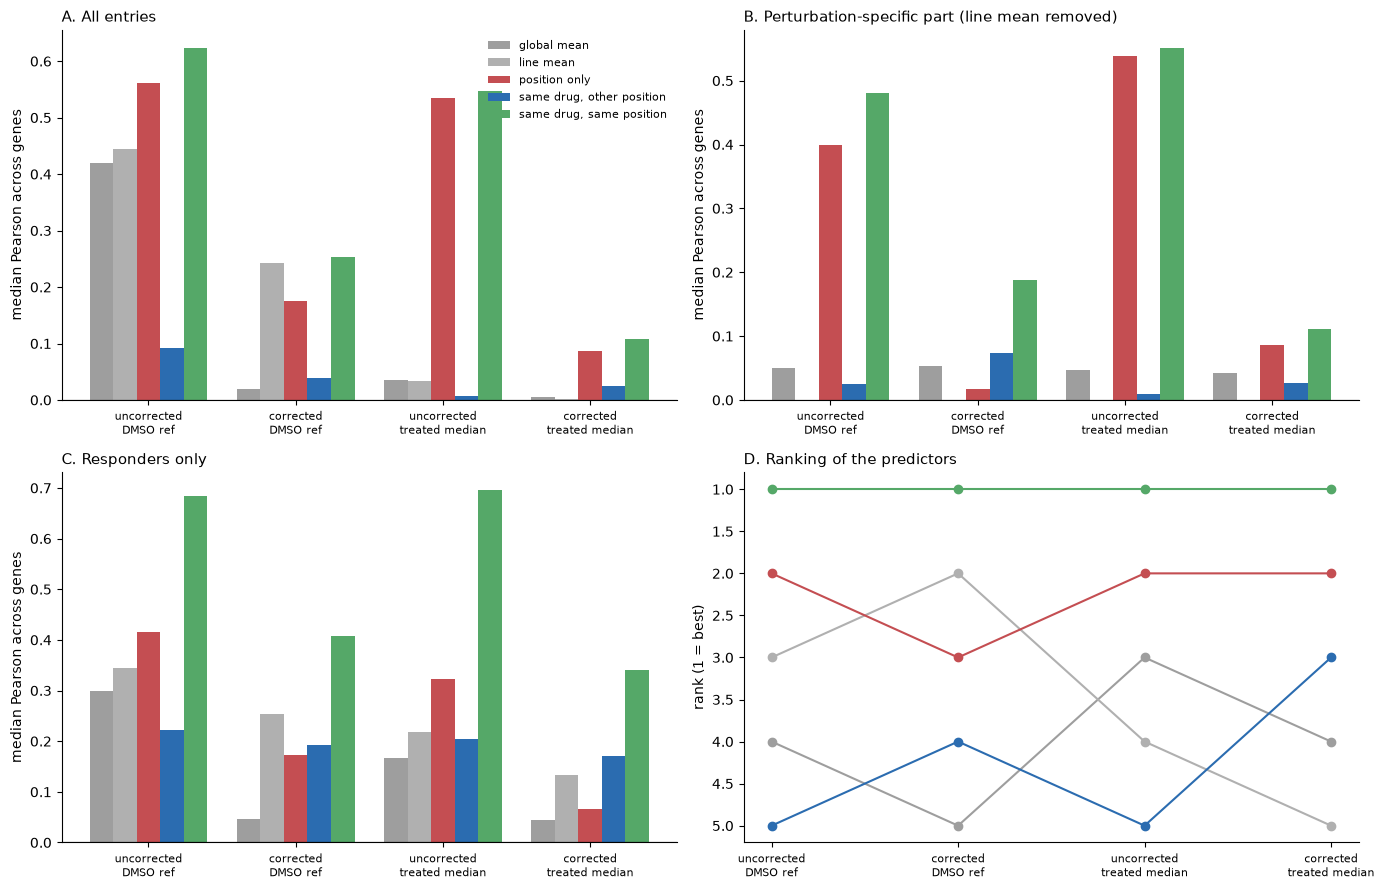

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_extend_analysis/aim3a_pilot.png True
[Aim 3a pilot] 42.8s | total 42.8 min


In [42]:
# B15. Aim 3a pilot: position-only predictor vs biology predictors, uncorrected vs corrected targets
t0 = time.time()


def med_ref(Y, T):
    return Y[0] - np.nanmedian(Y[0][~T["ref"][0]], axis=0, keepdims=True)


def rowcorr(a, b):
    """Pearson per row of two [C, G] arrays."""
    a = a - a.mean(1, keepdims=True); b = b - b.mean(1, keepdims=True)
    return (a * b).sum(1) / np.sqrt((a * a).sum(1) * (b * b).sum(1))


PL = sorted(TAH, key=lambda s: int(re.sub(r"\D", "", s)))
TARGETS = {"uncorrected, DMSO ref": lambda p: contrast(RUN[p][0]["naive"], TAH[p]["ref"])[0],
           "corrected, DMSO ref": lambda p: contrast(RUN[p][0]["signature"], TAH[p]["ref"])[0],
           "uncorrected, treated median": lambda p: med_ref(RUN[p][0]["naive"], TAH[p]),
           "corrected, treated median": lambda p: med_ref(RUN[p][0]["signature"], TAH[p])}
PREDS = ["global mean", "line mean", "position only", "same drug, other position", "same drug, same position"]
TR = {p: np.where(~TAH[p]["ref"][0])[0] for p in TAH}
out = []
for tname, f in TARGETS.items():
    Rt = {p: f(p).astype(np.float32) for p in TAH}
    for p in PL:
        oth = [q for q in PL if q != p]
        line_mean = np.nanmean(np.concatenate([Rt[q][TR[q]] for q in oth]), 0)        # [C, G]
        glob = np.broadcast_to(np.nanmean(line_mean, 0), line_mean.shape)
        for k in TR[p]:
            w, key = TAH[p]["well"][k], KEY[p][k]
            pos_o = [Rt[q][j] for q in oth for j in np.where(TAH[q]["well"] == w)[0]
                     if KEY[q][j] != key and not TAH[q]["ref"][0, j]]
            same = [Rt[q][j] for q in oth for j in np.where(KEY[q] == key)[0] if TAH[q]["well"][j] == w]
            diff = [Rt[q][j] for q in oth for j in np.where(KEY[q] == key)[0] if TAH[q]["well"][j] != w]
            P = {"global mean": glob, "line mean": line_mean,
                 "position only": np.nanmean(pos_o, 0) if pos_o else None,
                 "same drug, other position": np.nanmean(diff, 0) if diff else None,
                 "same drug, same position": np.nanmean(same, 0) if same else None}
            y = Rt[p][k]
            okc = ~np.isnan(y[:, 0])
            nr = RUN[p][1][0][k]
            for name, pr in P.items():
                if pr is None:
                    continue
                okp = okc & ~np.isnan(pr[:, 0])
                if not okp.any():
                    continue
                r = rowcorr(y[okp], pr[okp])
                rd = rowcorr(y[okp] - line_mean[okp], pr[okp] - line_mean[okp]) if name != "line mean" else np.full(okp.sum(), np.nan)
                for c, a, b in zip(np.where(okp)[0], r, rd):
                    out.append((tname, p, key, c, bool(nr[c]), name, a, b))
EV = pd.DataFrame(out, columns=["target", "plate", "drug", "line", "nonresponder", "predictor", "pearson", "pearson_delta"])
EV.to_csv(os.path.join(OUT_DIR, "aim3a_pilot_scores.csv.gz"), index=False)

tab = EV.groupby(["predictor", "target"]).pearson.median().unstack().reindex(PREDS)[list(TARGETS)]
tabd = EV.groupby(["predictor", "target"]).pearson_delta.median().unstack().reindex(PREDS)[list(TARGETS)]
tabr = EV[~EV.nonresponder].groupby(["predictor", "target"]).pearson.median().unstack().reindex(PREDS)[list(TARGETS)]
print("Median Pearson across genes, all entries:"); print(tab.round(3).to_string())
print("\nPerturbation-specific part (line mean removed):"); print(tabd.round(3).to_string())
print("\nResponders only:"); print(tabr.round(3).to_string())
print("\nRank of the predictors (1 = best, all entries):"); print(tab.rank(ascending=False).astype(int).to_string())
print("\nEntries per predictor:", EV[EV.target == list(TARGETS)[0]].groupby("predictor").size().reindex(PREDS).to_dict())

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
colors = ["#9e9e9e", "#b0b0b0", "#c44e52", "#2b6cb0", "#55a868"]
for a, (T_, ttl) in zip(ax.ravel()[:3], [(tab, "A. All entries"), (tabd, "B. Perturbation-specific part (line mean removed)"),
                                           (tabr, "C. Responders only")]):
    x = np.arange(len(TARGETS)); wdt = 0.16
    for i, (pname, col) in enumerate(zip(PREDS, colors)):
        a.bar(x + (i - 2) * wdt, T_.loc[pname].values, wdt, color=col, label=pname)
    a.set_xticks(x); a.set_xticklabels([t.replace(", ", "\n") for t in TARGETS], fontsize=8)
    a.axhline(0, color="k", lw=.8); a.set_ylabel("median Pearson across genes"); a.set_title(ttl, loc="left", fontsize=11)
ax[0, 0].legend(frameon=False, fontsize=8)
a = ax[1, 1]
rk = tab.rank(ascending=False)
for i, (pname, col) in enumerate(zip(PREDS, colors)):
    a.plot(range(len(TARGETS)), rk.loc[pname].values, "o-", color=col, label=pname)
a.invert_yaxis(); a.set_xticks(range(len(TARGETS))); a.set_xticklabels([t.replace(", ", "\n") for t in TARGETS], fontsize=8)
a.set_ylabel("rank (1 = best)"); a.set_title("D. Ranking of the predictors", loc="left", fontsize=11)
for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "aim3a_pilot.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))
stamp(t0, "Aim 3a pilot")

plate1 18s | plate2 37s | plate3 55s | plate4 74s | plate5 92s | plate6 111s | plate7 129s | plate8 148s | plate9 166s | plate10 185s | plate11 204s | plate12 222s | plate13 241s | plate14 259s | 
Test wells that get a g in the 3-way split (g from 4 plates): 93% (per test plate and fold: median 95%)

Median Pearson across genes, all entries (training = 4 plates):
predictor                          global mean  line mean  position only  same drug, other position  same drug, same position
target                                                                                                                       
uncorrected, DMSO ref                    0.406      0.418          0.522                      0.135                     0.558
uncorrected, treated median              0.032      0.031          0.498                      0.018                     0.478
internal controls, DMSO ref              0.018      0.173          0.113                      0.048                     0.201
inte

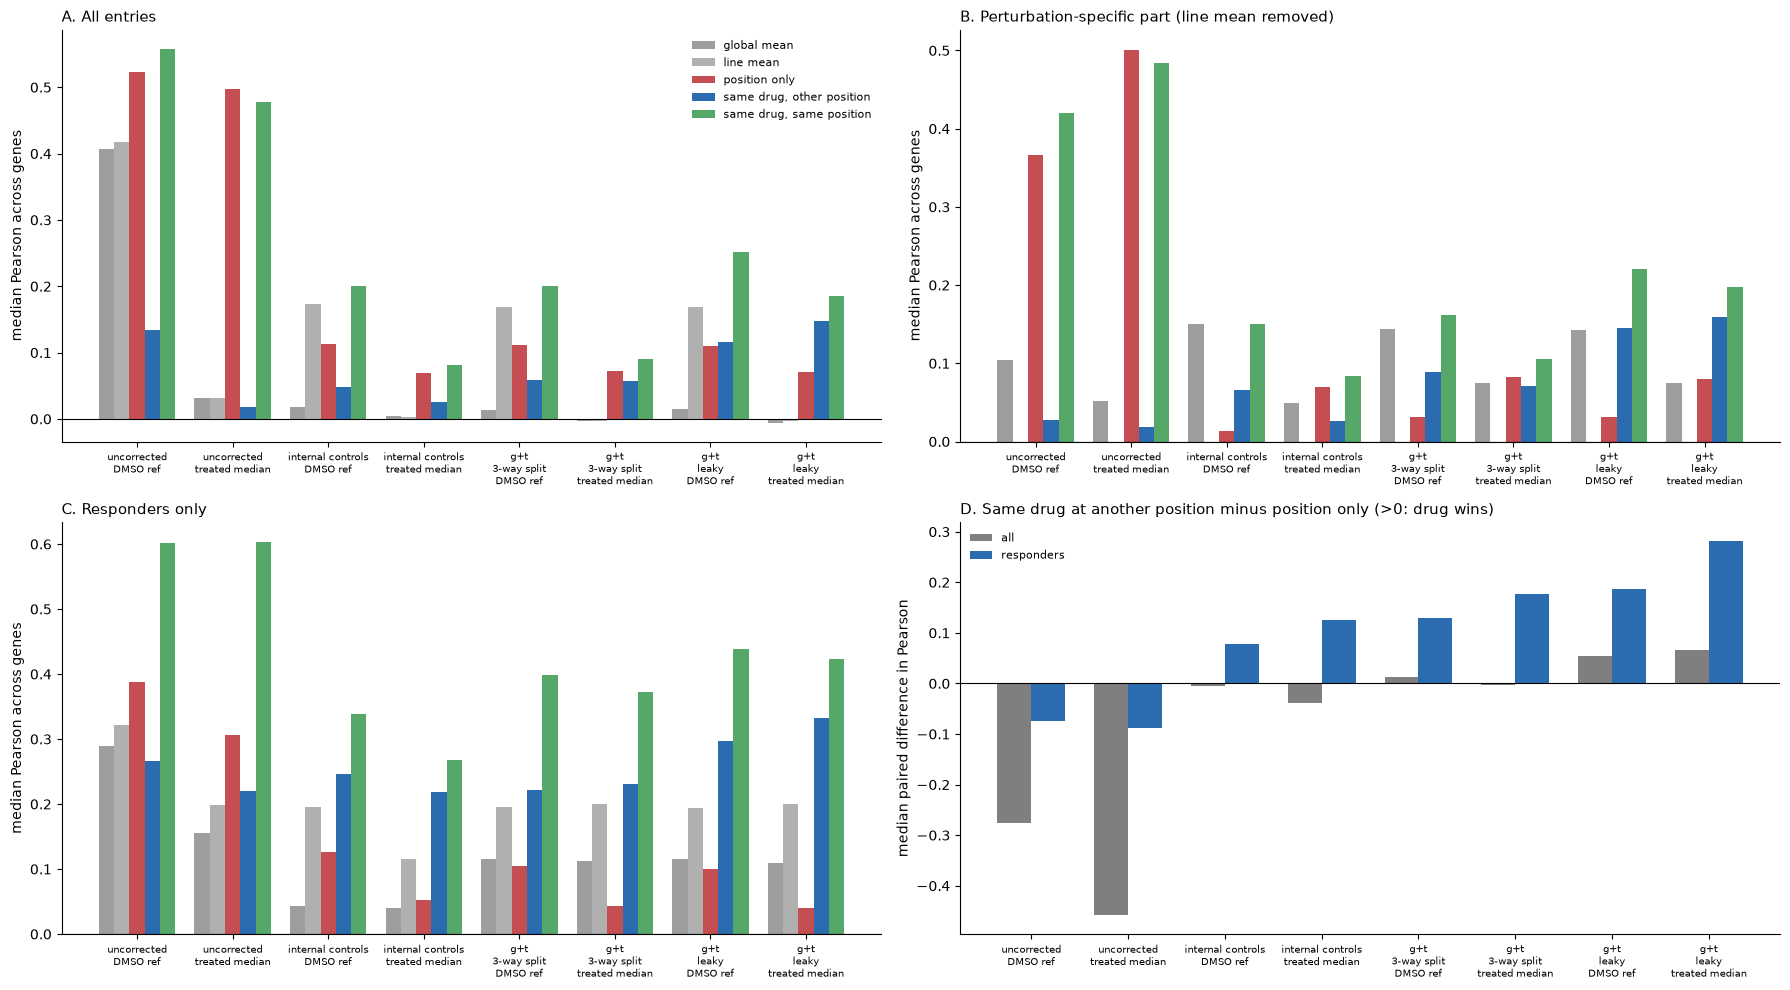

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_extend_analysis/aim3a_threeway.png True
[Aim 3a three-way split] 296.9s | total 47.7 min


In [43]:
# B16. Aim 3a pilot with a three-way split of the plates: correction | training | test
# For each test plate p, the other eight plates are split into two halves (C, Tr), used both ways (two folds):
#   * g and t of the g+t correction of p come only from C;
#   * the training plates Tr are corrected with g and t from Tr only (g of a plate never uses that plate);
#   * the predictors use only Tr.
# So the corrected test target and the predictors share no data. "g+t, all other plates (leaky)" is the
# correction of B10c (g from every other plate, including the training plates), kept to show the leak.
t0 = time.time()
import gc
pnum = lambda s: int(re.sub(r"\D", "", s))
PL = sorted(TAH, key=pnum)
TR = {p: np.where(~TAH[p]["ref"][0])[0] for p in TAH}
PREDS = ["global mean", "line mean", "position only", "same drug, other position", "same drug, same position"]


def med_ref(Y, T):
    return Y[0] - np.nanmedian(Y[0][~T["ref"][0]], axis=0, keepdims=True)


def rowcorr(a, b):
    a = a - a.mean(1, keepdims=True); b = b - b.mean(1, keepdims=True)
    return (a * b).sum(1) / np.sqrt((a * a).sum(1) * (b * b).sum(1))


def gt_correct(to_correct, param_plates, count):
    """g+t correction of `to_correct`, with g and t estimated only from `param_plates`."""
    Sd = {q: SIG[q] for q in param_plates}
    dec = decompose(Sd)
    g_of, n_oth = make_g_cf(Sd, dec)
    for q in to_correct:
        count.append((q, sum(g_of(q, KEY[q][k]) is not None for k in TR[q]), len(TR[q])))
    return {q: correct_cf(q, g_of, n_oth, dec) for q in to_correct}


def splits(p):
    oth = [q for q in PL if q != p]
    a, b = oth[0::2], oth[1::2]
    return [(a, b), (b, a)]          # (correction plates, training plates)


REFS = {"DMSO ref": lambda Y, q: contrast(Y, TAH[q]["ref"])[0],
        "treated median": lambda Y, q: med_ref(Y, TAH[q])}
CORR = ["uncorrected", "internal controls", "g+t, 3-way split", "g+t, leaky"]
TARGETS = [f"{c}, {r}" for c in CORR for r in REFS]


def score_plate(p, Tr, Rt, tname, fold, out):
    line_mean = np.nanmean(np.concatenate([Rt[q][TR[q]] for q in Tr]), 0)        # [C, G]
    glob = np.broadcast_to(np.nanmean(line_mean, 0), line_mean.shape)
    for k in TR[p]:
        w, key = TAH[p]["well"][k], KEY[p][k]
        pos_o = [Rt[q][j] for q in Tr for j in np.where(TAH[q]["well"] == w)[0]
                 if KEY[q][j] != key and not TAH[q]["ref"][0, j]]
        same = [Rt[q][j] for q in Tr for j in np.where(KEY[q] == key)[0] if TAH[q]["well"][j] == w]
        diff = [Rt[q][j] for q in Tr for j in np.where(KEY[q] == key)[0] if TAH[q]["well"][j] != w]
        P = {"global mean": glob, "line mean": line_mean,
             "position only": np.nanmean(pos_o, 0) if pos_o else None,
             "same drug, other position": np.nanmean(diff, 0) if diff else None,
             "same drug, same position": np.nanmean(same, 0) if same else None}
        y = Rt[p][k]
        okc = ~np.isnan(y[:, 0])
        nr = RUN[p][1][0][k]
        for name, pr in P.items():
            if pr is None:
                continue
            okp = okc & ~np.isnan(pr[:, 0])
            if not okp.any():
                continue
            r = rowcorr(y[okp], pr[okp])
            rd = (rowcorr(y[okp] - line_mean[okp], pr[okp] - line_mean[okp]) if name != "line mean"
                  else np.full(okp.sum(), np.nan))
            for c, a, b in zip(np.where(okp)[0], r, rd):
                out.append((tname, fold, p, w, key, c, bool(nr[c]), name, a, b))


out, GCOUNT = [], []
for p in PL:
    for fold, (C, Tr) in enumerate(splits(p)):
        cnt = []
        Ycorr = {"uncorrected": {q: RUN[q][0]["naive"] for q in Tr + [p]},
                 "internal controls": {q: RUN[q][0]["signature"] for q in Tr + [p]},
                 "g+t, 3-way split": {**gt_correct(Tr, Tr, []), **gt_correct([p], C, cnt)},
                 "g+t, leaky": {q: RUN[q][0]["g+t cf"] for q in Tr + [p]}}
        GCOUNT += [dict(test=p, fold=fold, n_g=a, n_treated=b) for _, a, b in cnt]
        for cname, Yd in Ycorr.items():
            for rname, f in REFS.items():
                Rt = {q: f(Yd[q], q).astype(np.float32) for q in Yd}
                score_plate(p, Tr, Rt, f"{cname}, {rname}", fold, out)
                del Rt
        del Ycorr; gc.collect()
    print(p, f"{time.time() - t0:.0f}s", end=" | ", flush=True)
print()
EV3 = pd.DataFrame(out, columns=["target", "fold", "plate", "well", "drug", "line", "nonresponder",
                                 "predictor", "pearson", "pearson_delta"])
del out; gc.collect()
EV3.to_csv(os.path.join(OUT_DIR, "aim3a_threeway_scores.csv.gz"), index=False)
GC = pd.DataFrame(GCOUNT)
print(f"Test wells that get a g in the 3-way split (g from 4 plates): {GC.n_g.sum() / GC.n_treated.sum():.0%} "
      f"(per test plate and fold: median {np.median(GC.n_g / GC.n_treated):.0%})")

# tables: rows = targets, columns = predictors
tab = EV3.groupby(["target", "predictor"]).pearson.median().unstack().reindex(TARGETS)[PREDS]
tabd = EV3.groupby(["target", "predictor"]).pearson_delta.median().unstack().reindex(TARGETS)[PREDS]
tabr = EV3[~EV3.nonresponder].groupby(["target", "predictor"]).pearson.median().unstack().reindex(TARGETS)[PREDS]
print("\nMedian Pearson across genes, all entries (training = 4 plates):"); print(tab.round(3).to_string())
print("\nPerturbation-specific part (line mean removed):"); print(tabd.round(3).to_string())
print("\nResponders only:"); print(tabr.round(3).to_string())
print("\nRank of the predictors (1 = best, all entries):"); print(tab.rank(axis=1, ascending=False).astype(int).to_string())

# paired test on the same entries: same drug at another position vs position only
pv = EV3.pivot_table(index=["target", "fold", "plate", "well", "drug", "line", "nonresponder"],
                     columns="predictor", values="pearson", aggfunc="first")
pv = pv.dropna(subset=["position only", "same drug, other position"]).reset_index()
pv["d"] = pv["same drug, other position"] - pv["position only"]
rows = []
for t in TARGETS:
    for grp, sub in [("all", pv[pv.target == t]), ("responders", pv[(pv.target == t) & ~pv.nonresponder])]:
        rows.append(dict(target=t, entries=grp, n=len(sub), median_diff=sub.d.median(),
                         drug_wins=(sub.d > 0).mean(), wilcoxon_p=wilcoxon(sub.d).pvalue if len(sub) > 10 else np.nan))
PAIR = pd.DataFrame(rows)
PAIR.to_csv(os.path.join(OUT_DIR, "aim3a_threeway_paired.csv"), index=False)
print("\nSame entries, (same drug at another position) minus (position only):")
print(PAIR.round(3).to_string(index=False))

fig, ax = plt.subplots(2, 2, figsize=(18, 10))
colors = ["#9e9e9e", "#b0b0b0", "#c44e52", "#2b6cb0", "#55a868"]
lab = [t.replace(", ", "\n") for t in TARGETS]
x = np.arange(len(TARGETS)); wdt = 0.16
for a, (T_, ttl) in zip(ax.ravel()[:3], [(tab, "A. All entries"), (tabd, "B. Perturbation-specific part (line mean removed)"),
                                           (tabr, "C. Responders only")]):
    for i, (pname, col) in enumerate(zip(PREDS, colors)):
        a.bar(x + (i - 2) * wdt, T_[pname].values, wdt, color=col, label=pname)
    a.set_xticks(x); a.set_xticklabels(lab, fontsize=7)
    a.axhline(0, color="k", lw=.8); a.set_ylabel("median Pearson across genes"); a.set_title(ttl, loc="left", fontsize=11)
ax[0, 0].legend(frameon=False, fontsize=8)
a = ax[1, 1]
for i, (grp, col) in enumerate([("all", "#7f7f7f"), ("responders", "#2b6cb0")]):
    v = PAIR[PAIR.entries == grp].set_index("target").reindex(TARGETS).median_diff.values
    a.bar(x + (i - 0.5) * 0.35, v, 0.35, color=col, label=grp)
a.axhline(0, color="k", lw=.8); a.set_xticks(x); a.set_xticklabels(lab, fontsize=7)
a.set_ylabel("median paired difference in Pearson")
a.set_title("D. Same drug at another position minus position only (>0: drug wins)", loc="left", fontsize=11)
a.legend(frameon=False, fontsize=8)
for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "aim3a_threeway.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))
stamp(t0, "Aim 3a three-way split")

In [44]:
# B17b. Same drug at different positions with DISJOINT plate sets for the two plates being compared
# B17 removed only the partner plate, so g of both plates still came from the same remaining plates
# (the same g added to both -> agreement still inflated). Here, for a pair (p1, p2), the other seven plates
# are split into two halves O1 and O2, each holding the drug if possible; p1 is corrected with O1 only and
# p2 with O2 only, then the halves are swapped (two folds). The two corrected profiles share no data.
t0 = time.time()
MO_DISJ = 2      # with 3-4 plates per half, no position reaches MIN_OTHER = 3

def med_ref(Y, T):
    return Y[0] - np.nanmedian(Y[0][~T["ref"][0]], axis=0, keepdims=True)


DISJ = {}


def gt_from(p, plates):
    """g+t correction of p with g and t estimated only from `plates`; also says whether p's drug got a g."""
    key = (p, tuple(sorted(plates)))
    if key not in DISJ:
        Sd = {q: SIG[q] for q in plates}
        dec = decompose(Sd)
        g_of, n_oth = make_g_cf(Sd, dec, min_other=MO_DISJ)
        Y = correct_cf(p, g_of, n_oth, dec)
        DISJ[key] = ({"DMSO ref": contrast(Y, TAH[p]["ref"])[0].astype(np.float32),
                      "treated median": med_ref(Y, TAH[p]).astype(np.float32)}, g_of)
    return DISJ[key]


def halves(d, p1, p2):
    oth = [q for q in sorted(TAH, key=lambda s: int(re.sub(r"\D", "", s))) if q not in (p1, p2)]
    has = [q for q in oth if (TAH[q]["drug"] == d).any()]
    rest = [q for q in oth if q not in has]
    O1, O2 = has[0::2] + rest[0::2], has[1::2] + rest[1::2]
    return [(O1, O2), (O2, O1)]


REFF = {"DMSO ref": lambda Y, p: contrast(Y, TAH[p]["ref"])[0],
        "treated median": lambda Y, p: med_ref(Y, TAH[p])}
M17 = ["naive", "signature", "g+t leaky", "g+t disjoint"]
rows = []
for d in sorted(set(GENO.drug)):
    car = carriers(rule_for(d)[1])
    members = [(p, k) for p in TAH for k in np.where(TAH[p]["drug"] == d)[0]]
    for (p1, k1), (p2, k2) in [(a, b) for i, a in enumerate(members) for b in members[i + 1:]]:
        if TAH[p1]["well"][k1] == TAH[p2]["well"][k2]:
            continue
        for fold, (O1, O2) in enumerate(halves(d, p1, p2)):
            (C1, g1), (C2, g2) = gt_from(p1, O1), gt_from(p2, O2)
            both_g = g1(p1, KEY[p1][k1]) is not None and g2(p2, KEY[p2][k2]) is not None
            for rname, f in REFF.items():
                A = {"naive": f(RUN[p1][0]["naive"], p1), "signature": f(RUN[p1][0]["signature"], p1),
                     "g+t leaky": f(RUN[p1][0]["g+t cf"], p1), "g+t disjoint": C1[rname]}
                B = {"naive": f(RUN[p2][0]["naive"], p2), "signature": f(RUN[p2][0]["signature"], p2),
                     "g+t leaky": f(RUN[p2][0]["g+t cf"], p2), "g+t disjoint": C2[rname]}
                for c in np.where(car)[0]:
                    r = dict(reference=rname, drug=d, plates=f"{p1}-{p2}", fold=fold, line=LINES[c], both_g=both_g)
                    for m in M17:
                        a, b = A[m][k1, c], B[m][k2, c]
                        r[m] = np.nan if np.isnan(a[0] + b[0]) else np.corrcoef(a, b)[0, 1]
                    rows.append(r)
    print(d, f"{time.time() - t0:.0f}s", end=" | ", flush=True)
print()
X17 = pd.DataFrame(rows).dropna(subset=M17)
X17.to_csv(os.path.join(OUT_DIR, "tahoe_agreement_different_positions_disjoint.csv"), index=False)
print(f"Rows where both plates got a g from their half: {X17.both_g.mean():.0%}")
for title, sub in [("All rows", X17), ("Only rows where both plates got a g", X17[X17.both_g])]:
    print(f"\n{title}: carriers, same drug at different positions (median Pearson between plates)")
    print(sub.groupby(["reference", "drug"])[M17].median().round(3)
          .assign(n=sub.groupby(["reference", "drug"]).size()).to_string())
    print(sub.groupby("reference")[M17].median().round(3).assign(n=sub.groupby("reference").size()).to_string())
    for rname, s in sub.groupby("reference"):
        print(f"  {rname}: g+t disjoint > signature in {(s['g+t disjoint'] > s.signature).mean():.0%} "
              f"(Wilcoxon p = {wilcoxon(s['g+t disjoint'], s.signature).pvalue:.2g}) | "
              f"> naive in {(s['g+t disjoint'] > s.naive).mean():.0%} (p = {wilcoxon(s['g+t disjoint'], s.naive).pvalue:.2g})")
del DISJ
stamp(t0, "different positions, disjoint plate sets")

Adagrasib 242s | Alpelisib 242s | Binimetinib 274s | Cobimetinib 274s | Dabrafenib 274s | Encorafenib 274s | Trametinib 379s | Vemurafenib 379s | 
Rows where both plates got a g from their half: 97%

All rows: carriers, same drug at different positions (median Pearson between plates)
                            naive  signature  g+t leaky  g+t disjoint    n
reference      drug                                                       
DMSO ref       Adagrasib    0.479      0.601      0.611         0.589  670
               Binimetinib  0.570      0.466      0.574         0.532  630
               Trametinib   0.505      0.377      0.567         0.486  754
treated median Adagrasib    0.480      0.685      0.694         0.664  670
               Binimetinib  0.431      0.475      0.619         0.559  630
               Trametinib   0.508      0.441      0.648         0.558  754
                naive  signature  g+t leaky  g+t disjoint     n
reference                                          

In [45]:
# B18. Remove the last leaky g+t numbers: disjoint plate sets for (1) replicate plates 6 vs 14 and
# (2) the sensitivity of g to the drug key (drug name, drug and dose, partial pooling across doses)
# Two plates that are compared are always corrected from two disjoint halves of the other plates.
t0 = time.time()
import gc
MO_DISJ = 2                    # a half has only 3-4 plates, so no position reaches MIN_OTHER = 3
KAPPA = globals().get("KAPPA", 1.0)
if "carriers" not in globals():                       # defined in B4; not restored from the snapshot
    VARIANT_RULES = {
        "KRAS G12C": (["adagrasib", "sotorasib", "divarasib"], {"KRAS"}, r"G12C"),
        "BRAF V600": (["vemurafenib", "dabrafenib", "encorafenib"], {"BRAF"}, r"V600"),
        "MAPK active": (["trametinib", "cobimetinib", "binimetinib", "selumetinib", "mirdametinib"],
                        {"BRAF", "KRAS", "NRAS", "HRAS"}, r"V600|G12|G13|Q61"),
        "PIK3CA hotspot": (["alpelisib", "inavolisib"], {"PIK3CA"}, r"H1047|E545|E542"),
    }
    CL = pd.read_parquet(os.path.join(TAHOE_META, "cell_line_metadata.parquet"))
    var = {l: list(zip(g.Driver_Gene_Symbol.astype(str).str.upper(), g.Driver_ProtEffect_or_CdnaEffect.astype(str)))
           for l, g in CL.groupby(CL.cell_name.astype(str))}

    def rule_for(drug):
        d = str(drug).lower()
        for name, rule in VARIANT_RULES.items():
            if any(x in d for x in rule[0]):
                return name, rule
        return None, None

    def carriers(rule):
        _, genes, rx = rule
        return np.array([any(g in genes and re.search(rx, e) for g, e in var.get(l, [])) for l in LINES])


PLS = sorted(TAH, key=lambda s: int(re.sub(r"\D", "", s)))


def med_ref(Y, T):
    return Y[0] - np.nanmedian(Y[0][~T["ref"][0]], axis=0, keepdims=True)


REFF = {"DMSO ref": lambda Y, p: contrast(Y, TAH[p]["ref"])[0],
        "treated median": lambda Y, p: med_ref(Y, TAH[p])}

if "make_g_pp" not in globals():                      # defined in B10d; not restored from the snapshot
    KEY_NAME = {p: TAH[p]["drug"].copy() for p in TAH}

    def make_g_pp(Sd, dec, min_other=MIN_OTHER, lam=LAM, kappa=KAPPA):
        at = {}
        for q in Sd:
            for j in range(len(Sd[q])):
                if not np.isnan(Sd[q][j, 0]):
                    at.setdefault(TAH[q]["well"][j], []).append(KEY_NAME[q][j])
        good = lambda q, j: (not np.isnan(Sd[q][j, 0])
                             and sum(x != KEY_NAME[q][j] for x in at.get(TAH[q]["well"][j], [])) >= min_other)

        def g_of(p, k):
            if TAH[p]["ref"][0, k]:
                return None
            name, key = KEY_NAME[p][k], KEY_DOSE[p][k]
            inst = [(q, j) for q in Sd if q != p for j in np.where(KEY_NAME[q] == name)[0] if good(q, j)]
            if not inst:
                return None
            res = {(q, j): Sd[q][j] - dec["t"][TAH[q]["well"][j]] for q, j in inst}
            g_name = np.sum(list(res.values()), 0) / (len(res) + lam)
            same = [v for (q, j), v in res.items() if KEY_DOSE[q][j] == key]
            return (np.sum(same, 0) + kappa * g_name) / (len(same) + kappa) if same else g_name
        n_other = lambda w, name: sum(x != name for x in at.get(w, []))
        return g_of, n_other

    def correct_pp(p, g_of, n_other, dec, Ysig=None, info=None):
        out, nr, info0, fl = RUN[p]
        info = info0 if info is None else info
        Y1 = (out["signature"] if Ysig is None else Ysig).copy()
        B, Y0 = info["B"], info["Y0"]
        for k in range(Y1.shape[1]):
            w = TAH[p]["well"][k]
            gk = g_of(p, k)
            tk = dec["t"].get(w) if n_other(w, KEY_NAME[p][k]) >= MIN_OTHER else None
            for c in range(Y1.shape[2]):
                if np.isnan(TAH[p]["Y"][0, k, c, 0]):
                    continue
                if fl[0, k, c]:
                    if tk is not None:
                        Y1[0, k, c] = Y0[0, k, c] - B[c] * tk
                elif gk is not None:
                    Y1[0, k, c] = Y1[0, k, c] + B[c] * gk
        return Y1


def correct_from(p, plates, variant):
    """g+t correction of plate p with everything estimated from `plates` only. variant: name | dose | pool."""
    global KEY, REF_KEYS
    Sd = {q: SIG[q] for q in plates}
    if variant == "dose":                              # key g by drug and dose (temporarily swap the key)
        key0, ref0 = KEY, REF_KEYS
        KEY = KEY_DOSE
        REF_KEYS = {k for q in TAH for k, r in zip(KEY_DOSE[q], TAH[q]["ref"][0]) if r}
        try:
            dec = decompose(Sd)
            g_of, n_oth = make_g_cf(Sd, dec, min_other=MO_DISJ)
            Y = correct_cf(p, g_of, n_oth, dec)
            flags = np.array([g_of(p, KEY_DOSE[p][k]) is not None for k in range(len(KEY_DOSE[p]))])
        finally:
            KEY, REF_KEYS = key0, ref0
    else:
        dec = decompose(Sd)
        if variant == "name":
            g_of, n_oth = make_g_cf(Sd, dec, min_other=MO_DISJ)
            Y = correct_cf(p, g_of, n_oth, dec)
            flags = np.array([g_of(p, KEY[p][k]) is not None for k in range(len(KEY[p]))])
        else:
            g_of, n_oth = make_g_pp(Sd, dec, min_other=MO_DISJ)
            Y = correct_pp(p, g_of, n_oth, dec)
            flags = np.array([g_of(p, k) is not None for k in range(len(KEY[p]))])
    return {r: f(Y, p).astype(np.float32) for r, f in REFF.items()}, flags


# ---------- (1) replicate plates 6 and 14, same well ----------
PA, PB = "plate6", "plate14"
TA, TB = TAH[PA], TAH[PB]
pos_b = {(w, k): j for j, (w, k) in enumerate(zip(TB["well"], KEY[PB]))}
match = [(k, pos_b[(w, key)]) for k, (w, key) in enumerate(zip(TA["well"], KEY[PA]))
         if (w, key) in pos_b and not TA["ref"][0, k]]
nrA, nrB = RUN[PA][1][0], RUN[PB][1][0]
oth = [q for q in PLS if q not in (PA, PB)]
O1, O2 = oth[0::2], oth[1::2]
g_a, n_a = make_g_cf({q: SIG[q] for q in SIG if q != PB}, DEC)   # B13b version: shares the other plates
g_b, n_b = make_g_cf({q: SIG[q] for q in SIG if q != PA}, DEC)
LEAKY = {PA: correct_cf(PA, g_a, n_a, DEC), PB: correct_cf(PB, g_b, n_b, DEC)}
rows = []
for fold, (HA, HB) in enumerate([(O1, O2), (O2, O1)]):
    (CA, fA), (CB, fB) = correct_from(PA, HA, "name"), correct_from(PB, HB, "name")
    for rname, f in REFF.items():
        A = {"naive": f(RUN[PA][0]["naive"], PA), "signature": f(RUN[PA][0]["signature"], PA),
             "g+t shared": f(LEAKY[PA], PA), "g+t disjoint": CA[rname]}
        B = {"naive": f(RUN[PB][0]["naive"], PB), "signature": f(RUN[PB][0]["signature"], PB),
             "g+t shared": f(LEAKY[PB], PB), "g+t disjoint": CB[rname]}
        for k, j in match:
            for c in range(len(LINES)):
                if nrA[k, c] and nrB[j, c]:
                    kind = "non-responders"
                elif not nrA[k, c] and not nrB[j, c]:
                    kind = "responders"
                else:
                    continue
                vals = {m: (A[m][k, c], B[m][j, c]) for m in A}
                if any(np.isnan(a[0] + b[0]) for a, b in vals.values()):
                    continue
                r = dict(reference=rname, kind=kind, fold=fold, both_g=bool(fA[k] and fB[j]))
                r.update({m: np.corrcoef(a, b)[0, 1] for m, (a, b) in vals.items()})
                rows.append(r)
REP18 = pd.DataFrame(rows)
REP18.to_csv(os.path.join(OUT_DIR, "tahoe_replicate_6_14_disjoint.csv"), index=False)
M4 = ["naive", "signature", "g+t shared", "g+t disjoint"]
print(f"(1) Plates {PA} vs {PB}, same well. Halves: {O1} | {O2}. Entries where both plates got a g: {REP18.both_g.mean():.0%}")
print(REP18.groupby(["reference", "kind"])[M4].median().round(3)
      .assign(n=REP18.groupby(["reference", "kind"]).size() // 2).to_string())
del LEAKY; gc.collect()
stamp(t0, "replicate plates, disjoint")

# ---------- (2) sensitivity to the drug key, same drug at different positions ----------
CACHE = {}


def corr_cached(p, plates, variant):
    key = (variant, p, tuple(sorted(plates)))
    if key not in CACHE:
        CACHE[key] = correct_from(p, plates, variant)
    return CACHE[key]


def halves(d, p1, p2):
    o = [q for q in PLS if q not in (p1, p2)]
    has = [q for q in o if (TAH[q]["drug"] == d).any()]
    rest = [q for q in o if q not in has]
    return [(has[0::2] + rest[0::2], has[1::2] + rest[1::2]), (has[1::2] + rest[1::2], has[0::2] + rest[0::2])]


VARIANTS = ["name", "dose", "pool"]
rows = []
for d in ["Binimetinib", "Trametinib"]:
    car = carriers(rule_for(d)[1])
    members = [(p, k) for p in TAH for k in np.where(TAH[p]["drug"] == d)[0]]
    for (p1, k1), (p2, k2) in [(a, b) for i, a in enumerate(members) for b in members[i + 1:]]:
        if TAH[p1]["well"][k1] == TAH[p2]["well"][k2]:
            continue
        for fold, (H1, H2) in enumerate(halves(d, p1, p2)):
            res = {v: (corr_cached(p1, H1, v), corr_cached(p2, H2, v)) for v in VARIANTS}
            for rname in REFF:
                for c in np.where(car)[0]:
                    r = dict(reference=rname, drug=d, plates=f"{p1}-{p2}", fold=fold,
                             same_dose=KEY_DOSE[p1][k1] == KEY_DOSE[p2][k2])
                    for v, ((C1, f1), (C2, f2)) in res.items():
                        a, b = C1[rname][k1, c], C2[rname][k2, c]
                        r[v] = np.nan if np.isnan(a[0] + b[0]) else np.corrcoef(a, b)[0, 1]
                        r[f"g_{v}"] = bool(f1[k1] and f2[k2])
                    rows.append(r)
    print(d, f"{time.time() - t0:.0f}s", end=" | ", flush=True)
print()
SENS18 = pd.DataFrame(rows).dropna(subset=VARIANTS)
SENS18.to_csv(os.path.join(OUT_DIR, "tahoe_gt_key_sensitivity_disjoint.csv"), index=False)
print("(2) Carriers, same drug at different positions, disjoint halves: median Pearson by drug key")
print(SENS18.groupby(["reference", "drug"])[VARIANTS].median().round(3)
      .assign(n=SENS18.groupby(["reference", "drug"]).size()).to_string())
print("\nShare of rows where both plates got a g:", {v: round(float(SENS18[f"g_{v}"].mean()), 2) for v in VARIANTS})
print("\nSame dose vs different dose (drug-name key):")
print(SENS18.groupby(["reference", "same_dose"])[VARIANTS].median().round(3).to_string())
del CACHE; gc.collect()
stamp(t0, "key sensitivity, disjoint")

(1) Plates plate6 vs plate14, same well. Halves: ['plate1', 'plate3', 'plate5', 'plate8', 'plate10', 'plate12'] | ['plate2', 'plate4', 'plate7', 'plate9', 'plate11', 'plate13']. Entries where both plates got a g: 98%
                               naive  signature  g+t shared  g+t disjoint     n
reference      kind                                                            
DMSO ref       non-responders  0.559      0.290       0.345         0.284  3786
               responders      0.738      0.597       0.624         0.591    77
treated median non-responders  0.456      0.080       0.211         0.102  3786
               responders      0.694      0.610       0.647         0.612    77
[replicate plates, disjoint] 6.2s | total 54.2 min
Binimetinib 52s | Trametinib 182s | 
(2) Carriers, same drug at different positions, disjoint halves: median Pearson by drug key
                             name   dose   pool     n
reference      drug                                  
DMSO ref       

In [46]:
# B19. Pre-registration of the confirmatory drug list (plate metadata only, no scores)
# Reads only the sample -> well -> drug map and the cell-line mutation table. Nothing here touches expression data.
# Run after the setup cell; it does not need the snapshot.
import os, re, json, datetime, itertools
import pandas as pd
ALREADY = os.path.exists(os.path.join(OUT_DIR, "confirmatory_registration.json"))

NEW_PLATES = ["plate4", "plate5", "plate7", "plate8", "plate9"]
TARGETED = {   # drug-name substrings and the variant each drug targets (same rules as B4)
    "KRAS G12C": ["adagrasib", "sotorasib", "divarasib"],
    "KRAS G12D": ["mrtx1133"],
    "BRAF V600": ["vemurafenib", "dabrafenib", "encorafenib"],
    "MAPK active": ["trametinib", "cobimetinib", "binimetinib", "selumetinib", "mirdametinib"],
    "PIK3CA hotspot": ["alpelisib", "inavolisib"],
    "EGFR activating": ["osimertinib", "almonertinib", "erlotinib", "gefitinib", "afatinib", "dacomitinib",
                        "lazertinib", "furmonertinib", "icotinib", "aumolertinib", "befotertinib"],
}
pnum = lambda s: int(re.sub(r"\D", "", str(s)))

wm = pd.read_csv(TAHOE_MAP_INFERRED)
if os.path.exists(TAHOE_MAP_BARCODE):          # barcode-based map wins where it exists (plates 6, 13, 14)
    wb = pd.read_csv(TAHOE_MAP_BARCODE)
    wm = pd.concat([wm[~wm.plate.isin(wb.plate.unique())], wb[["plate", "sample", "well", "drug"]]], ignore_index=True)
wm["plate"] = wm["plate"].astype(str)
print("Plates in the map:", sorted(wm.plate.unique(), key=pnum))
missing = [p for p in NEW_PLATES if p not in set(wm.plate)]
if missing:
    print("WARNING: no map for", missing, "- the list cannot be fixed until these plates are mapped")


def variant_of(drug):
    d = str(drug).lower()
    for v, names in TARGETED.items():
        if any(n in d for n in names):
            return v
    return None


wm["variant"] = wm["drug"].map(variant_of)
tg = wm[wm.variant.notna()].drop_duplicates(["plate", "well", "drug"])

rows = []
for drug, g in tg.groupby("drug"):
    occ = sorted(set(zip(g.plate, g.well)), key=lambda x: (pnum(x[0]), x[1]))
    # confirmatory pairs: two occurrences at different wells, at least one on a new plate
    conf = [(a, b) for a, b in itertools.combinations(occ, 2)
            if a[1] != b[1] and a[0] != b[0] and (a[0] in NEW_PLATES or b[0] in NEW_PLATES)]
    rows.append(dict(
        drug=drug, variant=g.variant.iat[0],
        plates=",".join(sorted(set(g.plate), key=pnum)),
        new_plates=",".join(p for p in sorted(set(g.plate), key=pnum) if p in NEW_PLATES),
        n_positions=g.well.nunique(),
        positions=";".join(f"{p}:{w}" for p, w in occ),
        n_confirmatory_pairs=len(conf),
        eligible=(g.well.nunique() >= 2) and len(conf) > 0))
REG = pd.DataFrame(rows).sort_values(["eligible", "variant", "drug"], ascending=[False, True, True])
pd.set_option("display.width", 250, "display.max_colwidth", 120)
print(REG.to_string(index=False))


eligible = REG[REG.eligible & ~REG.variant.isin(["EGFR activating"])].drug.tolist()
record = dict(
    registered_on=datetime.datetime.now().astimezone().isoformat(timespec="seconds"),
    source="plate metadata only (sample -> well -> drug map); no expression data or scores were read",
    new_plates=NEW_PLATES,
    eligible_drugs=eligible,
    n_eligible=len(eligible),
    rule=("eligible = targeted drug at >= 2 positions over the 14 plates with >= 1 pair at different wells on "
          "different plates that includes a new plate; EGFR excluded (no carriers). A drug that later gets no g "
          "from disjoint halves is reported as not testable, not dropped silently."),
    criterion=("per drug: carrier-line mean of (g+t disjoint - uncorrected), one-sided Wilcoxon over lines, p<0.05, "
               "treated-well reference primary; success if >= 2/3 of eligible drugs gain. If fewer than 3 eligible: "
               "one pooled test over the carrier lines of all eligible drugs; if 1, its own line-level test."),
)
os.makedirs(OUT_DIR, exist_ok=True)
if ALREADY:
    print("Registration already exists (commit 02bcb19): NOT rewritten. The table above is for checking only.")
else:
    REG.to_csv(os.path.join(OUT_DIR, "confirmatory_drug_registry.csv"), index=False)
    with open(os.path.join(OUT_DIR, "confirmatory_registration.json"), "w") as f:
        json.dump(record, f, indent=2)
print("\nRegistered:", json.dumps(record, indent=2))
print("\nNext, in a terminal (from the project folder):")
print(f"  git add {OUT_DIR}/confirmatory_drug_registry.csv {OUT_DIR}/confirmatory_registration.json")
print('  git commit -m "Pre-register confirmatory drug list (metadata only, before scoring plates 4, 5, 7-9)"')

Plates in the map: ['plate1', 'plate2', 'plate3', 'plate4', 'plate5', 'plate6', 'plate7', 'plate8', 'plate9', 'plate10', 'plate11', 'plate12', 'plate13', 'plate14']
                        drug         variant                                                                                                 plates                         new_plates  n_positions                                                                                                                                                                                                  positions  n_confirmatory_pairs  eligible
                    Afatinib EGFR activating                                                      plate1,plate2,plate3,plate7,plate8,plate9,plate13               plate7,plate8,plate9            5                                                                                                      plate1:C12;plate2:C12;plate3:C12;plate7:B10;plate8:B10;plate9:B10;plate13:C10;plate13:D10;plate13:E10      

In [47]:
# B19b. Amendment 1 to the registration: normalize every compound to its parent (salts and solvates merged)
# Metadata only: no expression data or scores. Does NOT overwrite the first registration (B19); writes a separate file.
import os, re, json, datetime, itertools
import pandas as pd


def parent(name):
    """Parent compound: drop a trailing parenthetical (salt, solvate, hydrate), e.g. 'Trametinib (DMSO_TF solvate)'.
    Leading stereo prefixes such as '(S)-crizotinib' are kept."""
    return re.sub(r"\s*\([^()]*\)\s*$", "", str(name)).strip()


NEW_PLATES = ["plate4", "plate5", "plate7", "plate8", "plate9"]
TARGETED = {
    "KRAS G12C": ["adagrasib", "sotorasib", "divarasib"],
    "KRAS G12D": ["mrtx1133"],
    "BRAF V600": ["vemurafenib", "dabrafenib", "encorafenib"],
    "MAPK active": ["trametinib", "cobimetinib", "binimetinib", "selumetinib", "mirdametinib"],
    "PIK3CA hotspot": ["alpelisib", "inavolisib"],
    "EGFR activating": ["osimertinib", "almonertinib", "erlotinib", "gefitinib", "afatinib", "dacomitinib",
                        "lazertinib", "furmonertinib", "icotinib", "aumolertinib", "befotertinib"],
}
pnum = lambda s: int(re.sub(r"\D", "", str(s)))
variant_of = lambda d: next((v for v, ns in TARGETED.items() if any(n in str(d).lower() for n in ns)), None)

wm = pd.read_csv(TAHOE_MAP_INFERRED)
if os.path.exists(TAHOE_MAP_BARCODE):
    wb = pd.read_csv(TAHOE_MAP_BARCODE)
    wm = pd.concat([wm[~wm.plate.isin(wb.plate.unique())], wb[["plate", "sample", "well", "drug"]]], ignore_index=True)
wm["plate"] = wm["plate"].astype(str)
wm["parent"] = wm["drug"].map(parent)

# 1) every name the rule changes, over ALL compounds (not only targeted ones), so the rule is auditable
renamed = wm.loc[wm.drug != wm.parent, ["drug", "parent"]].drop_duplicates().sort_values("parent")
print(f"Names changed by the parent rule ({len(renamed)}):")
print(renamed.to_string(index=False))

# 2) doses of the targeted compounds per plate (from the drug-and-dose column if the map has it)
dose_col = next((c for c in ["drugname_drugconc", "drug_conc", "dose"] if c in wm.columns), None)
if dose_col is None and os.path.exists(os.path.join(TAHOE_META, "sample_metadata.parquet")):
    sm = pd.read_parquet(os.path.join(TAHOE_META, "sample_metadata.parquet"))
    dose_col = next((c for c in ["drugname_drugconc", "drug_conc", "dose"] if c in sm.columns), None)
    if dose_col:
        sm["sample"] = sm["sample"].astype(str); wm["sample"] = wm["sample"].astype(str)
        wm = wm.merge(sm[["sample", dose_col]].drop_duplicates("sample"), on="sample", how="left")
wm["variant"] = wm["parent"].map(variant_of)
tg = wm[wm.variant.notna()]
if dose_col:
    print(f"\nDoses of targeted compounds by plate ({dose_col}):")
    print(tg.groupby(["parent", "drug", "plate"])[dose_col].unique().apply(lambda v: ", ".join(map(str, v)))
          .reset_index().assign(o=lambda d: d.plate.map(pnum)).sort_values(["parent", "o"]).drop(columns="o").to_string(index=False))
else:
    print("\nNo dose column found in the map or sample metadata: record the doses by hand before committing.")

# 3) eligibility with parent names (same rule as B19)
tg = tg.drop_duplicates(["plate", "well", "parent"])
rows = []
for drug, g in tg.groupby("parent"):
    occ = sorted(set(zip(g.plate, g.well)), key=lambda x: (pnum(x[0]), x[1]))
    conf = [(a, b) for a, b in itertools.combinations(occ, 2)
            if a[1] != b[1] and a[0] != b[0] and (a[0] in NEW_PLATES or b[0] in NEW_PLATES)]
    rows.append(dict(parent=drug, variant=g.variant.iat[0], source_names=" | ".join(sorted(g.drug.unique())),
                     plates=",".join(sorted(set(g.plate), key=pnum)), n_positions=g.well.nunique(),
                     n_confirmatory_pairs=len(conf), eligible=(g.well.nunique() >= 2) and len(conf) > 0))
REG2 = pd.DataFrame(rows).sort_values(["eligible", "variant", "parent"], ascending=[False, True, True])
print("\n" + REG2.to_string(index=False))
eligible = REG2[REG2.eligible & (REG2.variant != "EGFR activating")].parent.tolist()

amend = dict(
    amendment=1,
    registered_on=datetime.datetime.now().astimezone().isoformat(timespec="seconds"),
    amends="confirmatory_registration.json (2026-10-26T20:42:57-04:00), kept unchanged",
    made_before_scores=True,
    source="plate metadata only; no expression data or scores from plates 4, 5, 7-9 were read",
    change=("All compounds are normalized to their parent compound (a trailing parenthetical salt or solvate is "
            "dropped), for every compound and in the whole pipeline, including the key of the shared drug "
            "response g. Reason: a salt or solvate changes the solid form, not the molecule that reaches the cells "
            "after dissolution in DMSO."),
    disclosed=("The exploratory result for trametinib on plates 1-3 and 10-12 was seen before this amendment "
               "(treated-well reference: 0.47 to 0.50). The rule is general and applied to all compounds to avoid "
               "a drug-specific choice."),
    renamed=renamed.to_dict("records"),
    dose_column=dose_col,
    eligible_drugs=eligible,
    test=("Fewer than three eligible drugs -> one pooled test. Carrier sets overlap (KRAS G12C lines are also MAPK "
          "carriers), so for each carrier line the differences are averaged over the eligible drugs for which it is a "
          "carrier, and the one-sided Wilcoxon test runs over unique carrier lines (p<0.05; treated-well reference "
          "primary, DMSO reported). A drug that gets no g from disjoint halves after normalization is reported as "
          "not testable and the test falls back to the remaining drug(s)."),
    known_issue="Trametinib differs strongly between plates 1-3 and 10-12 at the same dose (Limitation 27); lot not known.",
)
if os.path.exists(os.path.join(OUT_DIR, "confirmatory_registration_amendment1.json")):
    print("Amendment 1 already exists (commit 02bcb19): NOT rewritten.")
else:
    REG2.to_csv(os.path.join(OUT_DIR, "confirmatory_drug_registry_amendment1.csv"), index=False)
    renamed.to_csv(os.path.join(OUT_DIR, "parent_compound_map.csv"), index=False)
    with open(os.path.join(OUT_DIR, "confirmatory_registration_amendment1.json"), "w") as f:
        json.dump(amend, f, indent=2)
print("\nEligible after amendment:", eligible)
print("\ngit add", " ".join(os.path.join(OUT_DIR, x) for x in
      ["confirmatory_registration.json", "confirmatory_drug_registry.csv", "confirmatory_registration_amendment1.json",
       "confirmatory_drug_registry_amendment1.csv", "parent_compound_map.csv"]))
print('git commit -m "Registration of confirmatory drugs + amendment 1 (parent-compound rule), before scoring new plates"')

Names changed by the parent rule (90):
                                        drug                  parent
               (R)-Verapamil (hydrochloride)           (R)-Verapamil
                Almonertinib (hydrochloride)            Almonertinib
                     Almonertinib (mesylate)            Almonertinib
                        Atazanavir (sulfate)              Atazanavir
                      Azithromycin (hydrate)            Azithromycin
                Balsalazide (sodium hydrate)             Balsalazide
                      Belumosudil (mesylate)             Belumosudil
                    Benproperine (phosphate)            Benproperine
                      Benztropine (mesylate)             Benztropine
                 Berbamine (dihydrochloride)               Berbamine
                Berberine (chloride hydrate)               Berberine
                    Bestatin (hydrochloride)                Bestatin
                   Bisoprolol (hemifumarate)              Bisopr